In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data = pd.read_csv('/content/Data_after_univariate_EDA.csv')

In [4]:
data.sample(2)

,Price,Brand,Type,Has_Warranty,RAM_GB,RAM_missing,ROM_GB,ROM_Missing,Screen_Size,Screen_Size_missing,Processor_Tier,Processor_Tier_missing,Storage_Type,processor,Warranty_Days_filled,Warranty_Days_was_missing
2181,35000.0,asus,Laptop,0.0,16.0,0,512.0,0,16.0,1,3.0,0,SSD,Intel Core i5,0.0,0
3666,40999.0,lenovo,Laptop,1.0,4.0,0,512.0,0,15.6,0,4.0,0,SSD,Intel Core i7,30.0,0


In [5]:
def interpret_eta(eta, column_name):
    if pd.isna(eta):
        print("Eta cannot be calculated because Price has no variation.")
    elif eta < 0.1:
        print(f"Very weak association between {column_name} and Price.")
    elif eta < 0.3:
        print(f"Weak association between {column_name} and Price.")
    elif eta < 0.5:
        print(f"Moderate association between {column_name} and Price.")
    elif eta < 0.7:
        print(f"Strong association between {column_name} and Price.")
    else:
        print(f"Very strong association between {column_name} and Price.")

# Bivariate Exploratory Data Analysis (EDA) - Brand vs. Price

## 1. Summary Statistics and Data Integrity

- **Data Overview:** The subset containing `Brand` and `Price` has 3,829 non-null entries with no missing values. `Brand` is a categorical feature (`object`), while `Price` is a continuous numerical feature (`float64`).

- **Highest Average Price:**
  - **Macbook:** Mean price of 73,392.86, median of 60,000, and maximum of 480,000.
  - **Microsoft:** Mean price of 54,875.25, indicating a premium price level in the available sample.

- **Mid-Tier and Performance Brands:**
  - **Asus:** Mean price of 40,314.66.
  - **MSI:** Mean price of 35,722.22.
  These brands may include premium or performance-oriented products, contributing to their higher average prices.

- **Mass-Market Brands:**
  - **HP:** Mean price of 25,167.37 and median of 20,000.
  - **Dell:** Mean price of 23,343.50 and median of 19,999.
  - **Lenovo:** Mean price of 22,240.23 and median of 18,000.

- **Lowest Average Price:** Raspberry Pi has an average price of 10,266.33 and a median of 12,000.

These differences suggest that laptop and computer prices vary considerably across brands. However, estimates for brands with very few observations should be interpreted cautiously.

## 2. Visualization Analysis

### Box Plots - Original Price vs. Log-Transformed Price

The original price box plots show substantial variation and right-skewness across several brands. High-priced products create extreme upper outliers, with the maximum price reaching 480,000.

The log-transformed price box plots compress large price values and reduce the visual influence of extreme observations. This makes it easier to compare the central price distributions and variability across brands.

### Bar Charts - Average Price vs. Average Log Price

The average price bar chart highlights the large differences between premium-priced brands, such as Macbook and Microsoft, and mass-market brands, such as HP, Dell, and Lenovo.

The average log-price chart provides a more compressed comparison of brand-level pricing patterns. However, the mean of log prices is not the same as the log of mean prices, so these charts represent different statistical quantities.

### Point Plot with 95% Confidence Intervals

The point plot compares the mean price of each brand along with its 95% confidence interval.

Brands with larger sample sizes generally have more precise estimates of their mean prices. Brands with only a few observations, such as Microsoft, Samsung, and Raspberry Pi in the reported sample, may have less reliable estimates and wider confidence intervals.

Confidence intervals depend on both sample size and variability, so small sample size does not automatically guarantee a wide interval.

## 3. Statistical Analysis - Correlation Ratio (Eta)

- **Method:** The correlation ratio (Eta) measures the association between a categorical feature and a numerical variable.

  Eta is calculated as:

  \[
  \eta = \sqrt{\frac{SS_{\text{between}}}{SS_{\text{total}}}}
  \]

- **Result:** Eta = 0.4403.

- **Interpretation:** The result indicates a moderate association between `Brand` and `Price`, suggesting that average prices differ across brand categories.

- **Explained Variation:** The squared correlation ratio is approximately:

  \[
  \eta^2 = 0.4403^2 \approx 0.194
  \]

  This suggests that approximately 19.4% of the observed price variation is associated with differences between brand groups in this dataset.

  This is a descriptive measure of association, not proof of causation or a guarantee of predictive performance.

## 4. Key Takeaways and Data Modeling Recommendations

- **Log Transformation:** Since prices are strongly right-skewed, consider predicting `log1p(Price)` instead of raw `Price`. Evaluate both approaches using appropriate validation metrics and transform predictions back to the original price scale when necessary.

- **Feature Importance:** `Brand` appears to be a useful feature for laptop and computer price prediction because pricing patterns differ across brands.

- **Handling Rare Categories:** Consider grouping genuinely rare brands into an `Other` category if this improves validation performance. Determine category thresholds using the training data only.

- **Categorical Encoding:** One-Hot Encoding is a suitable baseline for the `Brand` feature. Other encoding methods can be evaluated through cross-validation.

- **Additional Features:** Analyse `Brand` alongside `RAM_GB`, `Storage_GB`, `Screen_Size`, `Processor_Tier`, `Storage_Type`, and warranty information to understand how hardware specifications influence brand-level price differences.

- **Model Evaluation:** Compare models trained on raw prices and log-transformed prices using cross-validation and suitable metrics such as MAE and RMSE. Evaluate errors on the original price scale as well.

## 5. Conclusion

The bivariate analysis indicates a moderate association between `Brand` and `Price`, with an Eta value of approximately 0.44. Macbook and Microsoft show higher average prices in the reported results, while HP, Dell, and Lenovo have lower average prices. The price distributions also exhibit substantial variability and extreme upper values.

Therefore, `Brand` is a potentially useful predictor for laptop and computer price prediction. Combining it with hardware specifications, carefully handling rare categories, and evaluating log-transformed target values may improve model performance.

In [6]:
print(data[['Brand', 'Price']].head())

print(data[['Brand', 'Price']].info())

print(data[['Brand', 'Price']].isnull().sum())

     Brand    Price
0  macbook  65000.0
1     dell  24999.0
2   others   5500.0
3   lenovo  18000.0
4       hp  10000.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3829 entries, 0 to 3828
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Brand   3829 non-null   object 
 1   Price   3829 non-null   float64
dtypes: float64(1), object(1)
memory usage: 60.0+ KB
None
Brand    0
Price    0
dtype: int64


In [7]:
data.groupby('Brand')['Price'].agg([
    'count',
    'mean',
    'median',
    'min',
    'max',
    'std'
]).sort_values(by='mean', ascending=False)

,count,mean,median,min,max,std
Brand,,,,,,
macbook,515,73392.864078,60000.0,3000.0,480000.0,63474.416193
microsoft,4,54875.250000,47250.0,10000.0,115001.0,49279.163111
huawei,1,45000.000000,45000.0,45000.0,45000.0,NaN
asus,343,40314.664723,34500.0,4000.0,235000.0,29618.576782
msi,9,35722.222222,28000.0,7000.0,60000.0,19705.822603
samsung,2,30500.000000,30500.0,16000.0,45000.0,20506.096654
others,669,27548.665172,14000.0,1599.0,350000.0,40009.704633
acer,177,27247.553672,18000.0,2400.0,166000.0,26745.035912
hp,823,25167.369380,20000.0,1800.0,175000.0,19819.538260


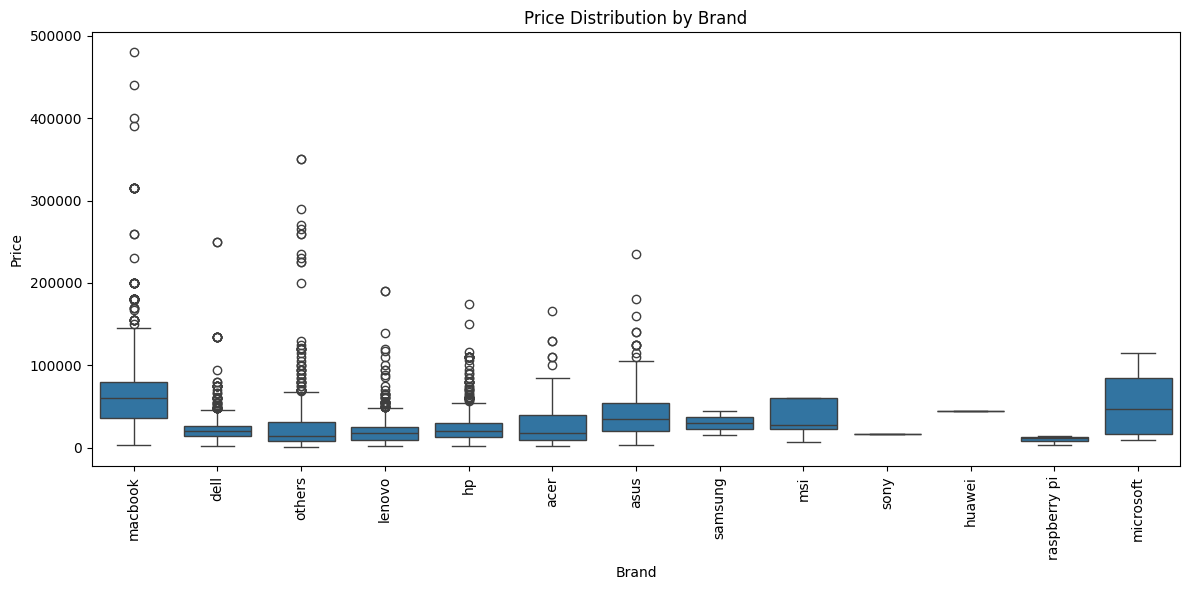

In [8]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=data, x='Brand', y='Price')

plt.xticks(rotation=90)
plt.title('Price Distribution by Brand')
plt.xlabel('Brand')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

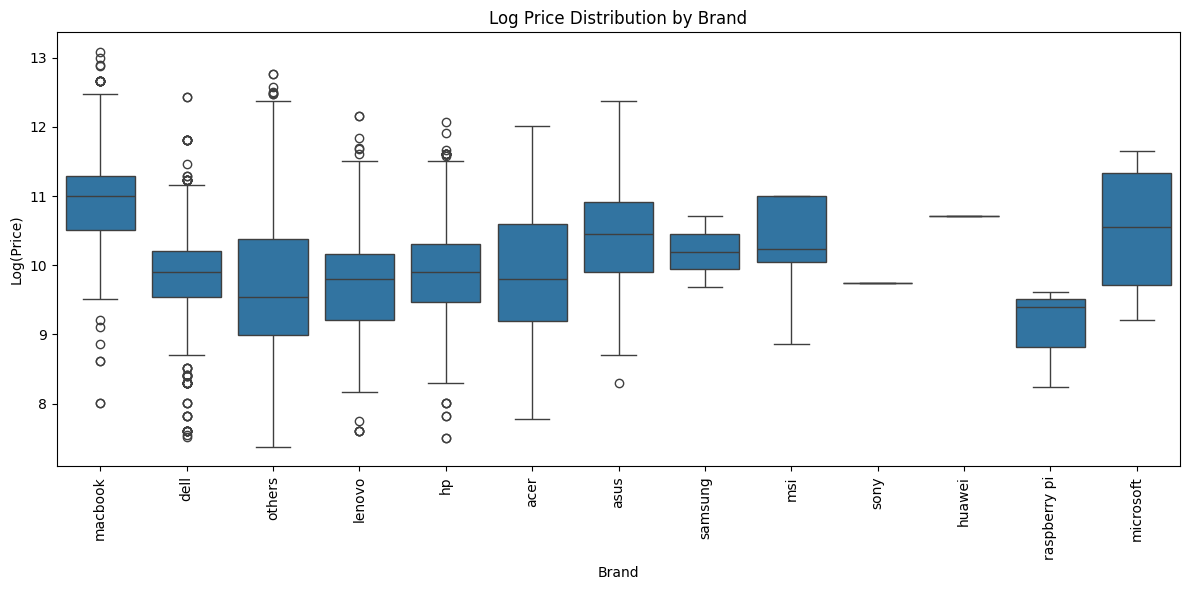

In [9]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=data, x='Brand', y=np.log(data['Price']))

plt.xticks(rotation=90)
plt.title('Log Price Distribution by Brand')
plt.xlabel('Brand')
plt.ylabel('Log(Price)')
plt.tight_layout()
plt.show()

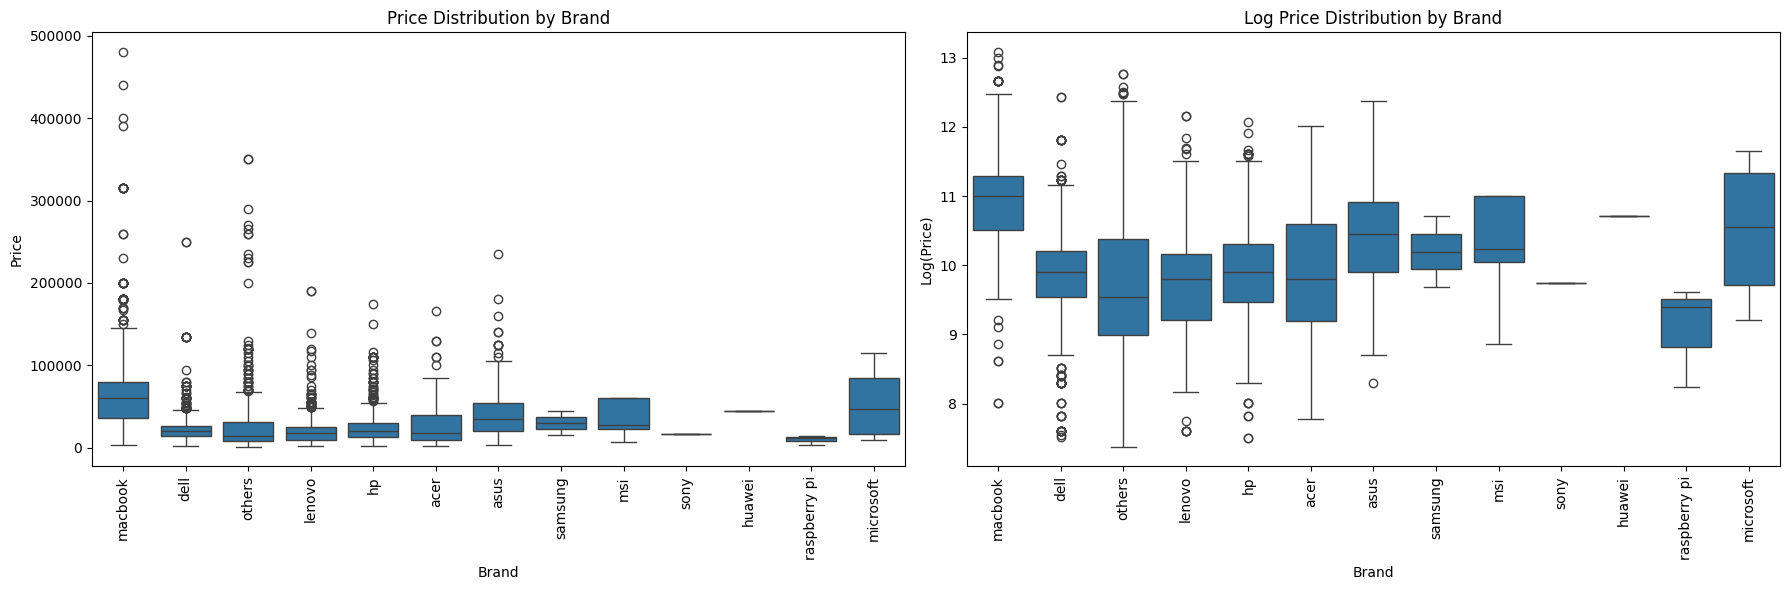

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Price Distribution by Brand
sns.boxplot(data=data, x='Brand', y='Price', ax=axes[0])

axes[0].tick_params(axis='x', rotation=90)
axes[0].set_title('Price Distribution by Brand')
axes[0].set_xlabel('Brand')
axes[0].set_ylabel('Price')

# 2. Log Price Distribution by Brand
sns.boxplot(data=data, x='Brand', y=np.log(data['Price']), ax=axes[1])

axes[1].tick_params(axis='x', rotation=90)
axes[1].set_title('Log Price Distribution by Brand')
axes[1].set_xlabel('Brand')
axes[1].set_ylabel('Log(Price)')

# Adjust layout
plt.tight_layout()
plt.show()

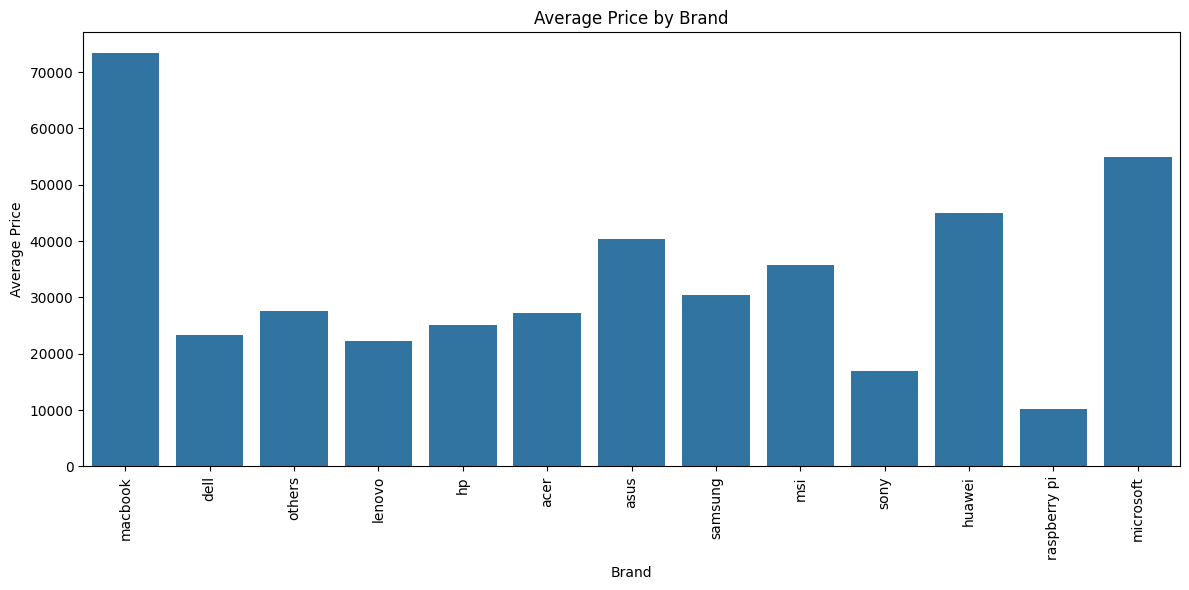

In [11]:
plt.figure(figsize=(12, 6))

sns.barplot(data=data, x='Brand', y='Price', errorbar=None)

plt.xticks(rotation=90)
plt.title('Average Price by Brand')
plt.xlabel('Brand')
plt.ylabel('Average Price')
plt.tight_layout()
plt.show()

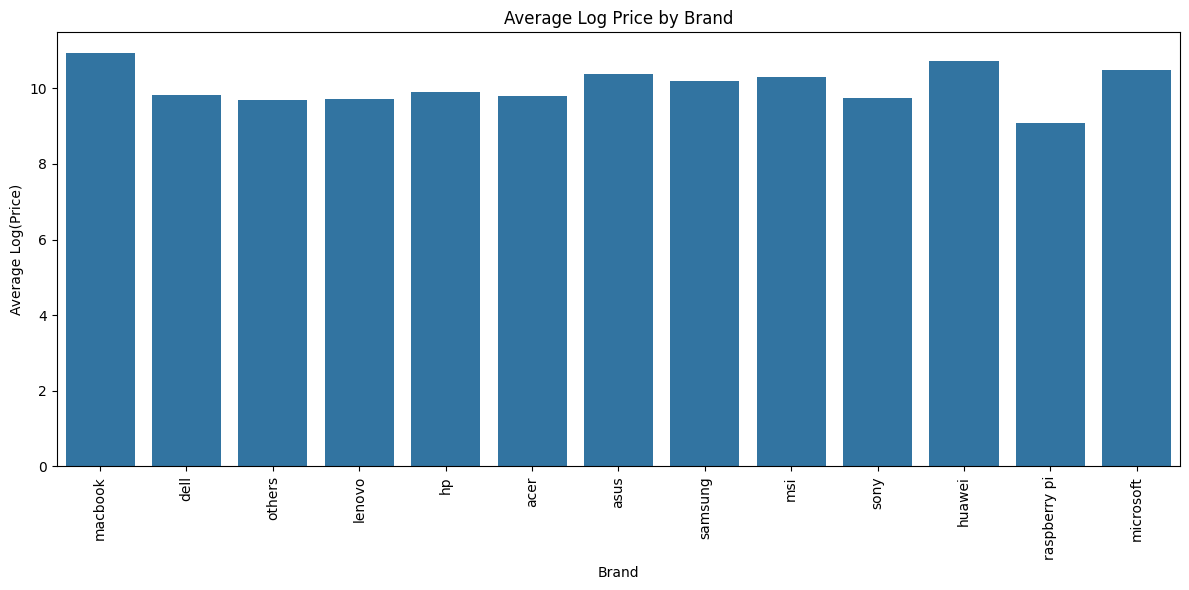

In [12]:
plt.figure(figsize=(12, 6))

sns.barplot(data=data, x='Brand', y=np.log(data['Price']), errorbar=None)

plt.xticks(rotation=90)
plt.title('Average Log Price by Brand')
plt.xlabel('Brand')
plt.ylabel('Average Log(Price)')
plt.tight_layout()
plt.show()

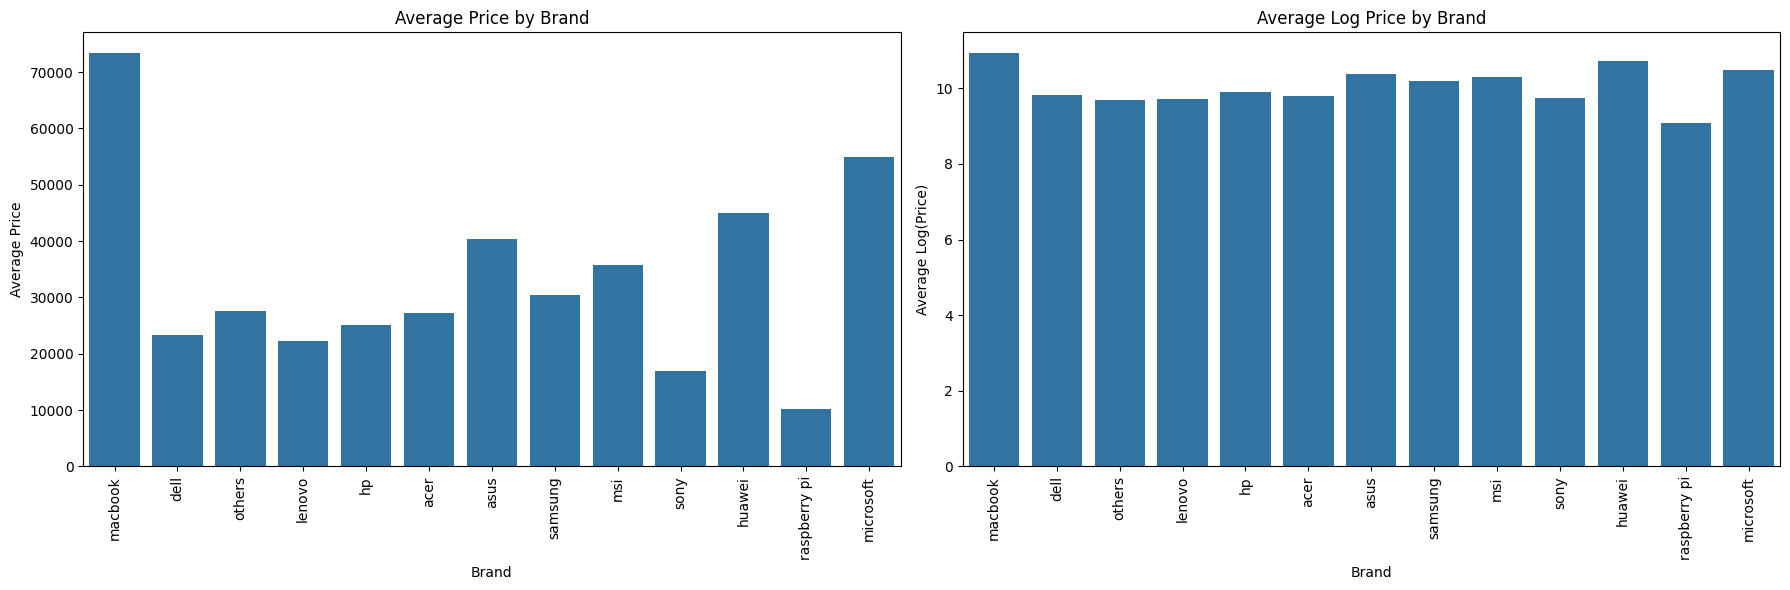

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Average Price by Brand
sns.barplot(data=data, x='Brand', y='Price', errorbar=None, ax=axes[0])

axes[0].tick_params(axis='x', rotation=90)
axes[0].set_title('Average Price by Brand')
axes[0].set_xlabel('Brand')
axes[0].set_ylabel('Average Price')

# 2. Average Log Price by Brand
sns.barplot(data=data, x='Brand', y=np.log(data['Price']), errorbar=None, ax=axes[1])

axes[1].tick_params(axis='x', rotation=90)
axes[1].set_title('Average Log Price by Brand')
axes[1].set_xlabel('Brand')
axes[1].set_ylabel('Average Log(Price)')

# Adjust layout
plt.tight_layout()
plt.show()

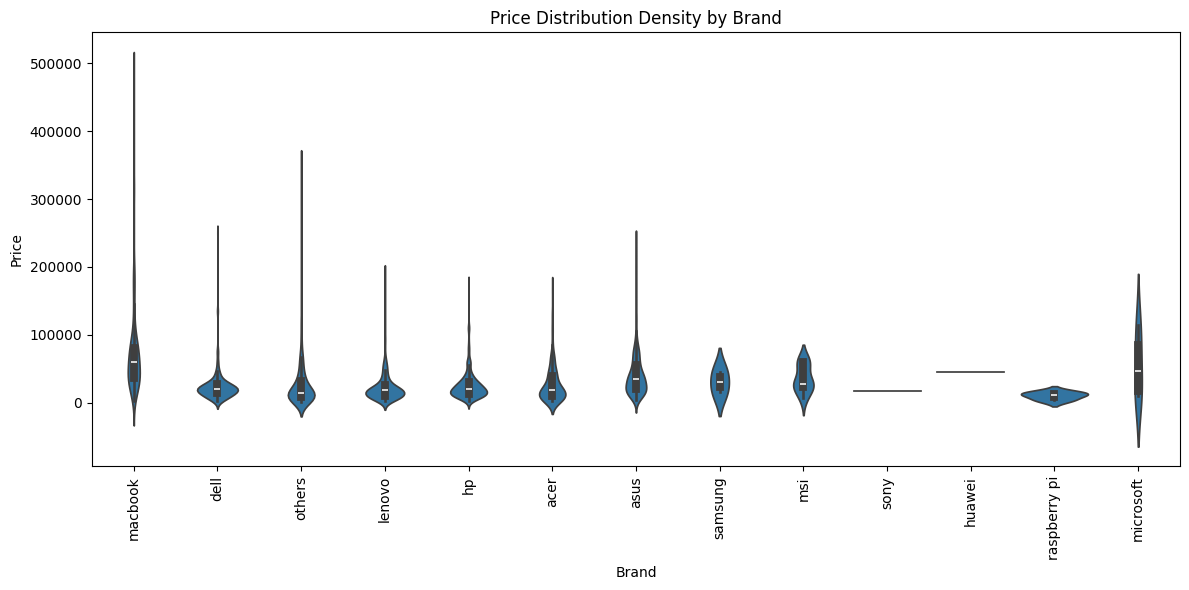

In [14]:
plt.figure(figsize=(12, 6))

sns.violinplot(data=data, x='Brand', y='Price')

plt.xticks(rotation=90)
plt.title('Price Distribution Density by Brand')
plt.xlabel('Brand')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

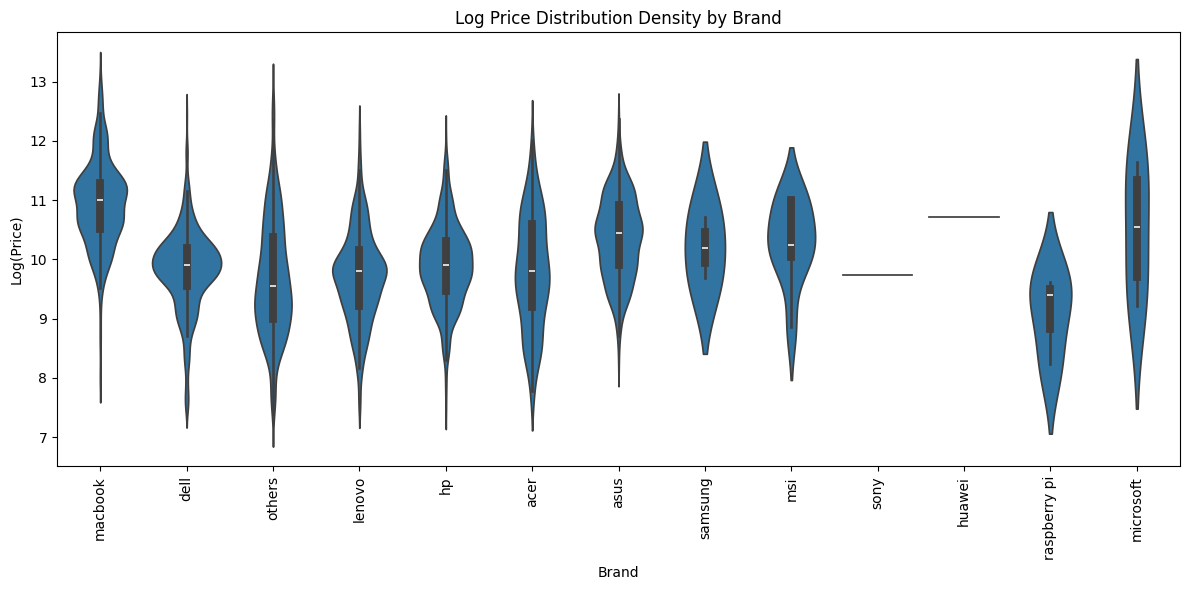

In [15]:
plt.figure(figsize=(12, 6))

sns.violinplot(data=data, x='Brand', y=np.log(data['Price']))

plt.xticks(rotation=90)
plt.title('Log Price Distribution Density by Brand')
plt.xlabel('Brand')
plt.ylabel('Log(Price)')
plt.tight_layout()
plt.show()

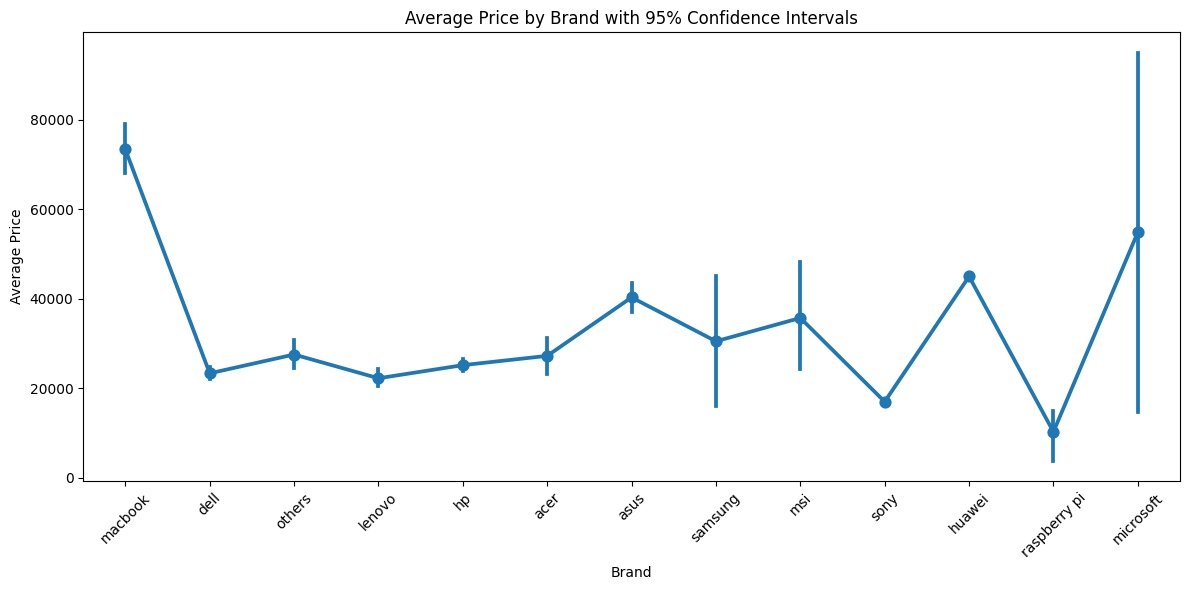

In [16]:
plt.figure(figsize=(12, 6))

sns.pointplot(data=data, x='Brand', y='Price', errorbar=('ci', 95))

plt.xticks(rotation=45)
plt.title('Average Price by Brand with 95% Confidence Intervals')
plt.xlabel('Brand')
plt.ylabel('Average Price')
plt.tight_layout()
plt.show()

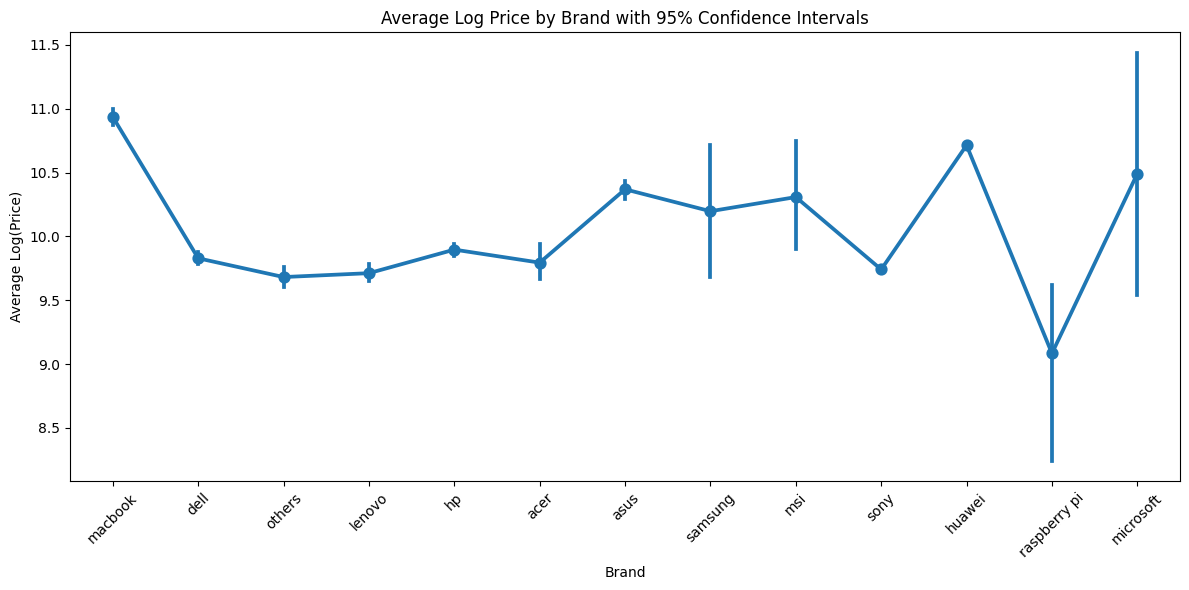

In [17]:
plt.figure(figsize=(12, 6))

sns.pointplot(data=data, x='Brand', y=np.log(data['Price']), errorbar=('ci', 95))

plt.xticks(rotation=45)
plt.title('Average Log Price by Brand with 95% Confidence Intervals')
plt.xlabel('Brand')
plt.ylabel('Average Log(Price)')
plt.tight_layout()
plt.show()

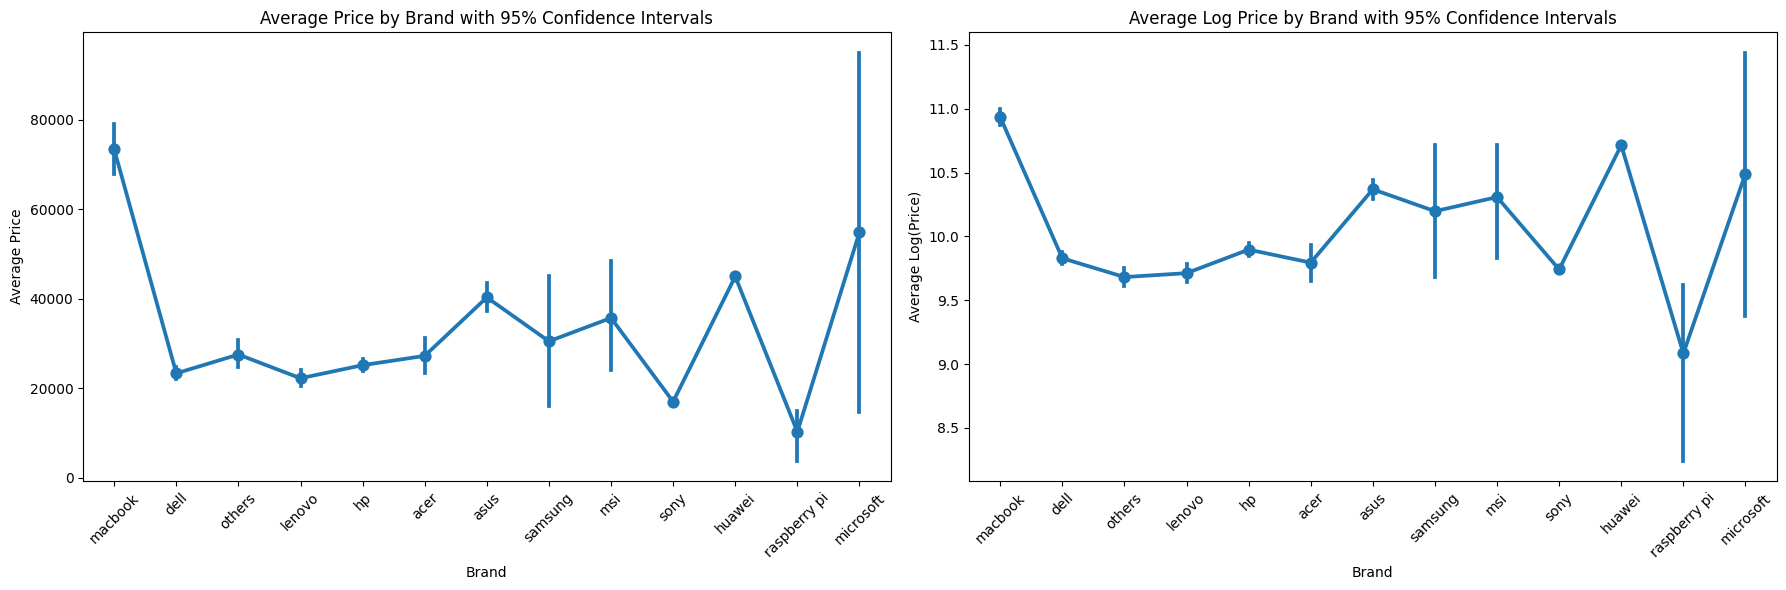

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Average Price by Brand with 95% Confidence Intervals
sns.pointplot(
    data=data,
    x='Brand',
    y='Price',
    errorbar=('ci', 95),
    ax=axes[0]
)

axes[0].tick_params(axis='x', rotation=45)
axes[0].set_title('Average Price by Brand with 95% Confidence Intervals')
axes[0].set_xlabel('Brand')
axes[0].set_ylabel('Average Price')

# 2. Average Log Price by Brand with 95% Confidence Intervals
sns.pointplot(
    data=data,
    x='Brand',
    y=np.log(data['Price']),
    errorbar=('ci', 95),
    ax=axes[1]
)

axes[1].tick_params(axis='x', rotation=45)
axes[1].set_title('Average Log Price by Brand with 95% Confidence Intervals')
axes[1].set_xlabel('Brand')
axes[1].set_ylabel('Average Log(Price)')

# Adjust layout
plt.tight_layout()
plt.show()

In [19]:
df = data[['Brand', 'Price']].dropna().copy()

# Overall mean of Price
overall_mean = df['Price'].mean()

# Total sum of squares
total_ss = ((df['Price'] - overall_mean) ** 2).sum()

# Between-group sum of squares
group_means = df.groupby('Brand')['Price'].mean()
group_counts = df.groupby('Brand')['Price'].count()

between_ss = (
    group_counts * (group_means - overall_mean) ** 2
).sum()

# Correlation ratio (Eta)
eta = np.sqrt(between_ss / total_ss) if total_ss > 0 else np.nan

print("Correlation Ratio (Eta):", eta)

Correlation Ratio (Eta): 0.44029239329516306


In [20]:
interpret_eta(eta, "Brand")

Moderate association between Brand and Price.


# Bivariate Exploratory Data Analysis (EDA) - Type vs. Price

## 1. Summary Statistics and Data Integrity

- **Data Overview:** The subset containing `Type` and `Price` has 3,829 non-null entries with no missing values. `Type` is a categorical feature (`object`), while `Price` is a continuous numerical feature (`float64`).

- **Price Distribution Across Product Types:**

  - **Laptop:**
    - Count: 2,866
    - Mean Price: 33,996.25
    - Median Price: 23,500.00
    - Minimum Price: 1,599.00
    - Maximum Price: 480,000.00
    - Standard Deviation: 36,853.62

  - **Computer:**
    - Count: 963
    - Mean Price: 29,323.72
    - Median Price: 16,000.00
    - Minimum Price: 1,850.00
    - Maximum Price: 399,999.00
    - Standard Deviation: 40,896.67

- **Central Tendency:** Laptops have a higher mean and median price than computers. However, both categories show considerable price variability.

- **Price Variability:** Computers have a higher standard deviation than laptops, indicating greater absolute variation in their prices.

## 2. Visualization Analysis

### Box Plots - Original Price vs. Log Price

The original price box plots show substantial right-skewness in both product categories, with high-priced outliers extending beyond 300,000.

The log-transformed price box plots compress extreme values and make the central distributions easier to compare. They help illustrate differences in typical prices and spread between laptops and computers.

### Bar Charts - Average Price vs. Average Log Price

The average price bar chart shows that laptops have a higher mean price than computers.

The average log-price chart provides a comparison on a compressed scale, making differences in log-transformed prices easier to observe. However, the mean of log prices is not equivalent to the log of mean prices.

### Violin Plots - Price Distribution Density

The violin plots show that both laptops and computers have substantial concentrations of listings in the lower-to-middle price ranges, with long tails extending toward premium products.

These distributions indicate that both product categories contain a wide range of price levels, from relatively inexpensive systems to high-end configurations.

## 3. Statistical Analysis - Correlation Ratio (Eta)

- **Method:** The correlation ratio (Eta) measures the association between a categorical feature and a numerical variable.

  \[
  \eta = \sqrt{\frac{SS_{\text{between}}}{SS_{\text{total}}}}
  \]

- **Eta:** 0.0534

- **Eta Squared:**

  \[
  \eta^2 = 0.0534^2 \approx 0.00285
  \]

- **Interpretation:** The Eta value indicates a very weak association between `Type` and `Price`.

- **Explained Variation:** The squared Eta value suggests that approximately 0.285% of the observed price variation is associated with differences between the Laptop and Computer groups.

This indicates that product type alone explains very little of the variation in prices in this dataset.

## 4. Key Takeaways and Data Modeling Recommendations

- **Limited Standalone Predictive Power:** The low Eta value suggests that `Type` alone has a weak association with `Price`. However, this does not mean the feature is necessarily useless in a multivariable model.

- **Feature Interactions:** Examine `Type` alongside `Brand`, `RAM_GB`, `Storage_Type`, `Screen_Size`, and `Processor_Tier` to determine whether its usefulness depends on other product specifications.

- **Log Transformation:** Since both categories show right-skewed price distributions, consider evaluating `log1p(Price)` as an alternative regression target. Compare its performance against a model trained on raw prices.

- **Outlier Analysis:** Investigate unusually high-priced products to determine whether they are valid premium listings or data-entry errors. Do not remove them without sufficient evidence.

- **Model Evaluation:** Use cross-validation and appropriate regression metrics, such as MAE and RMSE, to determine whether including `Type` improves prediction performance.

## 5. Conclusion

The bivariate analysis shows that laptops have higher mean and median prices than computers in the reported sample. However, the correlation ratio of 0.0534 indicates a very weak overall association between product type and price, with approximately 0.285% of observed price variation associated with differences between the two categories.

Therefore, `Type` should not be relied upon as a standalone predictor. Its potential contribution should be evaluated alongside hardware specifications and brand information in a multivariable laptop and computer price prediction model.

In [21]:
sns.set_style('whitegrid')

In [22]:
data[['Type', 'Price']].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3829 entries, 0 to 3828
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Type    3829 non-null   object 
 1   Price   3829 non-null   float64
dtypes: float64(1), object(1)
memory usage: 60.0+ KB


In [23]:
data.groupby('Type')['Price'].agg([
    'count',
    'mean',
    'median',
    'min',
    'max',
    'std'
]).sort_values(by='mean', ascending=False)

,count,mean,median,min,max,std
Type,,,,,,
Laptop,2866,33996.247383,23500.0,1599.0,480000.0,36853.619214
Computer,963,29323.722741,16000.0,1850.0,399999.0,40896.665456


In [24]:
data['Type'].value_counts()

,count
Type,
Laptop,2866
Computer,963


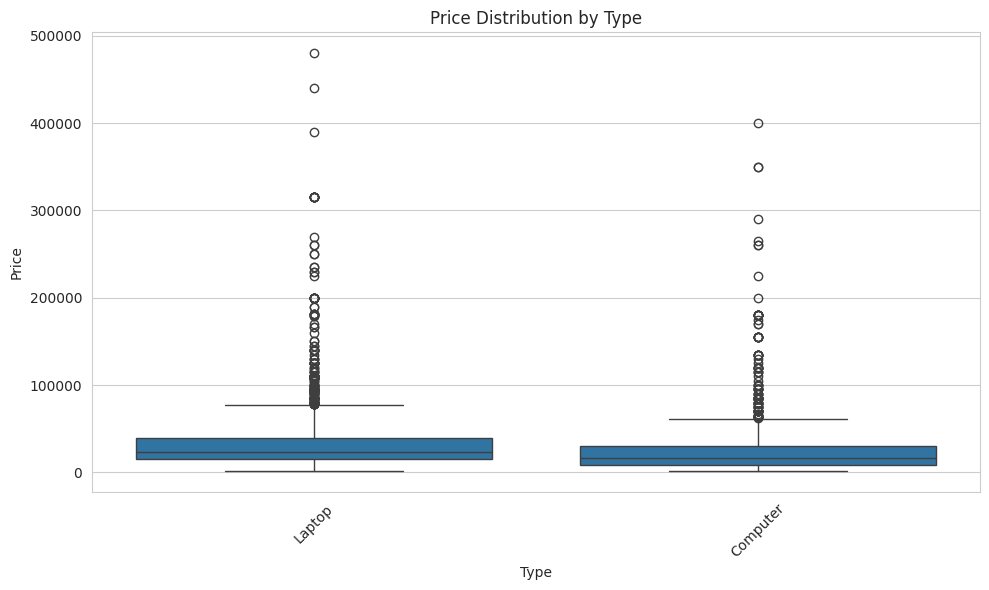

In [25]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=data, x='Type', y='Price')

plt.title('Price Distribution by Type')
plt.xlabel('Type')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

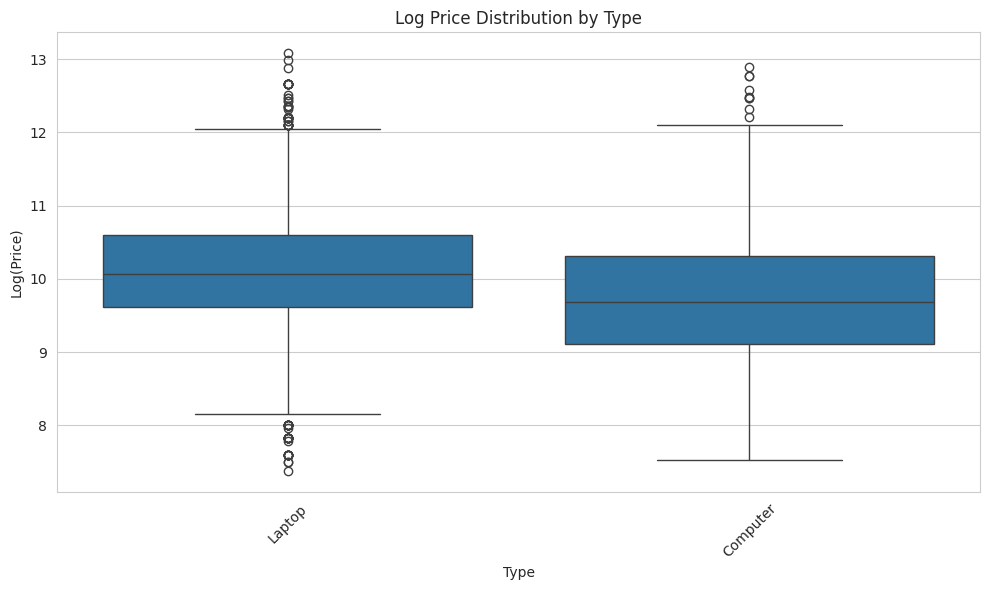

In [26]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=data, x='Type', y=np.log(data['Price']))

plt.title('Log Price Distribution by Type')
plt.xlabel('Type')
plt.ylabel('Log(Price)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

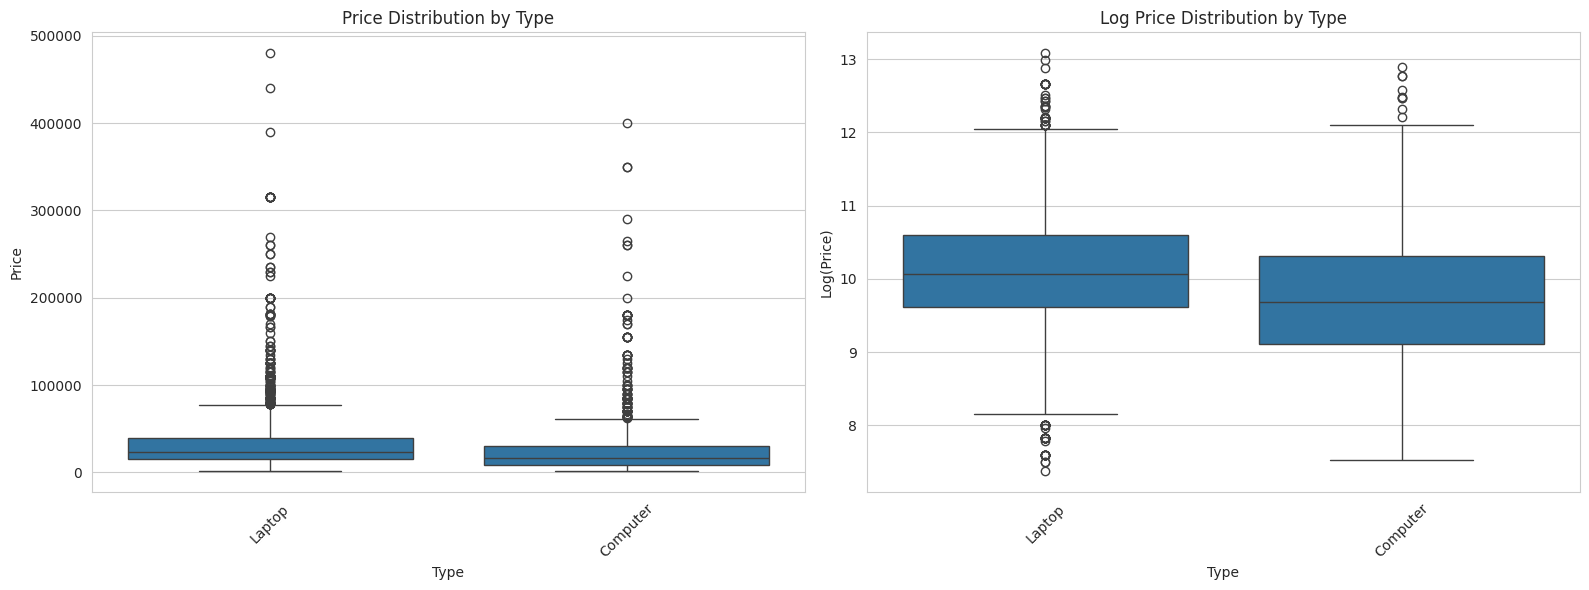

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Price Distribution by Type
sns.boxplot(data=data, x='Type', y='Price', ax=axes[0])

axes[0].set_title('Price Distribution by Type')
axes[0].set_xlabel('Type')
axes[0].set_ylabel('Price')
axes[0].tick_params(axis='x', rotation=45)

# 2. Log Price Distribution by Type
sns.boxplot(data=data, x='Type', y=np.log(data['Price']), ax=axes[1])

axes[1].set_title('Log Price Distribution by Type')
axes[1].set_xlabel('Type')
axes[1].set_ylabel('Log(Price)')
axes[1].tick_params(axis='x', rotation=45)

# Adjust layout
plt.tight_layout()
plt.show()

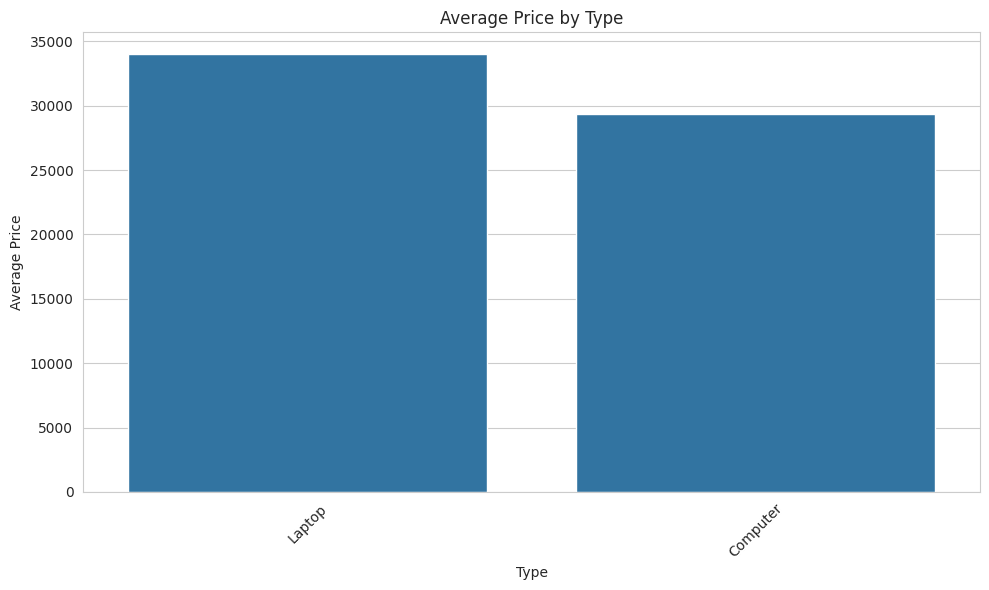

In [28]:
plt.figure(figsize=(10, 6))

sns.barplot(data=data, x='Type', y='Price', errorbar=None)

plt.title('Average Price by Type')
plt.xlabel('Type')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

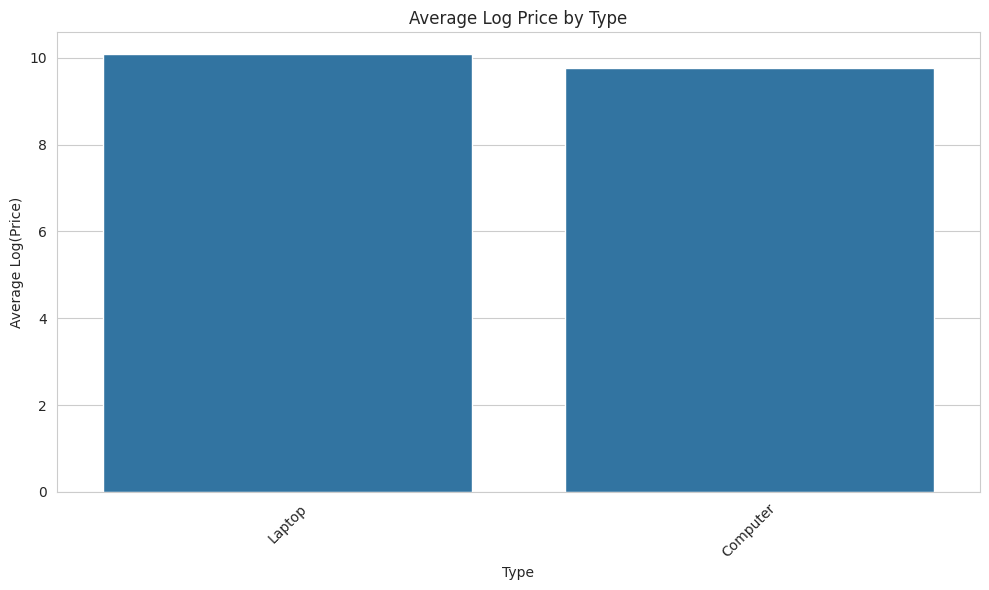

In [29]:
plt.figure(figsize=(10, 6))

sns.barplot(data=data, x='Type', y=np.log(data['Price']), errorbar=None)

plt.title('Average Log Price by Type')
plt.xlabel('Type')
plt.ylabel('Average Log(Price)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

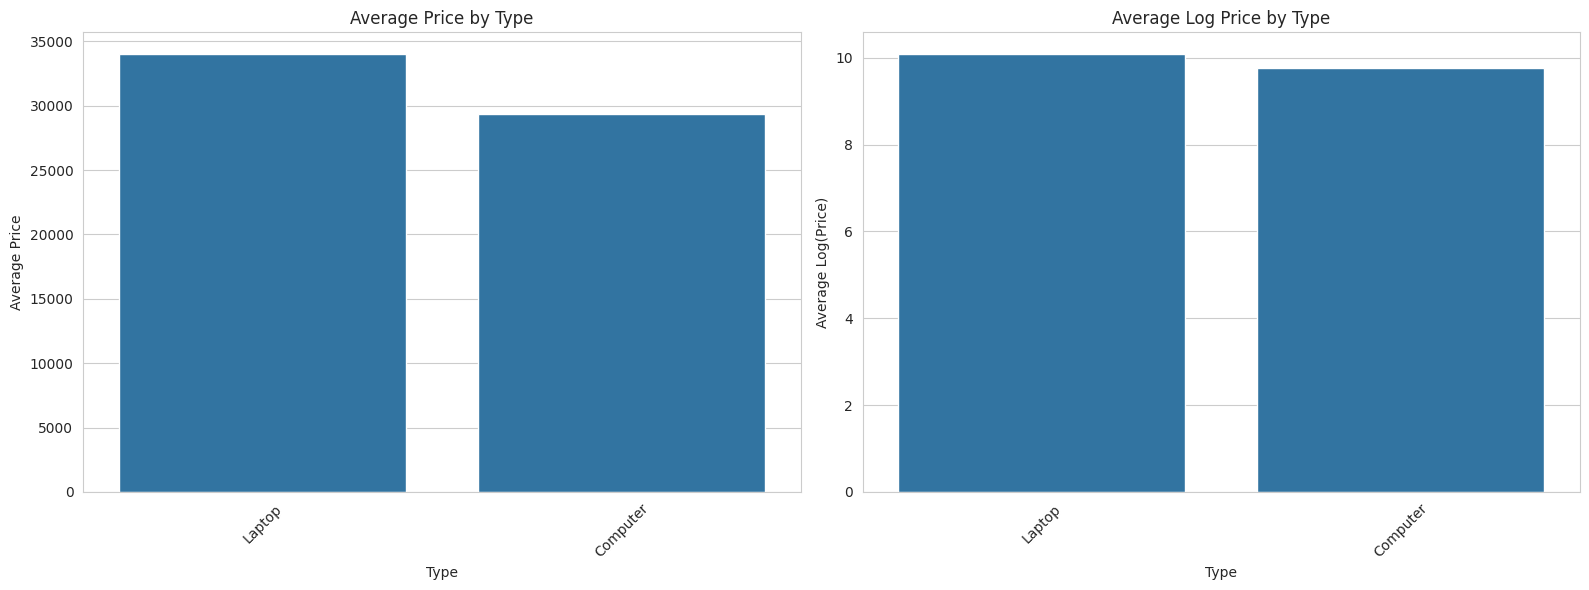

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Average Price by Type
sns.barplot(
    data=data,
    x='Type',
    y='Price',
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title('Average Price by Type')
axes[0].set_xlabel('Type')
axes[0].set_ylabel('Average Price')
axes[0].tick_params(axis='x', rotation=45)

# 2. Average Log Price by Type
sns.barplot(
    data=data,
    x='Type',
    y=np.log(data['Price']),
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title('Average Log Price by Type')
axes[1].set_xlabel('Type')
axes[1].set_ylabel('Average Log(Price)')
axes[1].tick_params(axis='x', rotation=45)

# Adjust layout
plt.tight_layout()
plt.show()

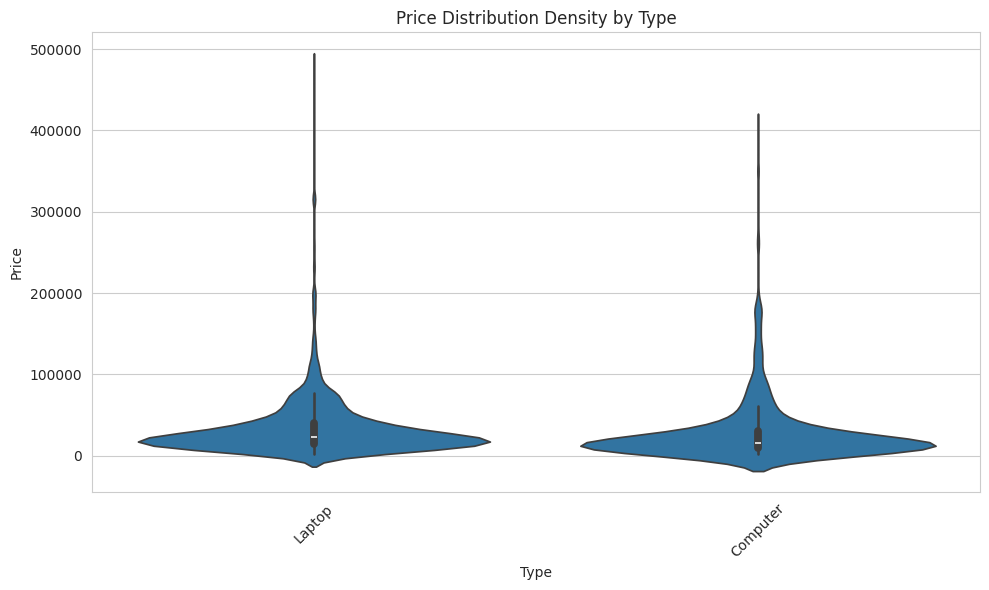

In [31]:
plt.figure(figsize=(10, 6))

sns.violinplot(data=data, x='Type', y='Price')

plt.title('Price Distribution Density by Type')
plt.xlabel('Type')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

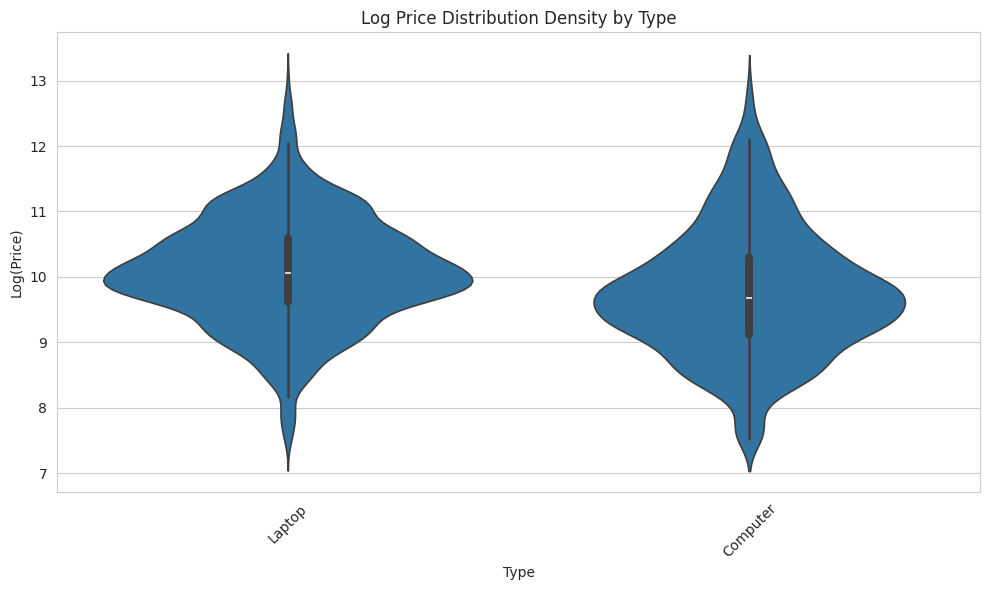

In [32]:
plt.figure(figsize=(10, 6))

sns.violinplot(data=data, x='Type', y=np.log(data['Price']))

plt.title('Log Price Distribution Density by Type')
plt.xlabel('Type')
plt.ylabel('Log(Price)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

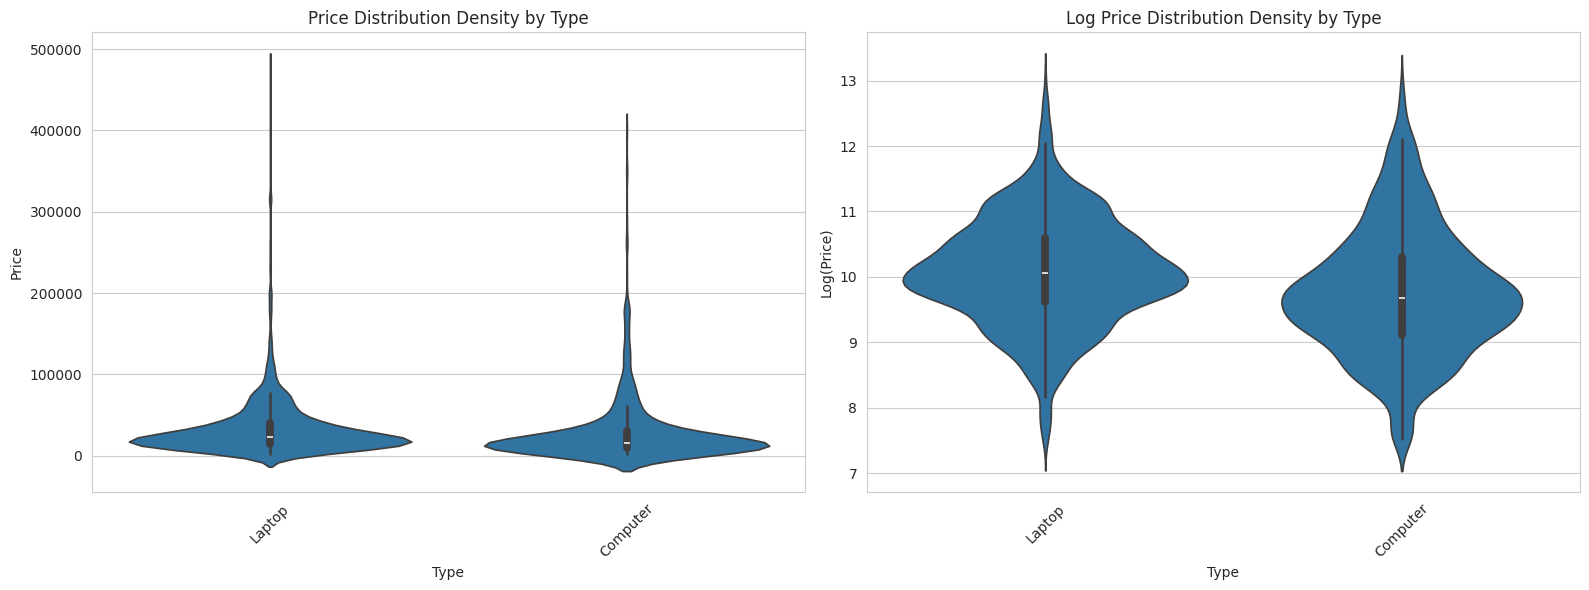

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Price Distribution Density by Type
sns.violinplot(
    data=data,
    x='Type',
    y='Price',
    ax=axes[0]
)

axes[0].set_title('Price Distribution Density by Type')
axes[0].set_xlabel('Type')
axes[0].set_ylabel('Price')
axes[0].tick_params(axis='x', rotation=45)

# 2. Log Price Distribution Density by Type
sns.violinplot(
    data=data,
    x='Type',
    y=np.log(data['Price']),
    ax=axes[1]
)

axes[1].set_title('Log Price Distribution Density by Type')
axes[1].set_xlabel('Type')
axes[1].set_ylabel('Log(Price)')
axes[1].tick_params(axis='x', rotation=45)

# Adjust layout
plt.tight_layout()
plt.show()

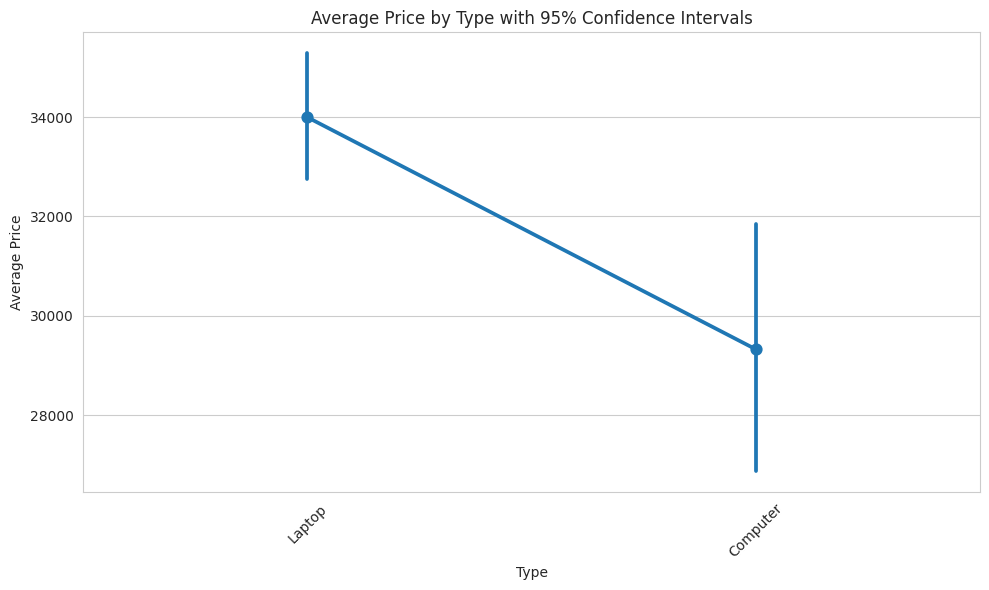

In [34]:
plt.figure(figsize=(10, 6))

sns.pointplot(
    data=data,
    x='Type',
    y='Price',
    errorbar=('ci', 95)
)

plt.title('Average Price by Type with 95% Confidence Intervals')
plt.xlabel('Type')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


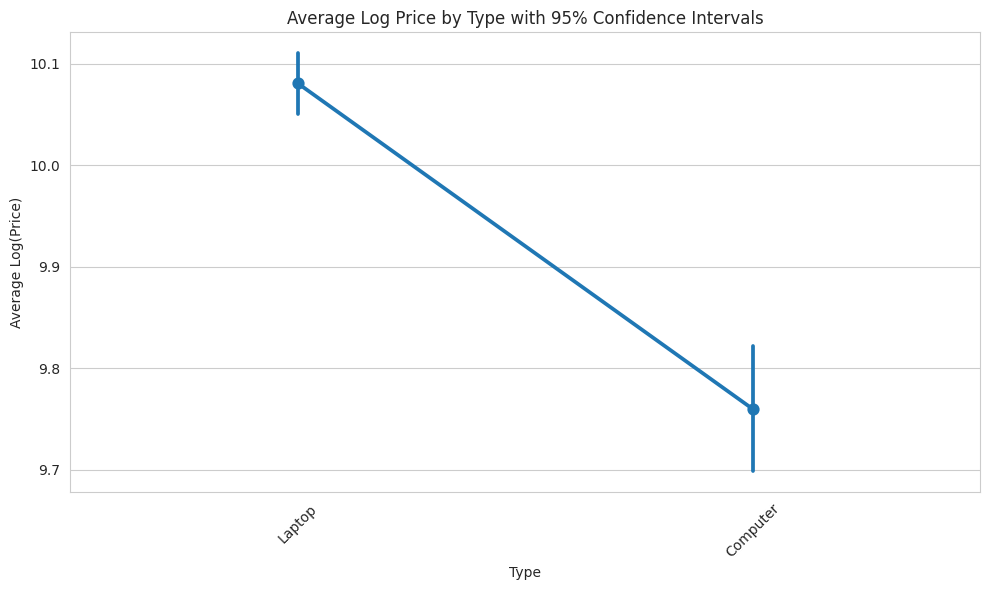

In [35]:
plt.figure(figsize=(10, 6))

sns.pointplot(
    data=data,
    x='Type',
    y=np.log(data['Price']),
    errorbar=('ci', 95)
)

plt.title('Average Log Price by Type with 95% Confidence Intervals')
plt.xlabel('Type')
plt.ylabel('Average Log(Price)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
# Remove rows with missing values
df = data[['Type', 'Price']].dropna().copy()

# Calculate overall mean price
overall_mean = df['Price'].mean()

# Calculate total sum of squares
total_ss = ((df['Price'] - overall_mean) ** 2).sum()

# Calculate mean price and count for each type
group_means = df.groupby('Type')['Price'].mean()
group_counts = df.groupby('Type')['Price'].count()

# Calculate between-group sum of squares
between_ss = (
    group_counts * (group_means - overall_mean) ** 2
).sum()

# Calculate Eta
if total_ss > 0:
    eta = np.sqrt(between_ss / total_ss)
else:
    eta = np.nan

print("Eta:", eta)

# Calculate Eta squared
if pd.notna(eta):
    print("Eta Squared:", eta ** 2)

Eta: 0.05341346867090369
Eta Squared: 0.0028529986354576104


In [37]:
interpret_eta(eta, "Type")

Very weak association between Type and Price.


# Bivariate Exploratory Data Analysis (EDA) - Has_Warranty vs. Price

## 1. Summary Statistics and Data Integrity

- **Data Overview:** The subset containing `Has_Warranty` and `Price` has 3,829 non-null entries with no missing values. `Has_Warranty` is a binary numerical feature (`int64`), while `Price` is a continuous numerical feature (`float64`).

- **Price Distribution Across Warranty Status:**

  - **Has Warranty (1):**
    - Count: 605
    - Mean Price: 50,993.07
    - Median Price: 28,500.00
    - Minimum Price: 2,000.00
    - Maximum Price: 480,000.00
    - Standard Deviation: 58,832.35

  - **No Warranty (0):**
    - Count: 3,224
    - Mean Price: 29,411.04
    - Median Price: 20,000.00
    - Minimum Price: 1,599.00
    - Maximum Price: 439,999.00
    - Standard Deviation: 31,450.92

- **Central Tendency:** Products with a warranty have a higher mean price and median price than products without a warranty.

- **Price Difference:** The average price of products with a warranty is approximately 1.73 times that of products without a warranty. This suggests that warranty availability is associated with higher-priced products in the dataset.

- **Category Imbalance:** Approximately 15.8% of the products have a warranty, while 84.2% do not.

## 2. Visualization Analysis

### Box Plots - Original Price vs. Log Price

The original price box plots show substantial right-skewness in both warranty categories, with high-priced products extending toward 480,000.

The log-transformed price box plots reduce the visual influence of extreme values and make the central distributions easier to compare. Products with a warranty show a higher median log price and an upward shift in their price distribution.

### Bar Charts - Average Price vs. Average Log Price

The average price bar chart shows that products with a warranty have a considerably higher mean price than products without a warranty.

The average log-price chart provides a comparison on a logarithmic scale and can help reveal differences in typical pricing patterns. However, the mean of log prices is not equivalent to the log of mean prices.

### Violin Plots - Price Distribution Density

The violin plots show that products without a warranty are concentrated more heavily in the lower price ranges, particularly below 50,000.

Products with a warranty exhibit a broader price distribution extending into higher price ranges. This suggests that warranty availability may be associated with premium product listings.

## 3. Statistical Analysis - Correlation Ratio (Eta)

- **Method:** The correlation ratio (Eta) measures the association between a categorical feature and a numerical variable.

  \[
  \eta = \sqrt{\frac{SS_{\text{between}}}{SS_{\text{total}}}}
  \]

- **Eta:** 0.2074

- **Eta Squared:**

  \[
  \eta^2 = 0.2074^2 \approx 0.0430
  \]

- **Interpretation:** The Eta value indicates a weak association between `Has_Warranty` and `Price`.

- **Explained Variation:** Approximately 4.30% of the observed price variation is associated with differences between the warranty and no-warranty groups.

This is a descriptive measure of association and does not establish that having a warranty causes a higher price.

## 4. Key Takeaways and Data Modeling Recommendations

- **Positive Price Association:** Products with a warranty have higher mean and median prices in the reported sample. This may reflect differences in product quality, specifications, brand, or seller practices.

- **Predictive Value:** Although the association is weak overall, `Has_Warranty` may still provide useful information when combined with other features.

- **Feature Encoding:** Since `Has_Warranty` is already represented as 0 and 1, it can generally be retained as a binary numerical feature.

- **Feature Interactions:** Examine `Has_Warranty` alongside `Brand`, `RAM_GB`, `Storage_GB`, `Screen_Size`, and `Processor_Tier` to determine whether warranty status provides additional predictive information.

- **Model Evaluation:** Compare model performance with and without this feature using cross-validation to determine its actual contribution to price prediction.

- **Outlier Analysis:** Investigate unusually expensive products in both groups before deciding whether any records require correction or removal.

## 5. Conclusion

The bivariate analysis shows that products with a warranty have a higher mean price of 50,993.07 and a higher median price of 28,500 compared with products without a warranty, which have a mean price of 29,411.04 and a median price of 20,000.

The correlation ratio of approximately 0.2074 indicates a weak association between warranty availability and price, with around 4.30% of observed price variation associated with the difference between the two groups.

Therefore, `Has_Warranty` can be retained as a potential predictor in laptop and computer price prediction models. Its usefulness should be evaluated alongside brand, hardware specifications, and other relevant features.

In [38]:
data['Has_Warranty'] = data['Has_Warranty'].astype('int')

In [39]:
data['Has_Warranty'].value_counts()

,count
Has_Warranty,
0,3224
1,605


In [40]:
data[['Has_Warranty', 'Price']].head()

,Has_Warranty,Price
0,0,65000.0
1,0,24999.0
2,0,5500.0
3,1,18000.0
4,0,10000.0


In [41]:
data[['Has_Warranty', 'Price']].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3829 entries, 0 to 3828
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Has_Warranty  3829 non-null   int64  
 1   Price         3829 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 60.0 KB


In [42]:
data.groupby('Has_Warranty')['Price'].agg([
    'count',
    'mean',
    'median',
    'min',
    'max',
    'std'
]).sort_values(by='mean', ascending=False)

,count,mean,median,min,max,std
Has_Warranty,,,,,,
1,605,50993.071074,28500.0,2000.0,480000.0,58832.353375
0,3224,29411.036600,20000.0,1599.0,439999.0,31450.919135


In [43]:
data['Has_Warranty'].value_counts()

,count
Has_Warranty,
0,3224
1,605


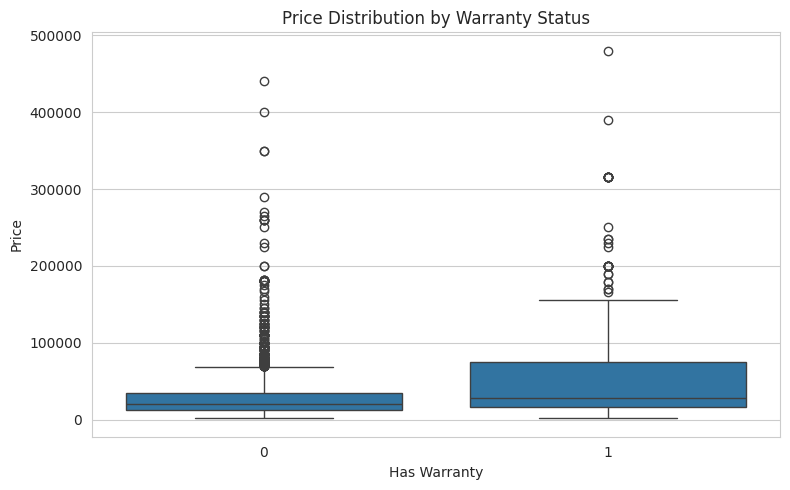

In [44]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=data, x='Has_Warranty', y='Price')

plt.title('Price Distribution by Warranty Status')
plt.xlabel('Has Warranty')
plt.ylabel('Price')

plt.tight_layout()
plt.show()

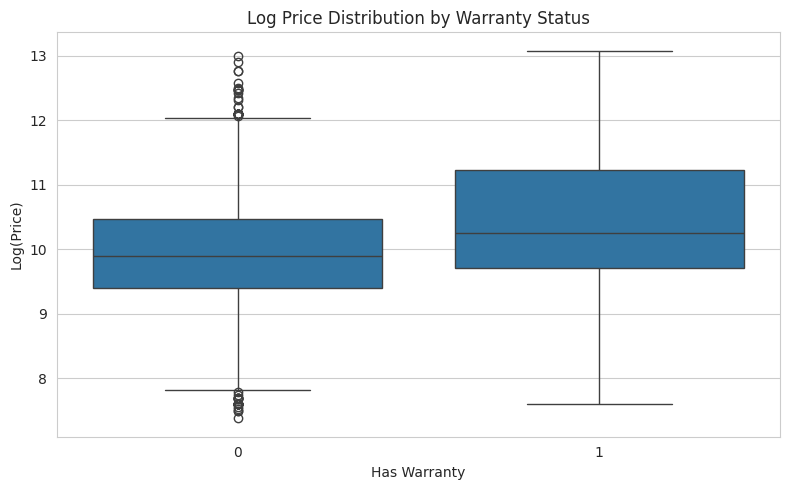

In [45]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=data, x='Has_Warranty', y=np.log(data['Price']))

plt.title('Log Price Distribution by Warranty Status')
plt.xlabel('Has Warranty')
plt.ylabel('Log(Price)')

plt.tight_layout()
plt.show()

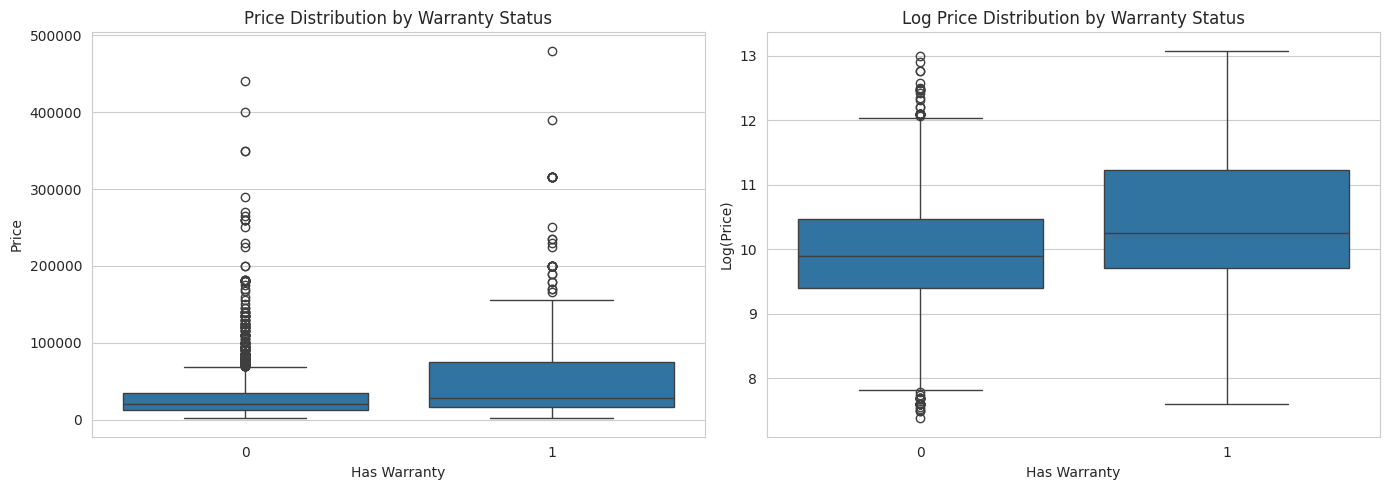

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Price Distribution by Warranty Status
sns.boxplot(
    data=data,
    x='Has_Warranty',
    y='Price',
    ax=axes[0]
)

axes[0].set_title('Price Distribution by Warranty Status')
axes[0].set_xlabel('Has Warranty')
axes[0].set_ylabel('Price')

# 2. Log Price Distribution by Warranty Status
sns.boxplot(
    data=data,
    x='Has_Warranty',
    y=np.log(data['Price']),
    ax=axes[1]
)

axes[1].set_title('Log Price Distribution by Warranty Status')
axes[1].set_xlabel('Has Warranty')
axes[1].set_ylabel('Log(Price)')

# Adjust layout
plt.tight_layout()
plt.show()

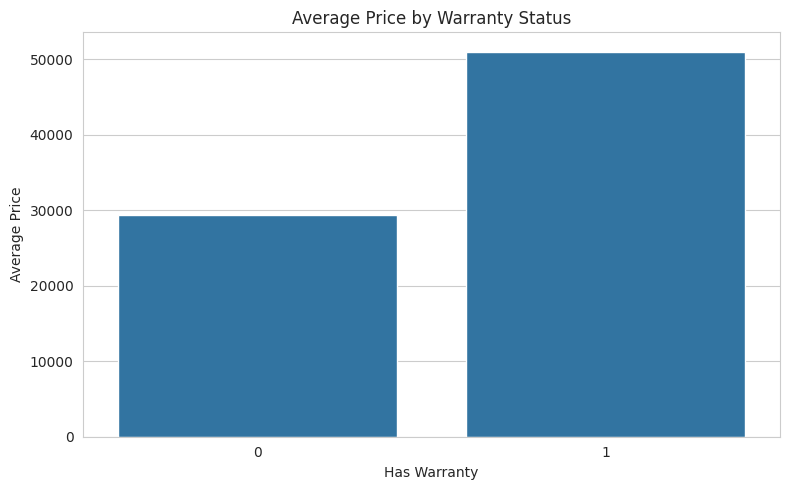

In [47]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=data,
    x='Has_Warranty',
    y='Price',
    errorbar=None
)

plt.title('Average Price by Warranty Status')
plt.xlabel('Has Warranty')
plt.ylabel('Average Price')

plt.tight_layout()
plt.show()

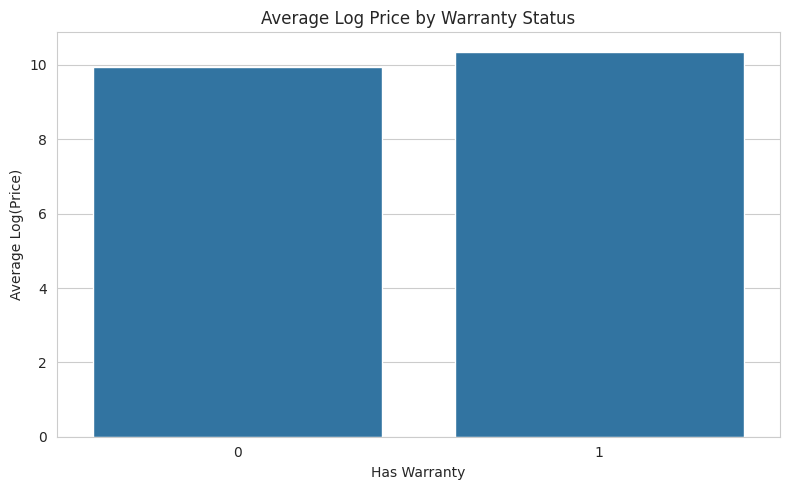

In [48]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=data,
    x='Has_Warranty',
    y=np.log(data['Price']),
    errorbar=None
)

plt.title('Average Log Price by Warranty Status')
plt.xlabel('Has Warranty')
plt.ylabel('Average Log(Price)')

plt.tight_layout()
plt.show()

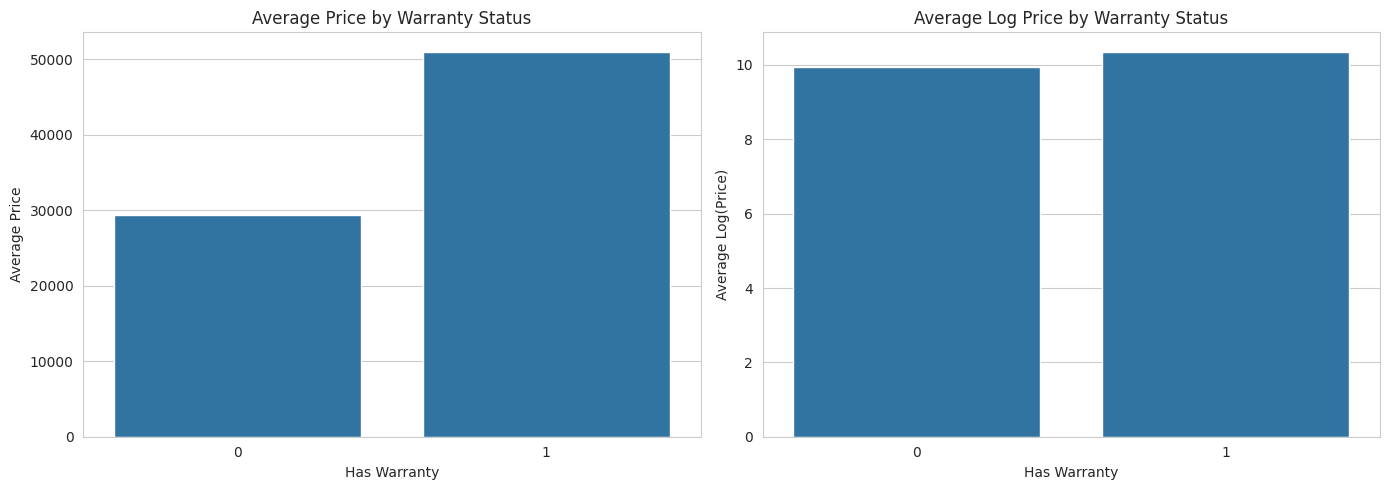

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Average Price by Warranty Status
sns.barplot(
    data=data,
    x='Has_Warranty',
    y='Price',
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title('Average Price by Warranty Status')
axes[0].set_xlabel('Has Warranty')
axes[0].set_ylabel('Average Price')

# 2. Average Log Price by Warranty Status
sns.barplot(
    data=data,
    x='Has_Warranty',
    y=np.log(data['Price']),
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title('Average Log Price by Warranty Status')
axes[1].set_xlabel('Has Warranty')
axes[1].set_ylabel('Average Log(Price)')

# Adjust layout
plt.tight_layout()
plt.show()

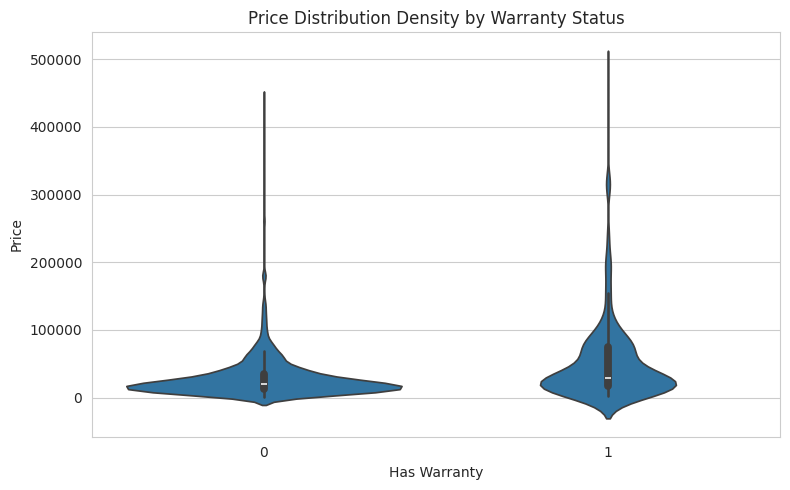

In [50]:
plt.figure(figsize=(8, 5))

sns.violinplot(data=data, x='Has_Warranty', y='Price')

plt.title('Price Distribution Density by Warranty Status')
plt.xlabel('Has Warranty')
plt.ylabel('Price')

plt.tight_layout()
plt.show()

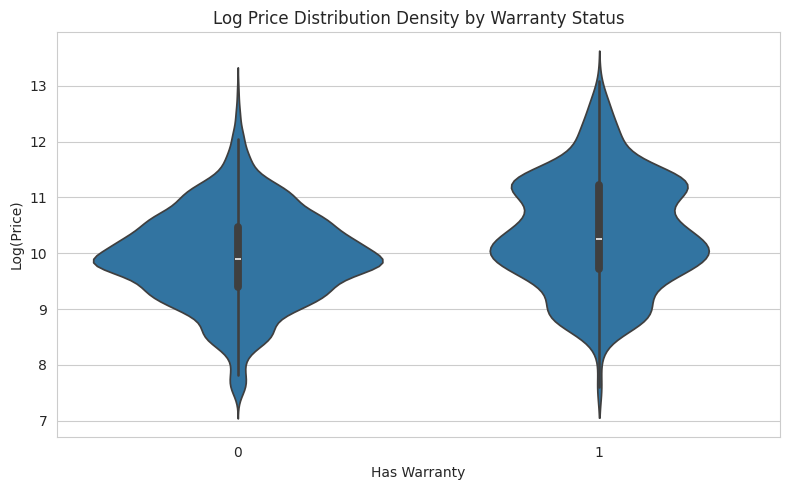

In [51]:
plt.figure(figsize=(8, 5))

sns.violinplot(data=data, x='Has_Warranty', y=np.log(data['Price']))

plt.title('Log Price Distribution Density by Warranty Status')
plt.xlabel('Has Warranty')
plt.ylabel('Log(Price)')

plt.tight_layout()
plt.show()

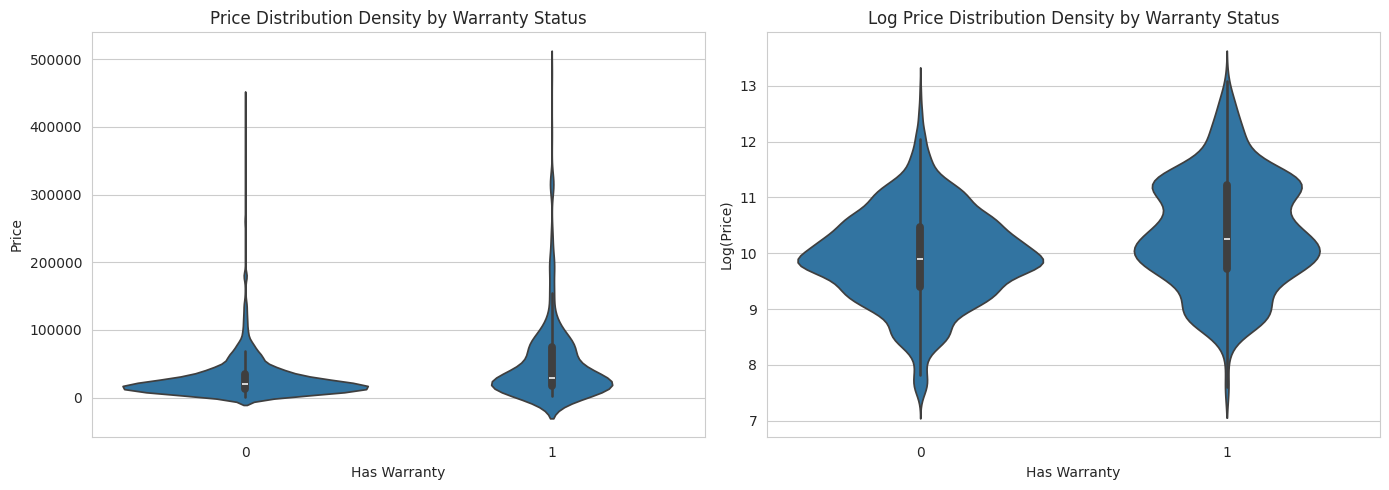

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Price Distribution Density by Warranty Status
sns.violinplot(
    data=data,
    x='Has_Warranty',
    y='Price',
    ax=axes[0]
)

axes[0].set_title('Price Distribution Density by Warranty Status')
axes[0].set_xlabel('Has Warranty')
axes[0].set_ylabel('Price')

# 2. Log Price Distribution Density by Warranty Status
sns.violinplot(
    data=data,
    x='Has_Warranty',
    y=np.log(data['Price']),
    ax=axes[1]
)

axes[1].set_title('Log Price Distribution Density by Warranty Status')
axes[1].set_xlabel('Has Warranty')
axes[1].set_ylabel('Log(Price)')

# Adjust layout
plt.tight_layout()
plt.show()

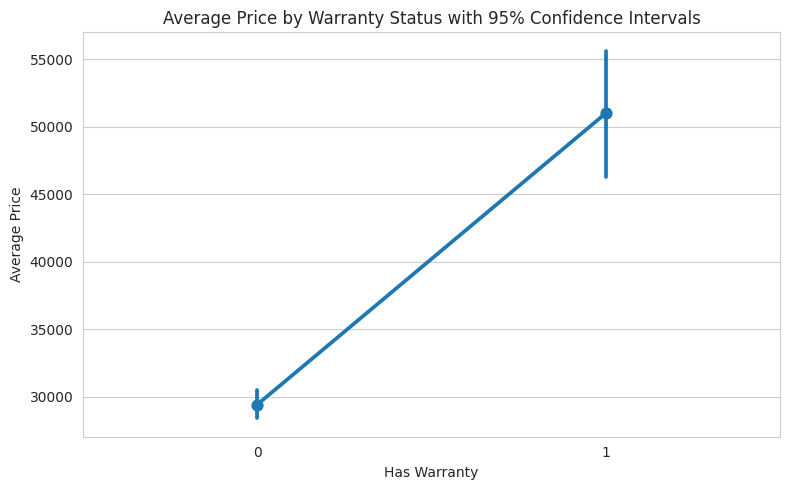

In [53]:
plt.figure(figsize=(8, 5))

sns.pointplot(
    data=data,
    x='Has_Warranty',
    y='Price',
    errorbar=('ci', 95)
)

plt.title('Average Price by Warranty Status with 95% Confidence Intervals')
plt.xlabel('Has Warranty')
plt.ylabel('Average Price')

plt.tight_layout()
plt.show()

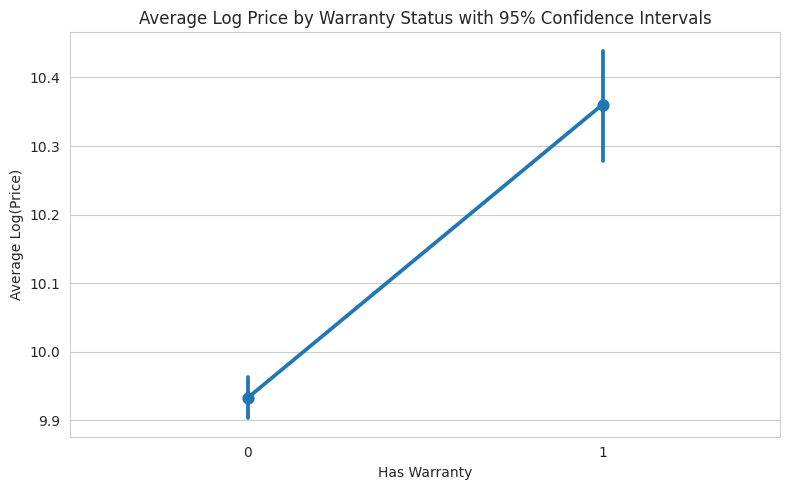

In [54]:
plt.figure(figsize=(8, 5))

sns.pointplot(
    data=data,
    x='Has_Warranty',
    y=np.log(data['Price']),
    errorbar=('ci', 95)
)

plt.title('Average Log Price by Warranty Status with 95% Confidence Intervals')
plt.xlabel('Has Warranty')
plt.ylabel('Average Log(Price)')

plt.tight_layout()
plt.show()

In [55]:
# Remove missing values
df = data[['Has_Warranty', 'Price']].dropna().copy()

# Overall mean price
overall_mean = df['Price'].mean()

# Total sum of squares
total_ss = ((df['Price'] - overall_mean) ** 2).sum()

# Mean price and count for each warranty category
group_means = df.groupby('Has_Warranty')['Price'].mean()
group_counts = df.groupby('Has_Warranty')['Price'].count()

# Between-group sum of squares
between_ss = (
    group_counts * (group_means - overall_mean) ** 2
).sum()

# Calculate Eta
if total_ss > 0:
    eta = np.sqrt(between_ss / total_ss)
else:
    eta = np.nan

print("Eta:", eta)

# Calculate Eta squared
if pd.notna(eta):
    print("Eta Squared:", eta ** 2)

Eta: 0.20740323724649012
Eta Squared: 0.043016102820323865


In [56]:
interpret_eta(eta, "Has_Warranty")

Weak association between Has_Warranty and Price.


In [57]:
data.sample(2)

,Price,Brand,Type,Has_Warranty,RAM_GB,RAM_missing,ROM_GB,ROM_Missing,Screen_Size,Screen_Size_missing,Processor_Tier,Processor_Tier_missing,Storage_Type,processor,Warranty_Days_filled,Warranty_Days_was_missing
3662,4000.0,others,Laptop,0,4.0,0,500.0,0,14.0,1,3.0,1,Unspecified,Intel Core i5,0.0,0
3261,15000.0,lenovo,Laptop,0,8.0,0,365.0,1,10.1,0,1.0,0,Unspecified,Intel Celeron,0.0,0


# Bivariate Exploratory Data Analysis (EDA) — `RAM_GB` vs. `Price`

## 1. Summary Statistics and Data Integrity

- **Purpose:** This analysis examines how RAM capacity is associated with product price using group-level statistics and visualizations.
- **Data Overview:** The code compares `RAM_GB` values with `Price`, checks the available values, and calculates the count, mean, median, minimum, maximum, and standard deviation of price for each RAM configuration.
- **Distribution:** The dataset contains many 8 GB listings, followed by 16 GB and 4 GB configurations. Several higher-capacity RAM categories have much smaller sample sizes, so their summary statistics are less stable.

## 2. Visualization Analysis

- **Boxplots:** Compare price distributions across RAM capacities on the original and log-transformed scales. The original scale emphasizes large price differences and outliers; the log scale compresses extreme prices and makes central distributions easier to compare.
- **Bar Charts:** Compare average price and average log price across RAM capacities. The mean log price is a different quantity from the log of the mean price.
- **Combined Plots:** Place the distributions or averages side by side to make differences between the original and transformed scales easier to assess.

## 3. Statistical Analysis — Correlation Ratio (Eta)

- **Eta:** Approximately `0.6909`.
- **Eta Squared:** Approximately `0.4774` (47.74%).

The result indicates a strong association between RAM capacity groups and price in this dataset. Around 47.74% of the observed price variation is associated with differences between RAM groups. This is descriptive association, not evidence that RAM alone causes the price differences.

## 4. Key Takeaways and Data Modeling Guidance

- RAM capacity appears to be a useful predictor of price, and average prices generally rise across common higher-RAM configurations.
- Treat RAM as a numerical feature where appropriate, while checking whether the relationship is nonlinear.
- Interpret rare RAM configurations cautiously and verify unusual values before modeling.
- Compare models using cross-validation rather than relying on Eta alone.

## 5. Conclusion

The analysis suggests that `RAM_GB` has a strong association with `Price`. RAM is likely to be an informative feature for price prediction, but its contribution should be evaluated together with brand, processor, storage, screen size, and product type.

In [58]:
data['RAM_GB'] = data['RAM_GB'].astype('int')

In [59]:
print(data[['RAM_GB', 'Price']].head())

   RAM_GB    Price
0      16  65000.0
1       8  24999.0
2       4   5500.0
3       8  18000.0
4       8  10000.0


In [60]:
print(data['RAM_GB'].value_counts())

RAM_GB
8      2323
16      812
4       510
32      103
64       21
24       14
36       12
2        11
23        7
128       7
18        6
48        2
96        1
Name: count, dtype: int64


In [61]:
print("\nRAM_GB data type:", data['RAM_GB'].dtype)
print("Price data type:", data['Price'].dtype)


RAM_GB data type: int64
Price data type: float64


In [251]:
df = data[['RAM_GB', 'Price']].dropna().copy()

stats = df.groupby('RAM_GB', observed=True)['Price'].agg(
    ['count', 'mean', 'median', 'min', 'max', 'std']
)

print(stats)

        count           mean    median       min       max            std
RAM_GB                                                                   
2          11    3354.272727    2500.0    1599.0    5500.0    1465.319152
4         510   13111.905882    9984.5    2000.0   70000.0   11882.568500
8        2323   24413.039604   19999.0    1800.0  250000.0   20419.546475
16        812   50922.135468   42000.0    3000.0  439999.0   35782.548679
18          6  155000.000000  155000.0  155000.0  155000.0       0.000000
23          7   38999.000000   38999.0   38999.0   38999.0       0.000000
24         14  108528.500000   82500.0   25500.0  480000.0  114530.477512
32        103   91602.601942   75999.0    6000.0  290000.0   65178.987971
36         12  297450.000000  315500.0  170000.0  389900.0   63221.278064
48          2  244950.000000  244950.0  230000.0  259900.0   21142.492757
64         21  158380.809524  180000.0    4000.0  350000.0   88313.499158
96          1  399999.000000  399999.0

In [252]:
df2 = data[['RAM_GB', 'Price']].dropna().copy()
df2['Price'] = np.log(df2['Price'])

stats = df2.groupby('RAM_GB', observed=True)['Price'].agg(
    ['count', 'mean', 'median', 'min', 'max', 'std']
)

print(stats)

        count       mean     median        min        max       std
RAM_GB                                                             
2          11   8.036456   7.824046   7.377134   8.612503  0.417556
4         510   9.230884   9.208788   7.600902  11.156251  0.661414
8        2323   9.853093   9.903438   7.495542  12.429216  0.715475
16        812  10.635153  10.645425   8.006368  12.994528  0.656021
18          6  11.951180  11.951180  11.951180  11.951180  0.000000
23          7  10.571291  10.571291  10.571291  10.571291  0.000000
24         14  11.282461  11.320554  10.146434  13.081541  0.764631
32        103  11.159476  11.238475   8.699515  12.577636  0.777770
36         12  12.576498  12.661914  12.043554  12.873646  0.256199
48          2  12.406943  12.406943  12.345835  12.468052  0.086421
64         21  11.726793  12.100712   8.294050  12.765688  0.935646
96          1  12.899217  12.899217  12.899217  12.899217       NaN
128         7  11.813030  11.813030  11.813030  

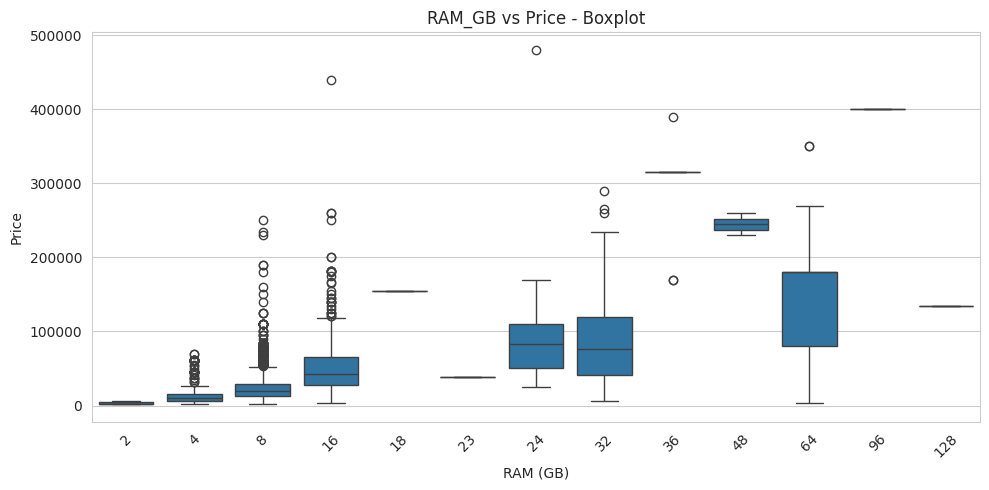

In [64]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x='RAM_GB', y='Price')

plt.title('RAM_GB vs Price - Boxplot')
plt.xlabel('RAM (GB)')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

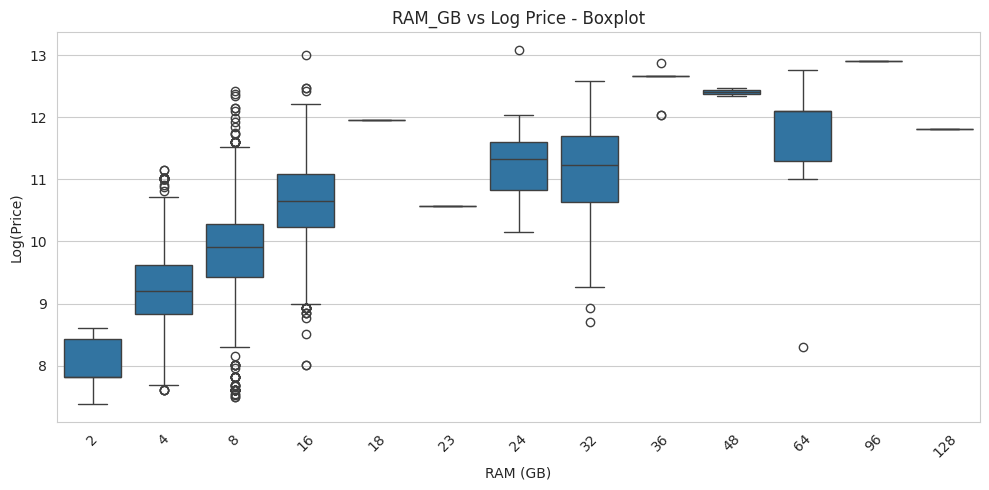

In [65]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df2, x='RAM_GB', y='Price')

plt.title('RAM_GB vs Log Price - Boxplot')
plt.xlabel('RAM (GB)')
plt.ylabel('Log(Price)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

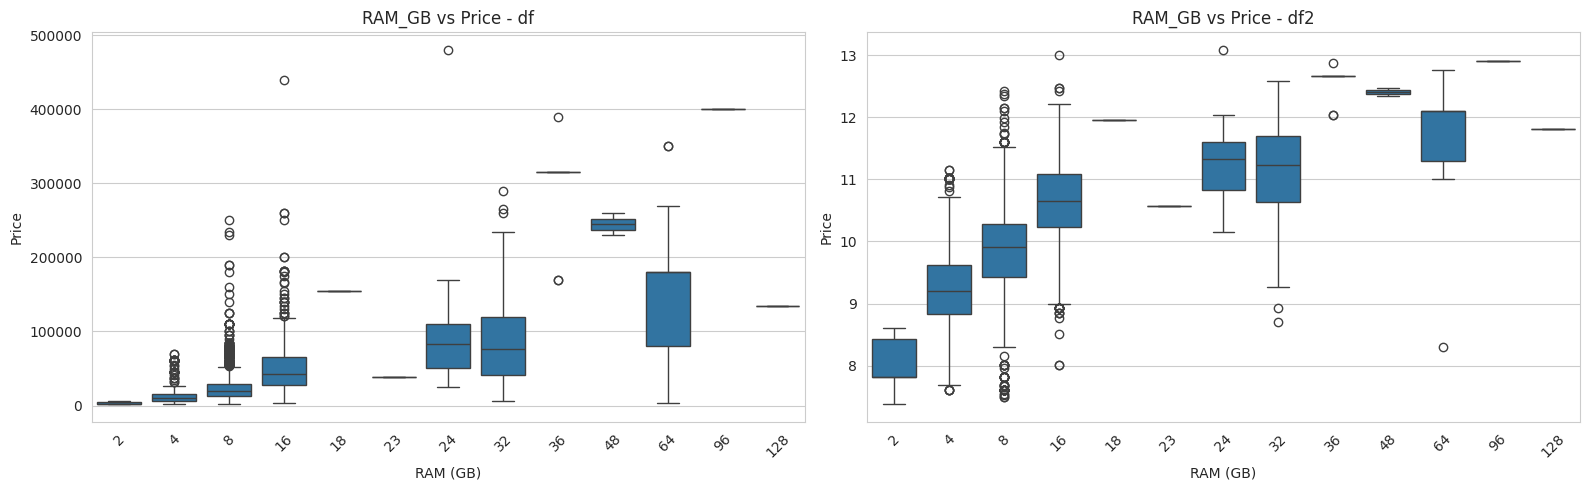

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. RAM_GB vs Price - df
sns.boxplot(data=df, x='RAM_GB', y='Price', ax=axes[0])

axes[0].set_title('RAM_GB vs Price - df')
axes[0].set_xlabel('RAM (GB)')
axes[0].set_ylabel('Price')
axes[0].tick_params(axis='x', rotation=45)

# 2. RAM_GB vs Price - df2
sns.boxplot(data=df2, x='RAM_GB', y='Price', ax=axes[1])

axes[1].set_title('RAM_GB vs Price - df2')
axes[1].set_xlabel('RAM (GB)')
axes[1].set_ylabel('Price')
axes[1].tick_params(axis='x', rotation=45)

# Adjust layout
plt.tight_layout()
plt.show()

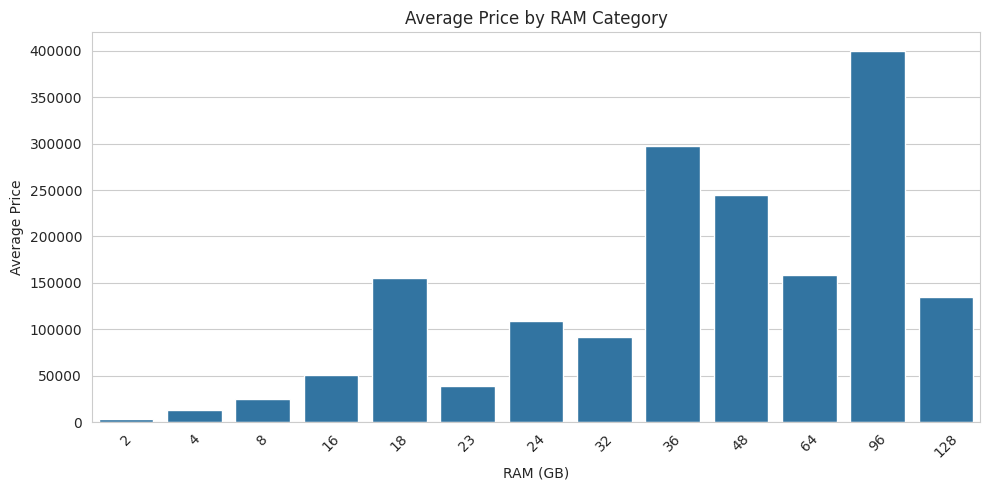

In [68]:
plt.figure(figsize=(10, 5))

sns.barplot(data=df, x='RAM_GB', y='Price', errorbar=None)

plt.title('Average Price by RAM Category')
plt.xlabel('RAM (GB)')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

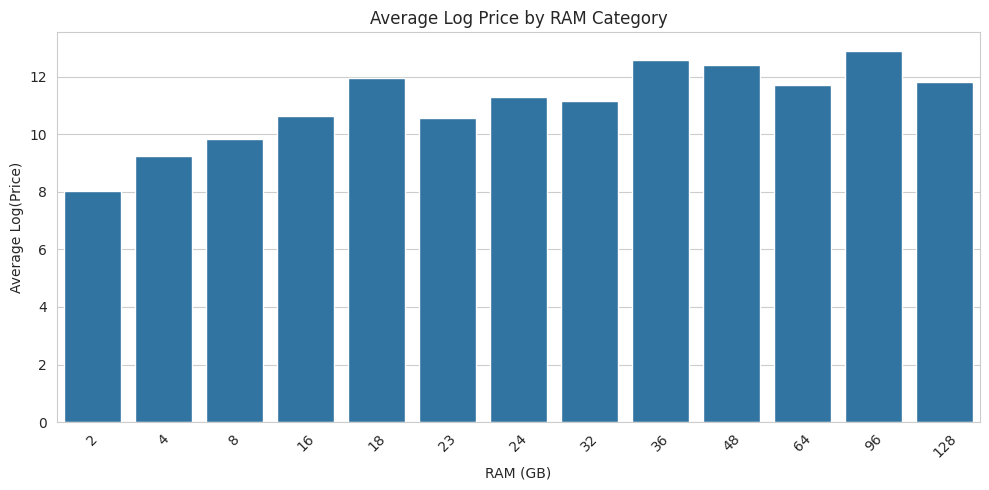

In [69]:
plt.figure(figsize=(10, 5))

sns.barplot(data=df2, x='RAM_GB', y='Price', errorbar=None)

plt.title('Average Log Price by RAM Category')
plt.xlabel('RAM (GB)')
plt.ylabel('Average Log(Price)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

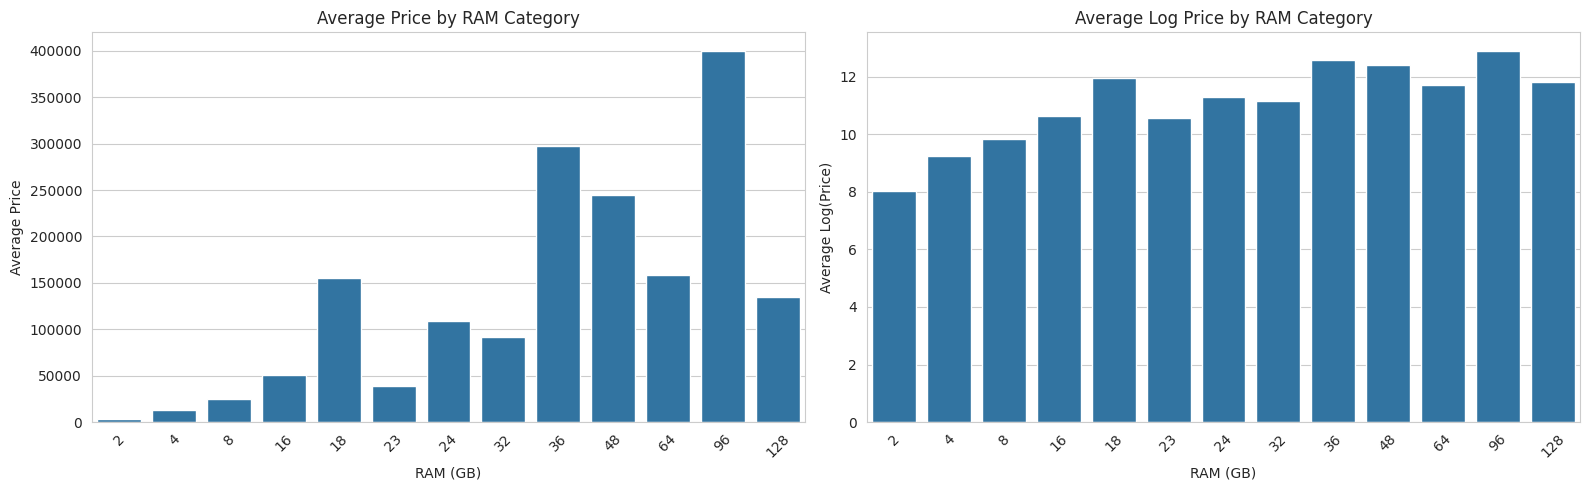

In [253]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Average Price by RAM Category - df
sns.barplot(
    data=df,
    x='RAM_GB',
    y='Price',
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title('Average Price by RAM Category')
axes[0].set_xlabel('RAM (GB)')
axes[0].set_ylabel('Average Price')
axes[0].tick_params(axis='x', rotation=45)

# 2. Average Log Price by RAM Category - df2
sns.barplot(
    data=df2,
    x='RAM_GB',
    y='Price',
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title('Average Log Price by RAM Category')
axes[1].set_xlabel('RAM (GB)')
axes[1].set_ylabel('Average Log(Price)')
axes[1].tick_params(axis='x', rotation=45)

# Adjust layout
plt.tight_layout()
plt.show()

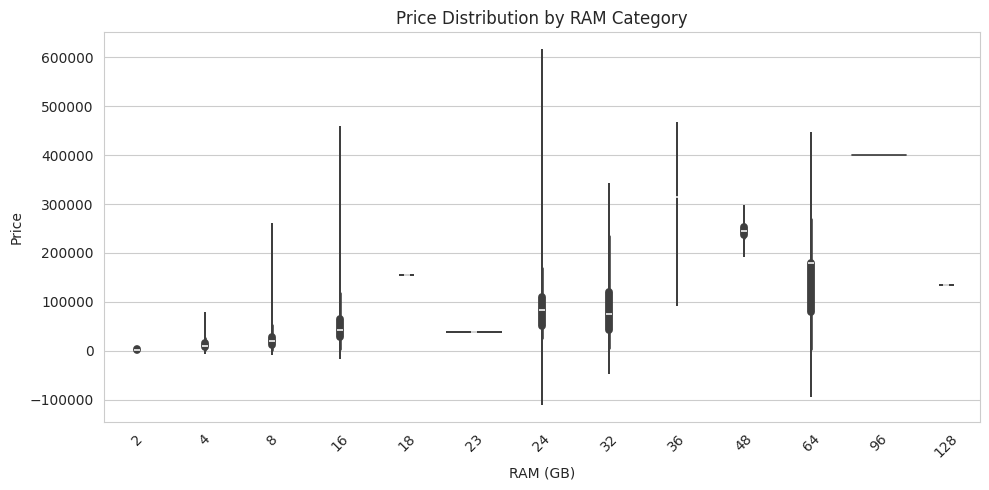

In [70]:
plt.figure(figsize=(10, 5))

sns.violinplot(data=df, x='RAM_GB', y='Price')

plt.title('Price Distribution by RAM Category')
plt.xlabel('RAM (GB)')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

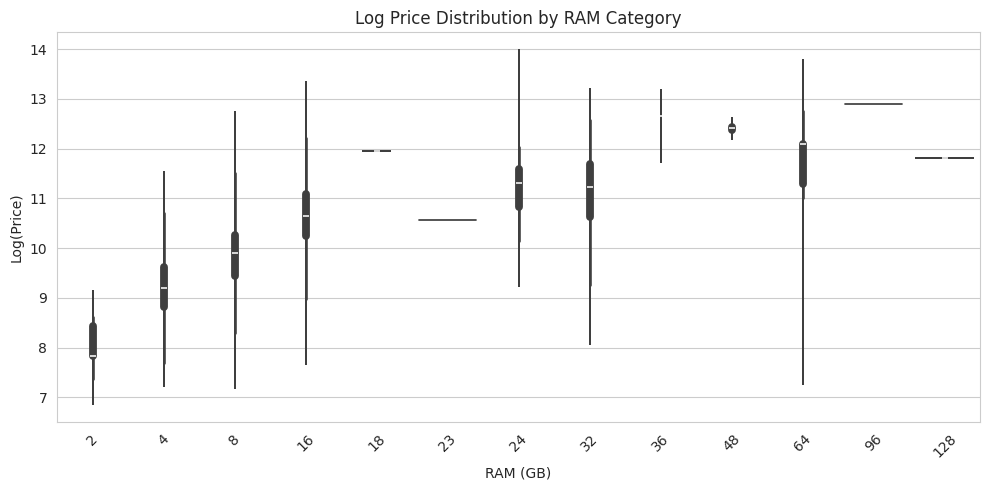

In [71]:
plt.figure(figsize=(10, 5))

sns.violinplot(data=df2, x='RAM_GB', y='Price')

plt.title('Log Price Distribution by RAM Category')
plt.xlabel('RAM (GB)')
plt.ylabel('Log(Price)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [72]:
overall_mean = df['Price'].mean()

total_ss = ((df['Price'] - overall_mean) ** 2).sum()

group_means = df.groupby('RAM_GB', observed=True)['Price'].mean()
group_counts = df.groupby('RAM_GB', observed=True)['Price'].count()

between_ss = (
    group_counts * (group_means - overall_mean) ** 2
).sum()

eta = np.sqrt(between_ss / total_ss) if total_ss > 0 else np.nan

print("Eta:", eta)
print("Eta Squared:", eta ** 2 if pd.notna(eta) else np.nan)

Eta: 0.6909299166582987
Eta Squared: 0.4773841497334436


In [73]:
interpret_eta(eta, "RAM_GB")

Strong association between RAM_GB and Price.


# Bivariate Exploratory Data Analysis (EDA) — `RAM_missing` vs. `Price`

## 1. Summary Statistics and Data Integrity

- **Purpose:** This analysis checks whether product prices differ depending on whether the original RAM specification was missing.
- **Data Overview:** `RAM_missing = 0` indicates RAM information is present (2,622 listings), while `RAM_missing = 1` indicates it was missing (1,207 listings). The code checks counts and nulls, then calculates price summaries for each group.
- **Price Comparison:** Listings with RAM information have a mean price of approximately 34,836 and a median of 23,650. Listings with missing RAM information have a mean of approximately 28,444 and a median of 18,000.
- **Data Quality Note:** Both groups contain high-price outliers and substantial price variability.

## 2. Visualization Analysis

- **Boxplots:** Compare price and log-price distributions for the two missingness groups. The raw-price plots show right-skew and extreme outliers; the log transformation compresses the high values and helps compare the central distributions.
- **Bar Charts:** Compare mean price and mean log price between listings with known and missing RAM values. Mean log price is not the same as the logarithm of mean price.

## 3. Statistical Analysis — Correlation Ratio (Eta)

- **Eta for raw price:** Approximately `0.0782`.
- **Eta Squared:** Approximately `0.0061` (0.61%).

This indicates a very weak association between the RAM missingness flag and price. Only about 0.61% of observed price variation is associated with differences between these two groups.

**Code check:** The later Eta calculation for the transformed dataset reuses group means and counts from `df` instead of calculating them from `df2`. Its printed result is therefore not a valid Eta estimate for the transformed outcome; correct those references before interpreting that second result. The helper interpretation printed for the raw Eta also conflicts with the numeric value, so use the numeric Eta result here.

## 4. Key Takeaways and Data Modeling Guidance

- `RAM_missing` has limited standalone association with price, but may still provide useful information about incomplete listings.
- Retain the flag alongside an appropriately imputed RAM feature if validation shows that it helps.
- Do not remove listings solely because RAM was missing; doing so may reduce training data or introduce selection bias.
- Evaluate the feature using the same cross-validation splits in models with and without the flag.

## 5. Conclusion

Listings with known RAM specifications are more expensive on average in this sample, but the Eta value of approximately 0.0782 indicates a very weak association. Treat `RAM_missing` as a possible auxiliary feature, and validate its contribution in the complete prediction model.

In [75]:
print(data[['RAM_missing', 'Price']].head())

   RAM_missing    Price
0            1  65000.0
1            0  24999.0
2            0   5500.0
3            0  18000.0
4            1  10000.0


In [76]:
print(data['RAM_missing'].value_counts(dropna=False))

RAM_missing
0    2622
1    1207
Name: count, dtype: int64


In [77]:
print(data[['RAM_missing', 'Price']].isnull().sum())

RAM_missing    0
Price          0
dtype: int64


In [254]:
df = data[['RAM_missing', 'Price']].dropna().copy()

In [255]:
stats = df.groupby('RAM_missing', observed=True)['Price'].agg(
    ['count', 'mean', 'median', 'min', 'max', 'std']
)

print(stats)

             count          mean   median     min       max           std
RAM_missing                                                              
0             2622  34836.080092  23650.0  1800.0  480000.0  39362.564805
1             1207  28443.900580  18000.0  1599.0  439999.0  34327.835364


In [256]:
df2 = data[['RAM_missing', 'Price']].copy()

df2['Price'] = pd.to_numeric(df2['Price'], errors='coerce')

df2 = df2.replace([np.inf, -np.inf], np.nan).dropna(
    subset=['RAM_missing', 'Price']
)
df2['Price'] = np.log(df2['Price'])

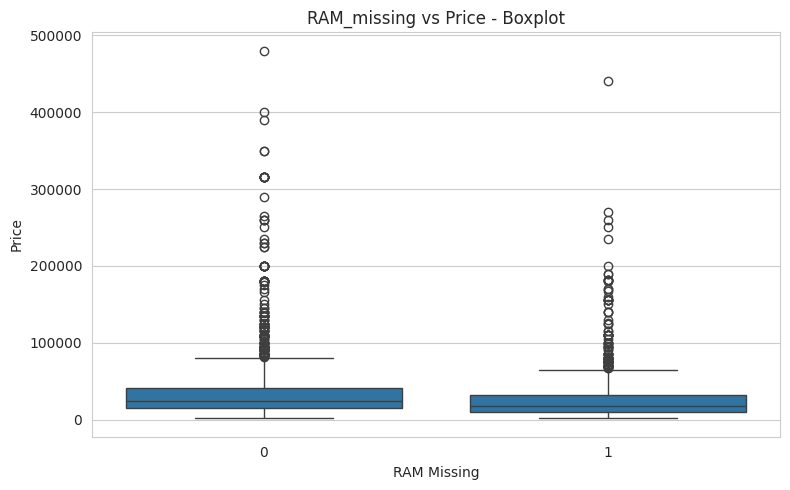

In [80]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='RAM_missing', y='Price')

plt.title('RAM_missing vs Price - Boxplot')
plt.xlabel('RAM Missing')
plt.ylabel('Price')

plt.tight_layout()
plt.show()

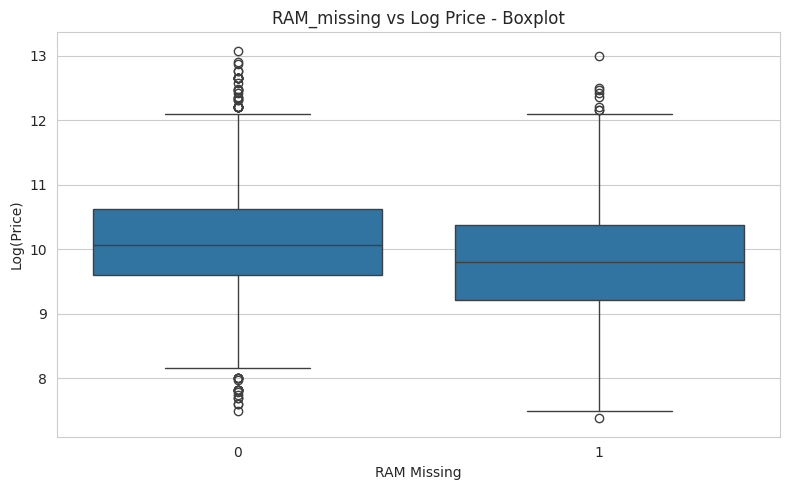

In [257]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df2, x='RAM_missing', y='Price')

plt.title('RAM_missing vs Log Price - Boxplot')
plt.xlabel('RAM Missing')
plt.ylabel('Log(Price)')

plt.tight_layout()
plt.show()

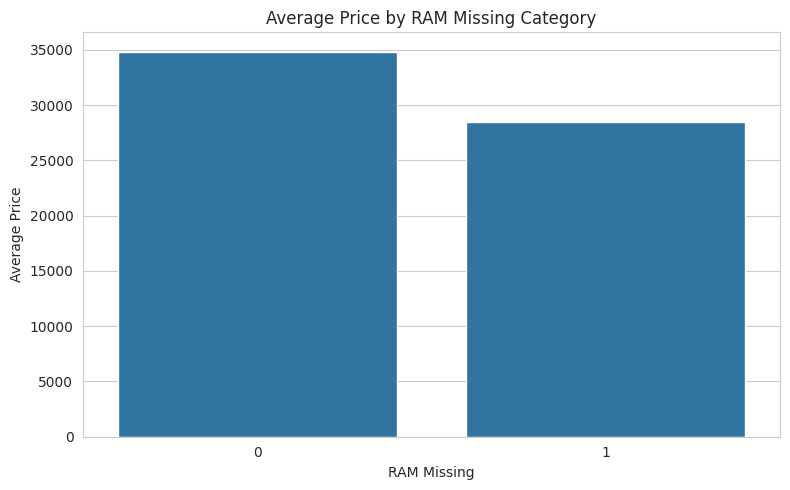

In [81]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df, x='RAM_missing', y='Price', errorbar=None)

plt.title('Average Price by RAM Missing Category')
plt.xlabel('RAM Missing')
plt.ylabel('Average Price')

plt.tight_layout()
plt.show()

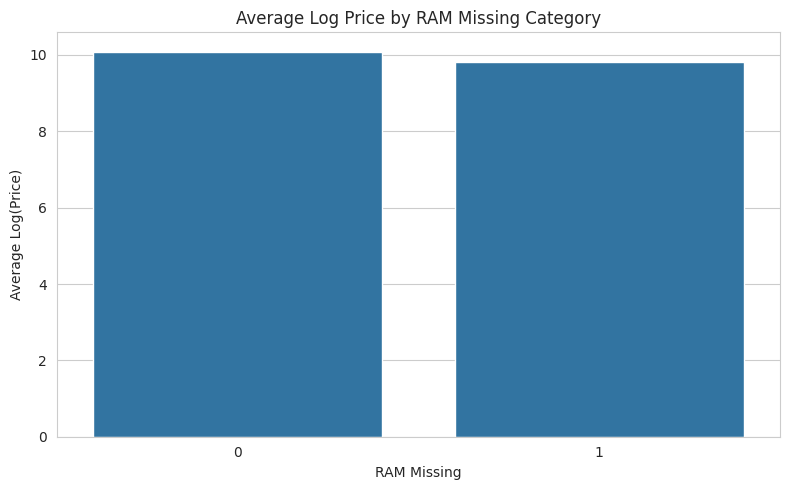

In [258]:
plt.figure(figsize=(8, 5))

sns.barplot(data=df2, x='RAM_missing', y='Price', errorbar=None)

plt.title('Average Log Price by RAM Missing Category')
plt.xlabel('RAM Missing')
plt.ylabel('Average Log(Price)')

plt.tight_layout()
plt.show()

In [82]:
overall_mean = df['Price'].mean()

total_ss = ((df['Price'] - overall_mean) ** 2).sum()

group_means = df.groupby('RAM_missing', observed=True)['Price'].mean()
group_counts = df.groupby('RAM_missing', observed=True)['Price'].count()

between_ss = (
    group_counts * (group_means - overall_mean) ** 2
).sum()

eta = np.sqrt(between_ss / total_ss) if total_ss > 0 else np.nan

print("Eta:", eta)
print("Eta Squared:", eta ** 2 if pd.notna(eta) else np.nan)

Eta: 0.07824685421135746
Eta Squared: 0.006122570193973429


In [260]:
interpret_eta(eta, "RAM_missing")

Very strong association between RAM_missing and Price.


In [259]:
overall_mean = df2['Price'].mean()

total_ss = ((df2['Price'] - overall_mean) ** 2).sum()

group_means = df.groupby('RAM_missing', observed=True)['Price'].mean()
group_counts = df.groupby('RAM_missing', observed=True)['Price'].count()

between_ss = (
    group_counts * (group_means - overall_mean) ** 2
).sum()

eta = np.sqrt(between_ss / total_ss) if total_ss > 0 else np.nan

print("Eta:", eta)
print("Eta Squared:", eta ** 2 if pd.notna(eta) else np.nan)

Eta: 37576.44074897958
Eta Squared: 1411988899.361573


In [83]:
interpret_eta(eta, "RAM_missing")

Very weak association between RAM_missing and Price.


# Bivariate Exploratory Data Analysis (EDA) — `Screen_Size` vs. `Price`

## 1. Summary Statistics and Data Integrity

- **Purpose:** This section examines the relationship between screen size and product price through summary statistics, visualizations, correlations, and Eta.
- **Data Overview:** The analysis includes 3,829 observations. Screen size averages approximately 16.24 inches (median 15.6), while price averages approximately 32,821 (median 21,000).
- **Screen Size Frequencies:** Common sizes include 14 inches (1,275 listings), 15.6 inches (981), and 19 inches (531). Several screen sizes have very few observations, making their individual group summaries less reliable.
- **Price Distribution:** The mean is higher than the median and the maximum price is 480,000, indicating a right-skewed distribution with high-price outliers.

## 2. Visualization Analysis

- **Scatterplot:** Shows individual prices across screen sizes. The wide price spread at many screen sizes suggests that screen size alone does not determine price.
- **Boxplots and Bar Charts:** Compare price distributions and average prices across screen sizes, both on the original scale and after log transformation.
- **Grouped Screen-Size Plots:** The code groups screen sizes into intervals to make broader patterns easier to inspect. Group boundaries affect the visual comparison, so the groups should be interpreted as descriptive bins rather than natural product categories.

## 3. Statistical Analysis — Pearson, Spearman, and Eta

- **Pearson correlation:** Approximately `0.0231` with p-value `0.1531`, indicating negligible linear association and no statistically significant linear correlation at the 5% level.
- **Spearman correlation:** Approximately `-0.1557` with a very small p-value, indicating a weak negative monotonic association.
- **Eta:** Approximately `0.4452`; Eta squared is approximately `0.1982` (19.82%) when each distinct screen size is treated as a group.

Eta can capture differences between group means even when linear correlation is near zero. However, rare screen sizes can make group-based estimates unstable. The correlation and Eta results describe different aspects of the relationship and are not interchangeable.

## 4. Key Takeaways and Data Modeling Guidance

- Screen size alone has almost no linear association with price, but price distributions vary across screen-size groups.
- Keep `Screen_Size` as a potential feature and evaluate nonlinear relationships with suitable models.
- Investigate unusual screen-size values and use caution with categories represented by only a few listings.
- Compare model performance with cross-validation; do not select features based only on a single bivariate statistic.

## 5. Conclusion

The analysis finds negligible Pearson correlation, weak negative Spearman correlation, and moderate Eta association across distinct screen-size groups. These results suggest a non-simple relationship, so screen size should be evaluated alongside brand, RAM, processor, storage, and product type.

In [85]:
data['Screen_Size'].value_counts()

,count
Screen_Size,
14.0,1275
15.6,981
19.0,531
13.3,212
22.0,150
16.0,132
13.0,115
21.5,104
24.0,79


In [86]:
from scipy.stats import pearsonr, spearmanr

sns.set_style('whitegrid')

In [87]:
print(data[['Screen_Size', 'Price']].head())

   Screen_Size    Price
0         24.0  65000.0
1         14.0  24999.0
2         19.0   5500.0
3         14.0  18000.0
4         14.0  10000.0


In [88]:
print(data[['Screen_Size', 'Price']].dtypes)

Screen_Size    float64
Price          float64
dtype: object


In [89]:
print(data['Screen_Size'].value_counts(dropna=False))

Screen_Size
14.0    1275
15.6     981
19.0     531
13.3     212
22.0     150
16.0     132
13.0     115
21.5     104
24.0      79
27.0      60
15.0      60
23.8      32
18.5      11
17.3      11
17.0       9
32.0       9
10.1       8
20.0       7
10.0       7
13.5       5
31.5       4
15.4       4
13.6       4
21.0       3
18.0       3
12.0       3
11.0       3
12.5       2
29.5       1
29.0       1
28.0       1
40.0       1
19.5       1
Name: count, dtype: int64


In [90]:
df = data[['Screen_Size', 'Price']].copy()

# Convert both columns to numeric if necessary
df['Screen_Size'] = pd.to_numeric(df['Screen_Size'], errors='coerce')
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

# Remove missing and infinite values
df = df.replace([np.inf, -np.inf], np.nan).dropna()

In [91]:
print(df[['Screen_Size', 'Price']].describe())

       Screen_Size          Price
count  3829.000000    3829.000000
mean     16.237895   32821.099504
std       3.258546   37959.755574
min      10.000000    1599.000000
25%      14.000000   12500.000000
50%      15.600000   21000.000000
75%      19.000000   39500.000000
max      40.000000  480000.000000


In [92]:
screen_stats = df.groupby('Screen_Size')['Price'].agg(
    ['count', 'mean', 'median', 'min', 'max', 'std']
).sort_index()

print(screen_stats)

             count          mean   median      min       max           std
Screen_Size                                                               
10.0             7  10928.285714  11000.0   8000.0   13000.0   1643.978985
10.1             8   7725.000000   6800.0   6000.0   15000.0   2952.843666
11.0             3  28666.666667  20000.0  20000.0   46000.0  15011.106999
12.0             3  15833.000000  14000.0  13500.0   19999.0   3616.513100
12.5             2  22750.000000  22750.0  19000.0   26500.0   5303.300859
13.0           115  57440.278261  54599.0   7800.0  167000.0  29709.249322
13.3           212  52358.028302  43500.0   3000.0  181000.0  30242.697096
13.5             5  45999.000000  51999.0  36999.0   51999.0   8215.838363
13.6             4  53575.000000  37400.0  29500.0  110000.0  38306.515982
14.0          1275  26801.224314  20000.0   2000.0  389900.0  26750.614222
15.0            60  38890.566667  27500.0   4444.0  200000.0  41828.467236
15.4             4  10875

In [261]:
df2 = data[['Screen_Size', 'Price']].copy()

df2['Price'] = pd.to_numeric(df2['Price'], errors='coerce')
df2['Screen_Size'] = pd.to_numeric(df2['Screen_Size'], errors='coerce')

df2 = df2.replace([np.inf, -np.inf], np.nan).dropna(
    subset=['Screen_Size', 'Price']
)
df2['Price'] = np.log(df2['Price'])

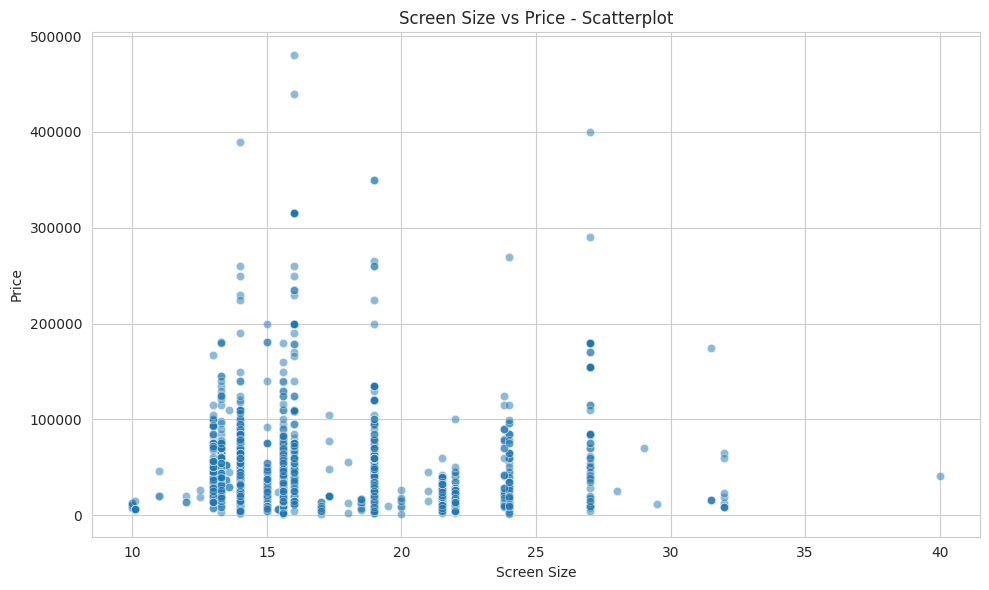

In [93]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Screen_Size',
    y='Price',
    alpha=0.5
)

plt.title('Screen Size vs Price - Scatterplot')
plt.xlabel('Screen Size')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

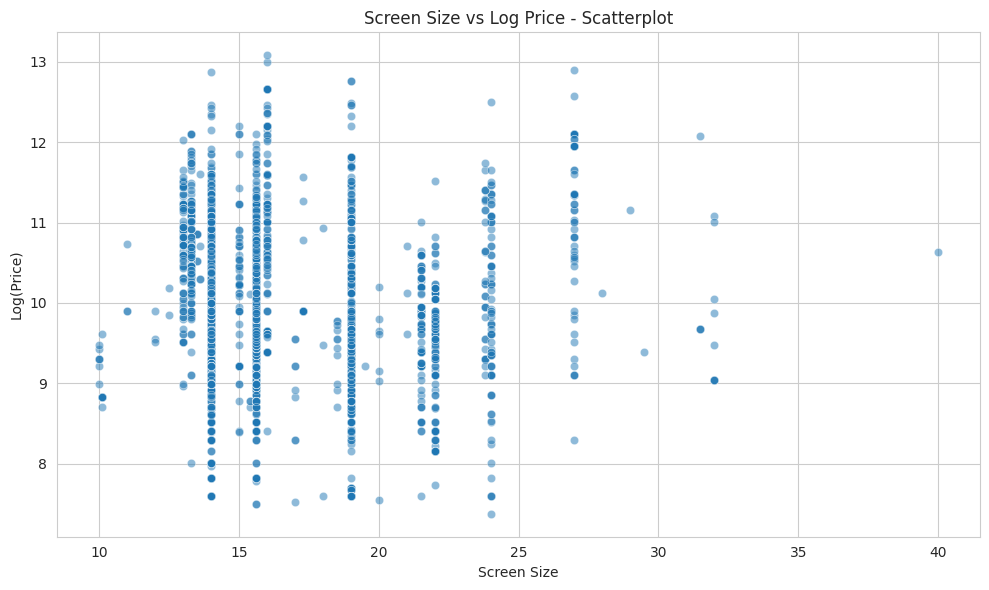

In [262]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df2,
    x='Screen_Size',
    y='Price',
    alpha=0.5
)

plt.title('Screen Size vs Log Price - Scatterplot')
plt.xlabel('Screen Size')
plt.ylabel('Log(Price)')
plt.tight_layout()
plt.show()

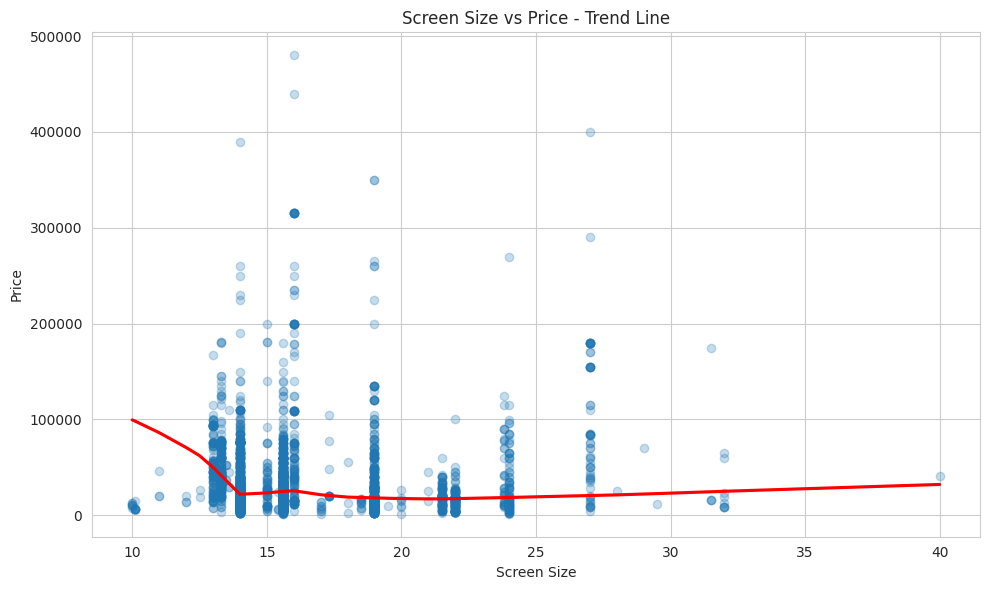

In [94]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='Screen_Size',
    y='Price',
    scatter_kws={'alpha': 0.25},
    line_kws={'color': 'red'},
    lowess=True
)

plt.title('Screen Size vs Price - Trend Line')
plt.xlabel('Screen Size')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

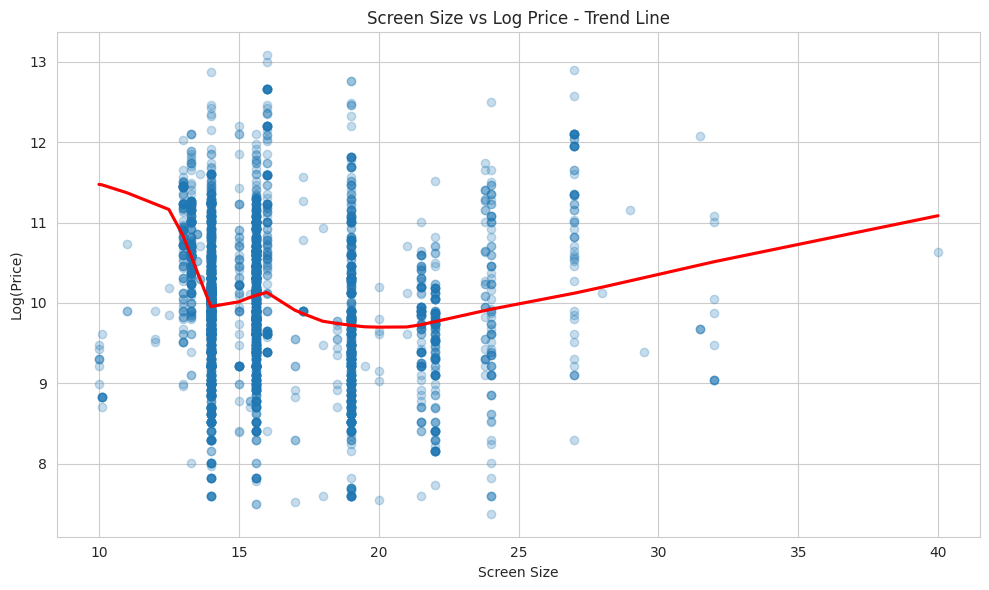

In [263]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df2,
    x='Screen_Size',
    y='Price',
    scatter_kws={'alpha': 0.25},
    line_kws={'color': 'red'},
    lowess=True
)

plt.title('Screen Size vs Log Price - Trend Line')
plt.xlabel('Screen Size')
plt.ylabel('Log(Price)')
plt.tight_layout()
plt.show()

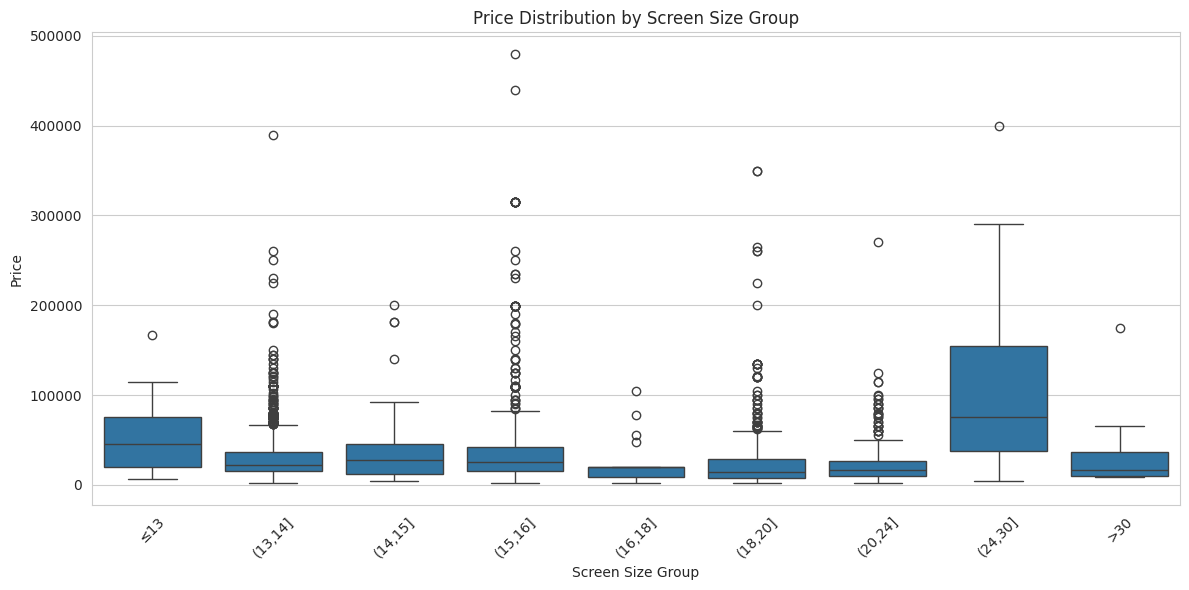

In [95]:
bins = [0, 13, 14, 15, 16, 18, 20, 24, 30, np.inf]

labels = [
    '≤13', '(13,14]', '(14,15]', '(15,16]',
    '(16,18]', '(18,20]', '(20,24]', '(24,30]', '>30'
]

df['Screen_Size_Group'] = pd.cut(
    df['Screen_Size'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='Screen_Size_Group',
    y='Price'
)

plt.title('Price Distribution by Screen Size Group')
plt.xlabel('Screen Size Group')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

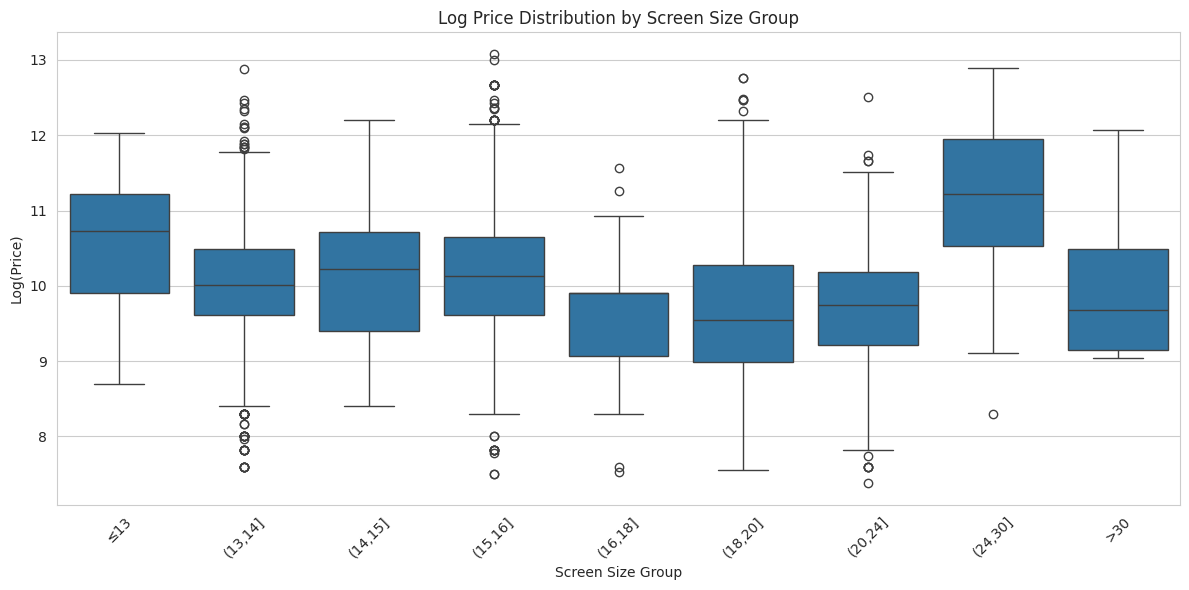

In [264]:
bins = [0, 13, 14, 15, 16, 18, 20, 24, 30, np.inf]

labels = [
    '≤13', '(13,14]', '(14,15]', '(15,16]',
    '(16,18]', '(18,20]', '(20,24]', '(24,30]', '>30'
]

df2['Screen_Size_Group'] = pd.cut(
    df2['Screen_Size'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df2,
    x='Screen_Size_Group',
    y='Price'
)

plt.title('Log Price Distribution by Screen Size Group')
plt.xlabel('Screen Size Group')
plt.ylabel('Log(Price)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [96]:
if len(df) >= 2 and df['Screen_Size'].nunique() > 1 and df['Price'].nunique() > 1:
    pearson_corr, pearson_p = pearsonr(
        df['Screen_Size'], df['Price']
    )

    spearman_corr, spearman_p = spearmanr(
        df['Screen_Size'], df['Price']
    )

    print("Pearson Correlation:", pearson_corr)
    print("Pearson P-value:", pearson_p)

    print("\nSpearman Correlation:", spearman_corr)
    print("Spearman P-value:", spearman_p)
else:
    print("Not enough variation or observations to calculate correlations.")

Pearson Correlation: 0.023090743252973583
Pearson P-value: 0.15313244911941754

Spearman Correlation: -0.15565110541518276
Spearman P-value: 3.408568611704339e-22


In [97]:

def interpret_correlation(corr, column_name):
    if pd.isna(corr):
        print(f"Correlation between {column_name} and Price cannot be calculated.")
        return

    abs_corr = abs(corr)

    if abs_corr < 0.2:
        strength = "Very weak"
    elif abs_corr < 0.4:
        strength = "Weak"
    elif abs_corr < 0.6:
        strength = "Moderate"
    elif abs_corr < 0.8:
        strength = "Strong"
    else:
        strength = "Very strong"

    if corr > 0:
        direction = "positive"
    elif corr < 0:
        direction = "negative"
    else:
        direction = "no"

    if corr == 0:
        print(f"No linear correlation between {column_name} and Price.")
    else:
        print(
            f"{strength} {direction} linear correlation "
            f"between {column_name} and Price."
        )

interpret_correlation(
    df['Screen_Size'].corr(df['Price']),
    'Screen_Size'
)


Very weak positive linear correlation between Screen_Size and Price.


In [265]:
if len(df2) >= 2 and df2['Screen_Size'].nunique() > 1 and df2['Price'].nunique() > 1:
    pearson_corr, pearson_p = pearsonr(
        df2['Screen_Size'], df2['Price']
    )

    spearman_corr, spearman_p = spearmanr(
        df2['Screen_Size'], df2['Price']
    )

    print("Pearson Correlation:", pearson_corr)
    print("Pearson P-value:", pearson_p)

    print("\nSpearman Correlation:", spearman_corr)
    print("Spearman P-value:", spearman_p)
else:
    print("Not enough variation or observations to calculate correlations.")

Pearson Correlation: -0.07935950539697664
Pearson P-value: 8.795572206624084e-07

Spearman Correlation: -0.15565110541518276
Spearman P-value: 3.408568611704339e-22


In [266]:
interpret_correlation(
    df2['Screen_Size'].corr(df2['Price']),
    'Screen_Size'
)

Very weak negative correlation between Screen_Size and Price.


In [98]:
overall_mean = df['Price'].mean()

total_ss = ((df['Price'] - overall_mean) ** 2).sum()

group_means = df.groupby('Screen_Size')['Price'].mean()
group_counts = df.groupby('Screen_Size')['Price'].count()

between_ss = (
    group_counts * (group_means - overall_mean) ** 2
).sum()

eta = np.sqrt(between_ss / total_ss) if total_ss > 0 else np.nan

print("Eta:", eta)
print("Eta Squared:", eta ** 2 if pd.notna(eta) else np.nan)

Eta: 0.4452102472223718
Eta Squared: 0.1982121642318054


In [99]:
interpret_eta(eta, 'Screen_Size')

Moderate association between Screen_Size and Price.


In [269]:
overall_mean = df2['Price'].mean()

total_ss = ((df2['Price'] - overall_mean) ** 2).sum()

group_means = df2.groupby('Screen_Size')['Price'].mean()
group_counts = df2.groupby('Screen_Size')['Price'].count()

between_ss = (
    group_counts * (group_means - overall_mean) ** 2
).sum()

eta = np.sqrt(between_ss / total_ss) if total_ss > 0 else np.nan

print("Eta:", eta)
print("Eta Squared:", eta ** 2 if pd.notna(eta) else np.nan)

Eta: 0.43221795857450207
Eta Squared: 0.18681236371430998


In [270]:
interpret_eta(eta, 'Screen_Size')

Moderate association between Screen_Size and Price.


# Bivariate Exploratory Data Analysis (EDA) — `Screen_Size_missing` vs. `Price`

## 1. Summary Statistics and Data Integrity

- **Purpose:** This section checks whether prices differ between listings with screen-size information and listings where the original screen size was missing.
- **Data Overview:** There are 3,829 listings: 1,396 with screen size present (`Screen_Size_missing = 0`) and 2,433 with screen size missing (`Screen_Size_missing = 1`).
- **Price Comparison:** The present group has a mean price of approximately 40,977.53 and median of 25,500. The missing group has a mean of approximately 28,141.12 and median of 19,500.
- Both groups contain substantial price variability and high-price outliers.

## 2. Visualization Analysis

- **Boxplots:** Compare original and log-transformed prices across the two groups. Raw prices show right-skew and extreme values; log prices compress the upper tail and make central distributions easier to compare.
- **Bar Charts:** Compare mean price and mean log price by missingness status. The transformed averages represent log-price means, not the log of the raw-price means.

## 3. Statistical Analysis — Correlation Ratio (Eta)

- **Eta for raw price:** Approximately `0.1628`.
- **Eta Squared:** Approximately `0.0265` (2.65%).
- The result indicates a weak association between screen-size missingness and price. About 2.65% of observed price variation is associated with differences between the two groups.
- The transformed-price calculation gives Eta of approximately `0.1969` (Eta squared approximately 3.88%), indicating a weak association on that scale as well.

## 4. Key Takeaways and Data Modeling Guidance

- Listings with recorded screen sizes have higher average and median prices in this sample, but this does not mean that recording screen size causes a higher price.
- Retain the missingness flag when it is consistent with the feature-engineering strategy and useful during validation.
- Impute missing screen-size values appropriately and preserve the missingness indicator if it adds information.
- Evaluate whether the flag improves model performance with and without it using the same validation splits.

## 5. Conclusion

`Screen_Size_missing` has a weak association with price, with Eta approximately 0.1628 for raw price. It may still help a model account for differences between complete and incomplete listings, but its predictive value should be confirmed through validation.

In [101]:
data['Screen_Size_missing'].value_counts(dropna=False)

,count
Screen_Size_missing,
1,2433
0,1396


In [102]:
data[['Screen_Size_missing', 'Price']].head()

,Screen_Size_missing,Price
0,0,65000.0
1,1,24999.0
2,1,5500.0
3,0,18000.0
4,1,10000.0


In [103]:
df = data[['Screen_Size_missing', 'Price']].copy()

df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

df = df.replace([np.inf, -np.inf], np.nan).dropna(
    subset=['Screen_Size_missing', 'Price']
)

In [271]:
df2 = data[['Screen_Size_missing', 'Price']].copy()

df2['Price'] = pd.to_numeric(df2['Price'], errors='coerce')

df2 = df2.replace([np.inf, -np.inf], np.nan).dropna(
    subset=['Screen_Size_missing', 'Price']
)
df2['Price'] = np.log(df2['Price'])

In [104]:
stats = df.groupby('Screen_Size_missing', observed=True)['Price'].agg(
    ['count', 'mean', 'median', 'min', 'max', 'std']
)

stats

,count,mean,median,min,max,std
Screen_Size_missing,,,,,,
0,1396,40977.532951,25500.0,1850.0,480000.0,46799.969490
1,2433,28141.123716,19500.0,1599.0,399999.0,30848.665695


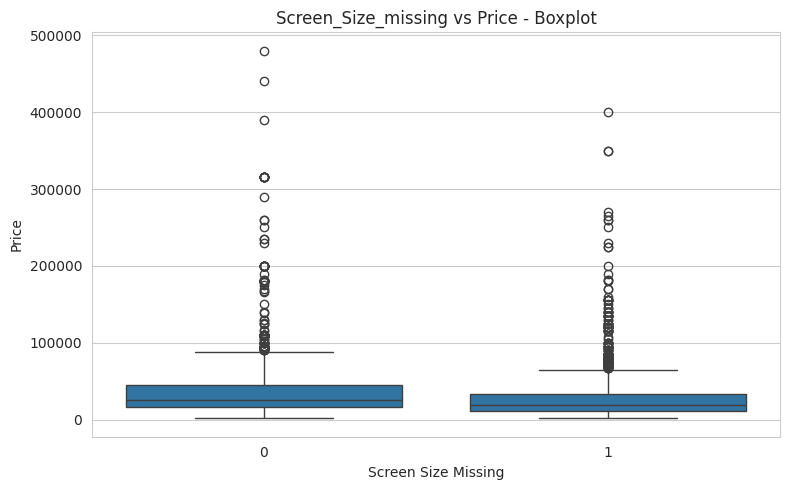

In [105]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Screen_Size_missing',
    y='Price'
)

plt.title('Screen_Size_missing vs Price - Boxplot')
plt.xlabel('Screen Size Missing')
plt.ylabel('Price')

plt.tight_layout()
plt.show()

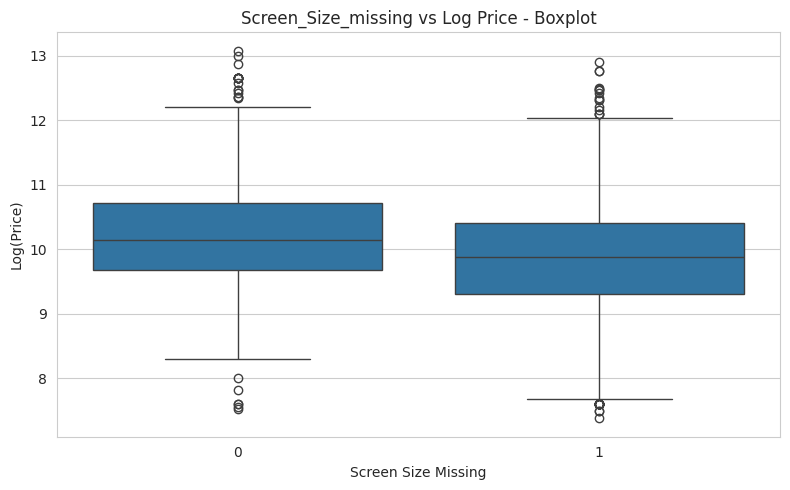

In [272]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df2,
    x='Screen_Size_missing',
    y='Price'
)

plt.title('Screen_Size_missing vs Log Price - Boxplot')
plt.xlabel('Screen Size Missing')
plt.ylabel('Log(Price)')

plt.tight_layout()
plt.show()

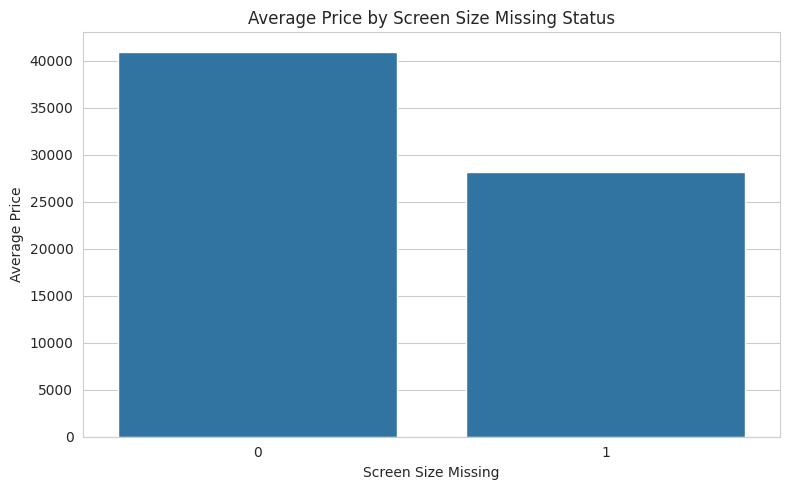

In [106]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='Screen_Size_missing',
    y='Price',
    errorbar=None
)

plt.title('Average Price by Screen Size Missing Status')
plt.xlabel('Screen Size Missing')
plt.ylabel('Average Price')

plt.tight_layout()
plt.show()

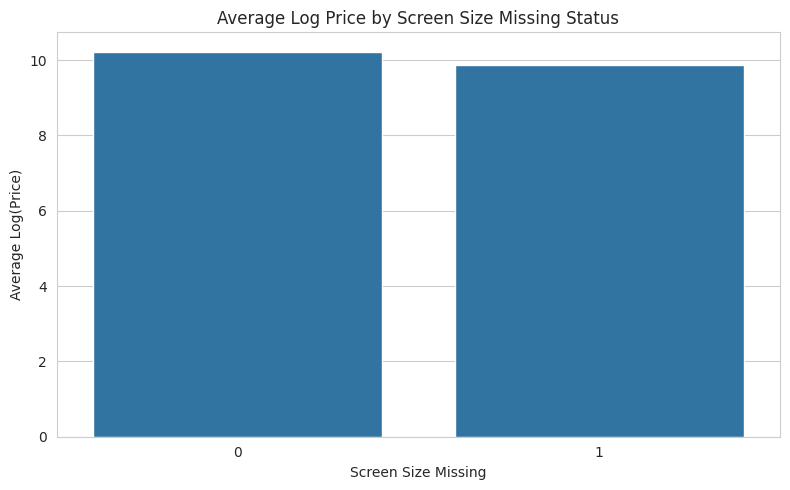

In [273]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df2,
    x='Screen_Size_missing',
    y='Price',
    errorbar=None
)

plt.title('Average Log Price by Screen Size Missing Status')
plt.xlabel('Screen Size Missing')
plt.ylabel('Average Log(Price)')

plt.tight_layout()
plt.show()

In [107]:
overall_mean = df['Price'].mean()

total_ss = ((df['Price'] - overall_mean) ** 2).sum()

group_means = df.groupby(
    'Screen_Size_missing', observed=True
)['Price'].mean()

group_counts = df.groupby(
    'Screen_Size_missing', observed=True
)['Price'].count()

between_ss = (
    group_counts * (group_means - overall_mean) ** 2
).sum()

eta = np.sqrt(between_ss / total_ss) if total_ss > 0 else np.nan

print("Eta:", eta)
print("Eta Squared:", eta ** 2 if pd.notna(eta) else np.nan)

Eta: 0.16278158125849676
Eta Squared: 0.026497843197016584


In [108]:
interpret_eta(eta, 'Screen_Size_missing')

Weak association between Screen_Size_missing and Price.


In [274]:
overall_mean = df2['Price'].mean()

total_ss = ((df2['Price'] - overall_mean) ** 2).sum()

group_means = df2.groupby(
    'Screen_Size_missing', observed=True
)['Price'].mean()

group_counts = df2.groupby(
    'Screen_Size_missing', observed=True
)['Price'].count()

between_ss = (
    group_counts * (group_means - overall_mean) ** 2
).sum()

eta = np.sqrt(between_ss / total_ss) if total_ss > 0 else np.nan

print("Eta:", eta)
print("Eta Squared:", eta ** 2 if pd.notna(eta) else np.nan)

Eta: 0.19690591840141794
Eta Squared: 0.03877194070150586


In [275]:
interpret_eta(eta, 'Screen_Size_missing')

Weak association between Screen_Size_missing and Price.


# Bivariate Exploratory Data Analysis (EDA) — `Processor_Tier` vs. `Price`

## 1. Summary Statistics and Data Integrity

- **Purpose:** This analysis examines how price varies across processor performance tiers.
- **Data Overview:** The code checks the frequency of each tier, computes price summaries by tier, and compares price distributions using raw and log-transformed plots.
- **Tier Frequencies:** Tier 3 is the most common group (2,410 listings), followed by tier 4 (663), tier 2 (510), tier 5 (125), tier 1 (62), and tier 4.5 (59).
- **Price Pattern:** The group summaries show generally higher average prices for higher processor tiers. For example, tier 3 has a mean price of approximately 24,712, tier 4 approximately 60,654, tier 5 approximately 87,497, and tier 4.5 approximately 93,864. The tier 4.5 group is smaller, so its estimate should be interpreted cautiously.

## 2. Visualization Analysis

- **Boxplots:** Compare price spread, medians, and outliers by processor tier on raw and log scales.
- **Bar Charts:** Compare average price and average log price across tiers.
- **Combined Plots:** Place raw-price and transformed-price comparisons side by side to highlight how the log transformation changes the visual influence of expensive products.

## 3. Statistical Analysis — Correlation Ratio (Eta)

- **Eta for raw price:** Approximately `0.5074`.
- **Eta Squared:** Approximately `0.2574` (25.74%).
- For the log-price analysis, Eta is approximately `0.5223` and Eta squared approximately `0.2728` (27.28%).

These results indicate a strong association between processor tier groups and price in this dataset. They do not establish causation, and tier definitions should be interpreted according to how the feature was constructed.

## 4. Key Takeaways and Data Modeling Guidance

- `Processor_Tier` appears potentially informative for price prediction.
- Keep an eye on the meaning and ordering of tiers, especially the fractional tier 4.5.
- Consider whether the relationship is nonlinear and compare suitable regression models.
- Check rare tiers and extreme prices, and evaluate predictive contribution with cross-validation.

## 5. Conclusion

Price generally increases across higher processor tiers, and Eta indicates a strong association. `Processor_Tier` is a promising feature, but its usefulness should be assessed alongside the processor family, brand, RAM, storage, and other specifications.

In [109]:
data['Processor_Tier'].value_counts()

,count
Processor_Tier,
3.0,2410
4.0,663
2.0,510
5.0,125
1.0,62
4.5,59


In [110]:
data[['Processor_Tier', 'Price']].head()

,Processor_Tier,Price
0,4.0,65000.0
1,3.0,24999.0
2,1.0,5500.0
3,3.0,18000.0
4,3.0,10000.0


In [111]:

df = data[['Processor_Tier', 'Price']].copy()

df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

df = df.replace([np.inf, -np.inf], np.nan).dropna(
    subset=['Processor_Tier', 'Price']
)

In [277]:
df2 = data[['Processor_Tier', 'Price']].copy()

df2['Price'] = pd.to_numeric(df2['Price'], errors='coerce')

df2 = df2.replace([np.inf, -np.inf], np.nan).dropna(
    subset=['Processor_Tier', 'Price']
)
df2['Price'] = np.log(df2['Price'])

In [113]:
stats = df.groupby('Processor_Tier', observed=True)['Price'].agg(
    ['count', 'mean', 'median', 'min', 'max', 'std']
)

stats.sort_values('mean', ascending=False)

,count,mean,median,min,max,std
Processor_Tier,,,,,,
4.5,59,93864.254237,76500.0,29000.0,199500.0,50986.284637
5.0,125,87496.680000,70000.0,4500.0,350000.0,67140.449663
4.0,663,60654.233786,45000.0,3000.0,480000.0,57534.231252
3.0,2410,24711.976763,19500.0,1800.0,270000.0,21656.735812
2.0,510,17088.268627,16250.0,1599.0,140000.0,11094.199986
1.0,62,11488.322581,9700.0,2999.0,29000.0,6090.523342


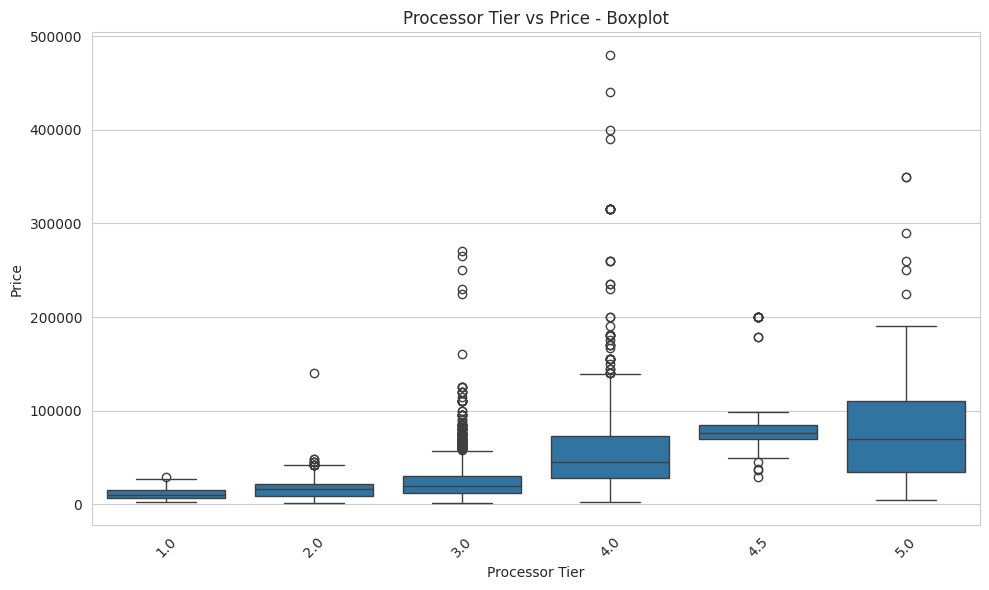

In [114]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Processor_Tier',
    y='Price'
)

plt.title('Processor Tier vs Price - Boxplot')
plt.xlabel('Processor Tier')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

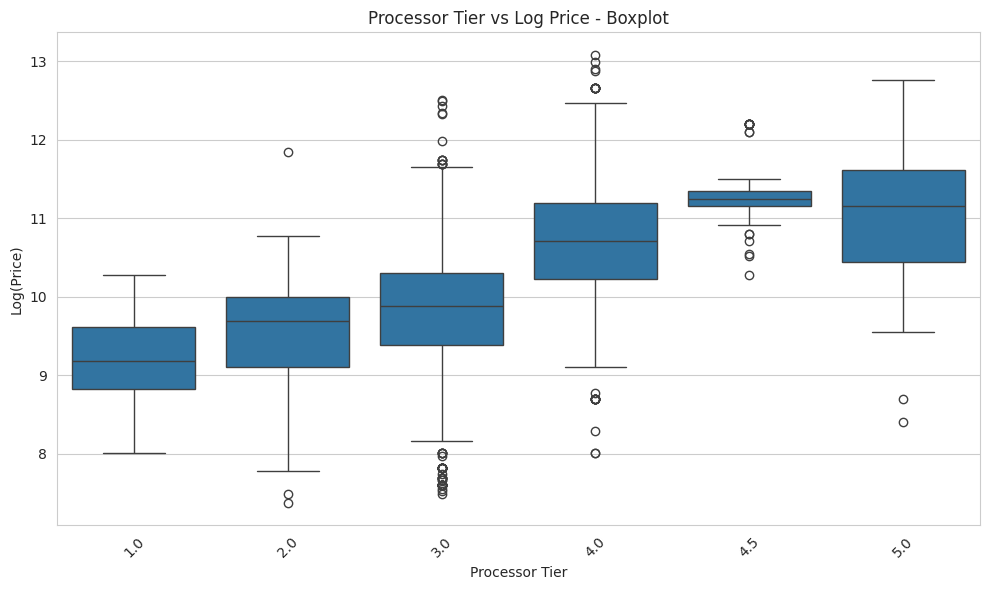

In [115]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df2,
    x='Processor_Tier',
    y='Price'
)

plt.title('Processor Tier vs Log Price - Boxplot')
plt.xlabel('Processor Tier')
plt.ylabel('Log(Price)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

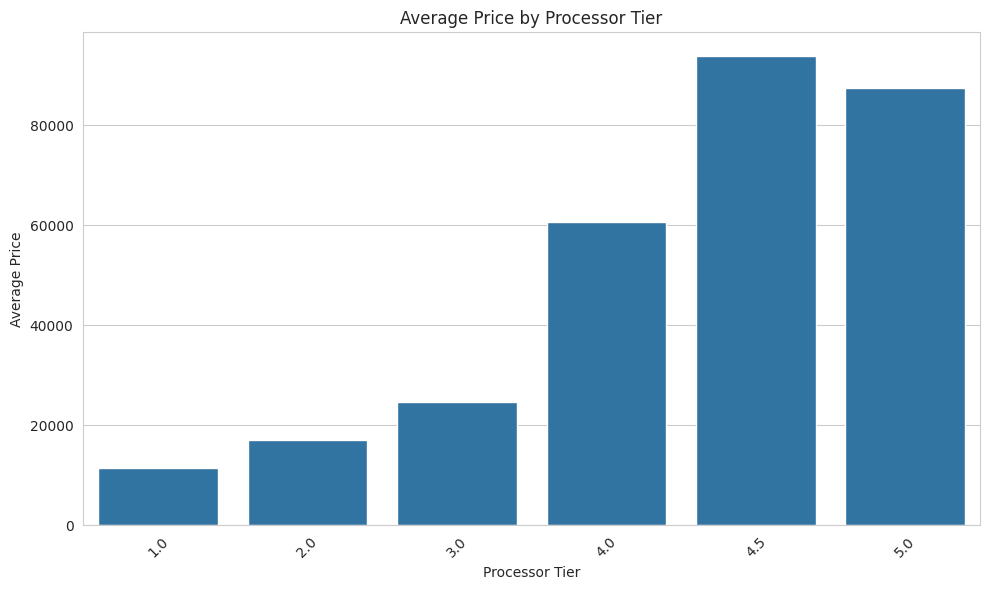

In [116]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x='Processor_Tier',
    y='Price',
    errorbar=None
)

plt.title('Average Price by Processor Tier')
plt.xlabel('Processor Tier')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

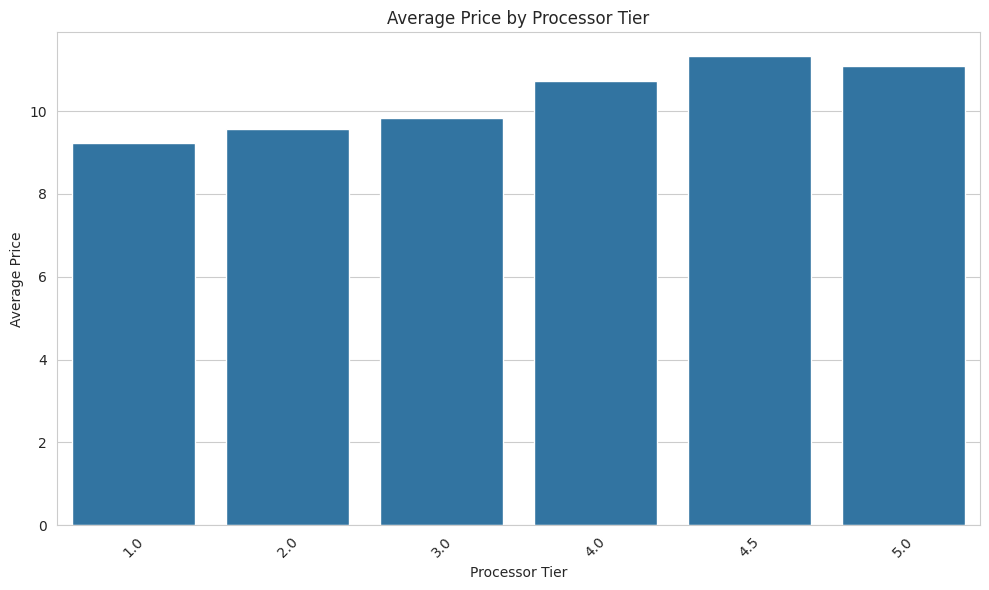

In [117]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df2,
    x='Processor_Tier',
    y='Price',
    errorbar=None
)

plt.title('Average Price by Processor Tier')
plt.xlabel('Processor Tier')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

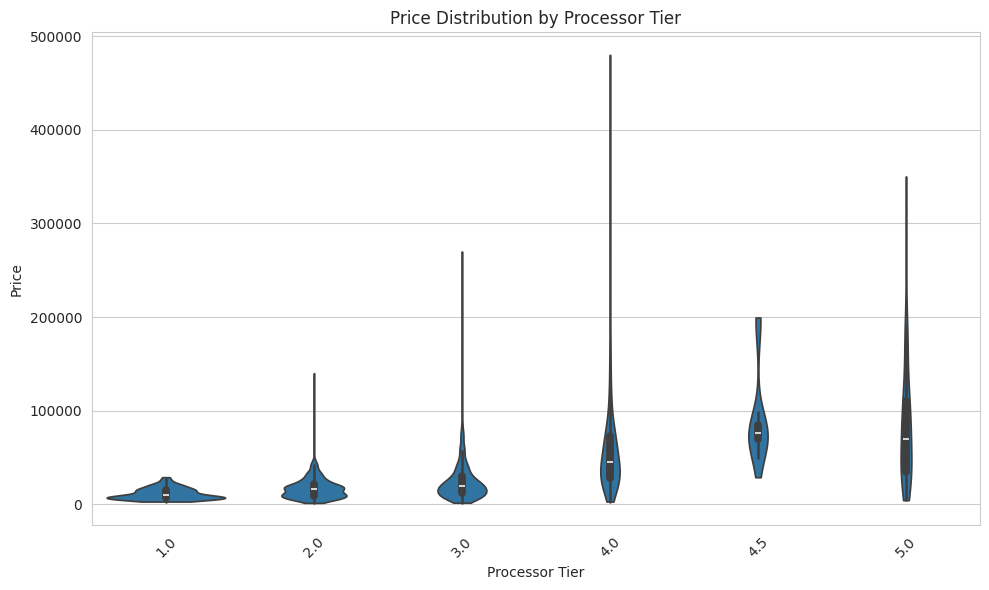

In [118]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x='Processor_Tier',
    y='Price',
    cut=0
)

plt.title('Price Distribution by Processor Tier')
plt.xlabel('Processor Tier')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

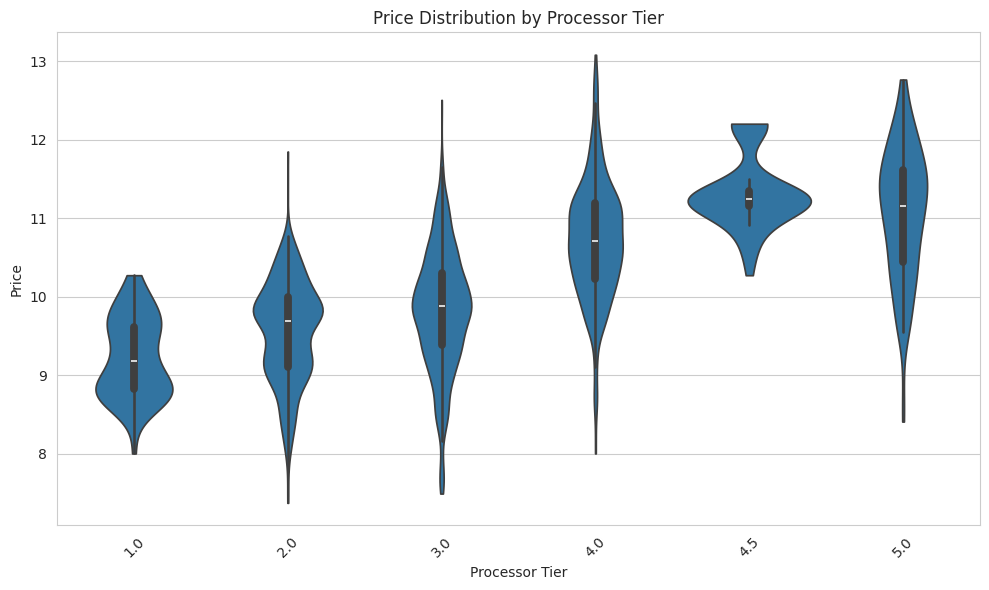

In [119]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df2,
    x='Processor_Tier',
    y='Price',
    cut=0
)

plt.title('Price Distribution by Processor Tier')
plt.xlabel('Processor Tier')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [120]:
overall_mean = df['Price'].mean()

total_ss = ((df['Price'] - overall_mean) ** 2).sum()

group_means = df.groupby(
    'Processor_Tier', observed=True
)['Price'].mean()

group_counts = df.groupby(
    'Processor_Tier', observed=True
)['Price'].count()

between_ss = (
    group_counts * (group_means - overall_mean) ** 2
).sum()

eta = np.sqrt(between_ss / total_ss) if total_ss > 0 else np.nan

print("Eta:", eta)
print("Eta Squared:", eta ** 2 if pd.notna(eta) else np.nan)

Eta: 0.5073942582331787
Eta Squared: 0.25744893328799767


In [121]:
interpret_eta(eta, 'Processor_Tier')

Strong association between Processor_Tier and Price.


In [278]:
overall_mean = df2['Price'].mean()

total_ss = ((df2['Price'] - overall_mean) ** 2).sum()

group_means = df2.groupby(
    'Processor_Tier', observed=True
)['Price'].mean()

group_counts = df2.groupby(
    'Processor_Tier', observed=True
)['Price'].count()

between_ss = (
    group_counts * (group_means - overall_mean) ** 2
).sum()

eta = np.sqrt(between_ss / total_ss) if total_ss > 0 else np.nan

print("Eta:", eta)
print("Eta Squared:", eta ** 2 if pd.notna(eta) else np.nan)

Eta: 0.5223442893829134
Eta Squared: 0.27284355665094084


In [279]:
interpret_eta(eta, 'Processor_Tier')

Strong association between Processor_Tier and Price.


# Bivariate Exploratory Data Analysis (EDA) — `Storage_Type` vs. `Price`

## 1. Summary Statistics and Data Integrity

- **Purpose:** This section compares product prices across storage technology categories.
- **Data Overview:** The code counts storage types and calculates count, mean, median, minimum, maximum, and standard deviation of price for each type.
- **Category Frequencies:** `Unspecified` is the largest group (1,909 listings), followed by `SSD` (1,479), `HDD` (261), `NVMe` (177), and `eMMC` (3).
- **Price Comparison:** In the displayed group summaries, NVMe has a mean price of approximately 45,199, SSD approximately 39,229, `Unspecified` approximately 28,288, and HDD approximately 21,521. The eMMC group has only three listings, so its statistics are not reliable for broad conclusions.

## 2. Visualization Analysis

- **Boxplots:** Compare price distributions across storage types on raw and log scales, showing medians, spread, and potential outliers.
- **Bar Charts:** Compare average raw price and average log price by storage category.
- **Violin Plots:** Show the shape and density of the price distribution within each storage category. Small groups can produce unstable or uninformative density shapes.

## 3. Statistical Analysis — Correlation Ratio (Eta)

- **Eta for raw price:** Approximately `0.1713`.
- **Eta Squared:** Approximately `0.0293` (2.93%).
- **Log-price Eta:** Approximately `0.2636`; Eta squared is approximately `0.0695` (6.95%).

The results indicate a weak association between storage type and price in the current sample. `Unspecified` is a missing/unknown-style category and should not be interpreted as a physical storage technology.

## 4. Key Takeaways and Data Modeling Guidance

- Storage type may provide useful information, but its standalone association with price is weak.
- Keep `Unspecified` separate initially so the model can learn patterns associated with unreported storage details.
- Treat rare categories, especially `eMMC`, cautiously; consider category grouping only if justified and validated.
- Evaluate storage type together with storage capacity, processor, RAM, brand, and product type.

## 5. Conclusion

Prices differ across storage-type groups, with higher means in the NVMe and SSD groups in the reported summaries. However, the Eta results indicate a weak standalone association. Retain `Storage_Type` as a candidate feature and validate its contribution in a multivariable model.

In [123]:
data[['Price', 'Storage_Type']].head()

,Price,Storage_Type
0,65000.0,SSD
1,24999.0,Unspecified
2,5500.0,SSD
3,18000.0,SSD
4,10000.0,Unspecified


In [124]:
data['Storage_Type'].value_counts()

,count
Storage_Type,
Unspecified,1909
SSD,1479
HDD,261
NVMe,177
eMMC,3


In [125]:
df = data[['Price', 'Storage_Type']].copy()

df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

df = df.replace([np.inf, -np.inf], np.nan).dropna(
    subset=['Price', 'Storage_Type']
)

In [280]:
df2 = data[['Price', 'Storage_Type']].copy()

df2['Price'] = pd.to_numeric(df2['Price'], errors='coerce')

df2 = df2.replace([np.inf, -np.inf], np.nan).dropna(
    subset=['Price', 'Storage_Type']
)
df2['Price'] = np.log(df2['Price'])

In [127]:
stats = df.groupby('Storage_Type', observed=True)['Price'].agg(
    ['count', 'mean', 'median', 'min', 'max', 'std']
)

stats.sort_values('mean', ascending=False)

,count,mean,median,min,max,std
Storage_Type,,,,,,
NVMe,177,45199.180791,28999.0,4500.0,290000.0,41425.192511
SSD,1479,39229.280595,25000.0,3000.0,480000.0,45130.669194
Unspecified,1909,28288.404924,19000.0,1599.0,399999.0,31441.378838
HDD,261,21521.321839,12000.0,2499.0,135000.0,24455.154906
eMMC,3,10666.333333,9500.0,9500.0,12999.0,2020.148592


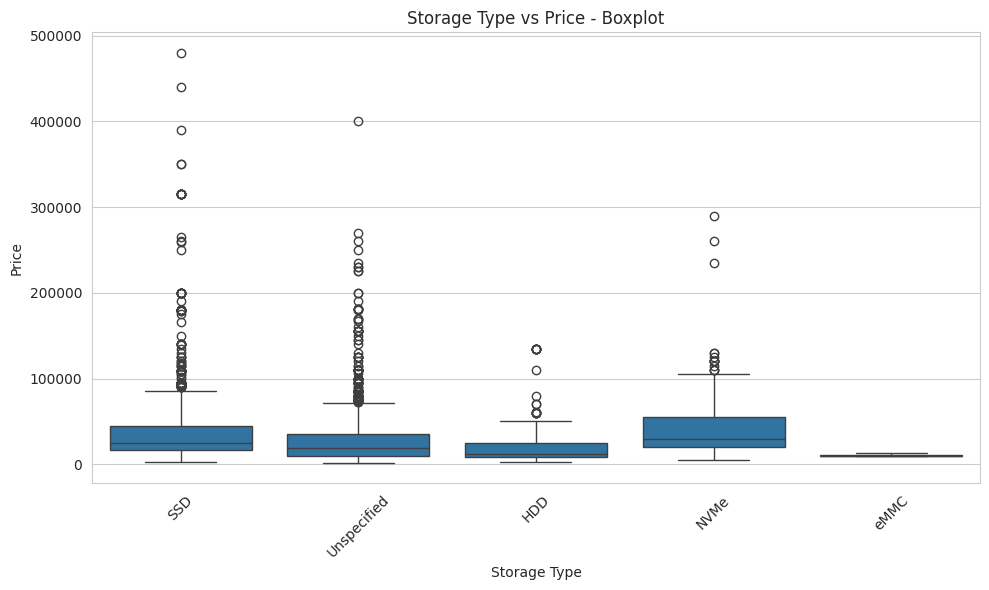

In [128]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Storage_Type',
    y='Price'
)

plt.title('Storage Type vs Price - Boxplot')
plt.xlabel('Storage Type')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

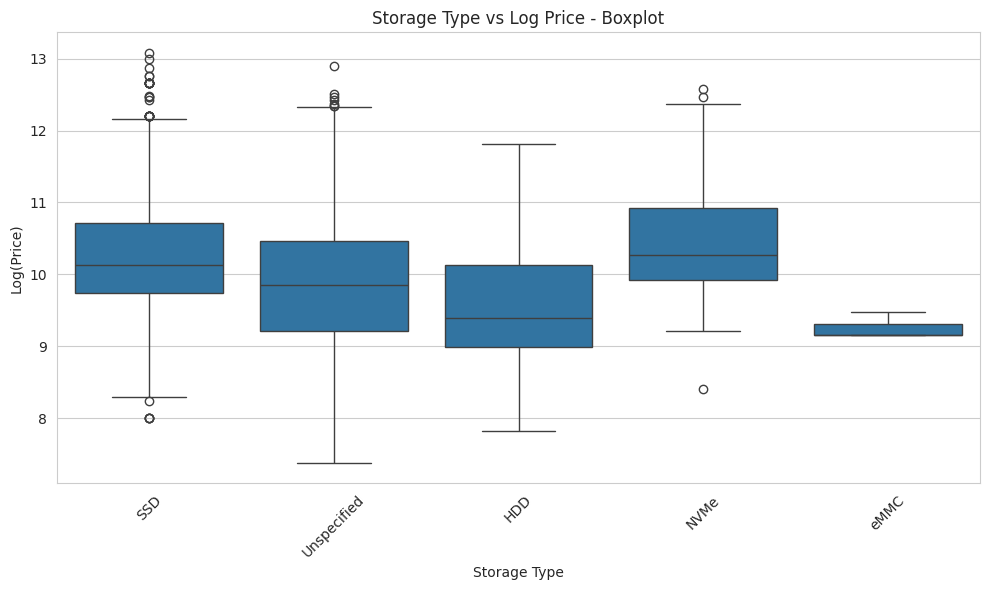

In [129]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df2,
    x='Storage_Type',
    y='Price'
)

plt.title('Storage Type vs Log Price - Boxplot')
plt.xlabel('Storage Type')
plt.ylabel('Log(Price)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

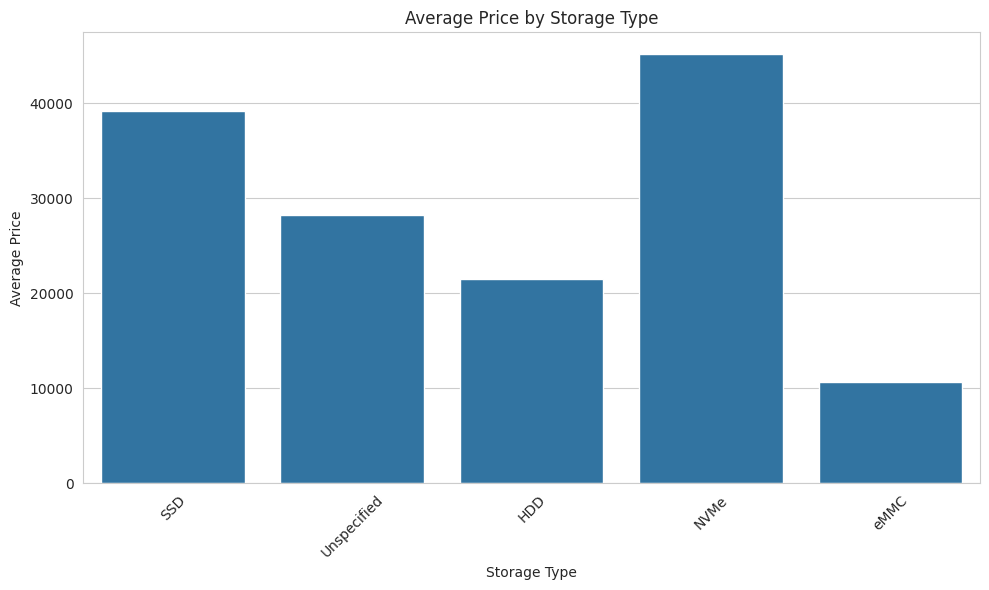

In [130]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x='Storage_Type',
    y='Price',
    errorbar=None
)

plt.title('Average Price by Storage Type')
plt.xlabel('Storage Type')
plt.ylabel('Average Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

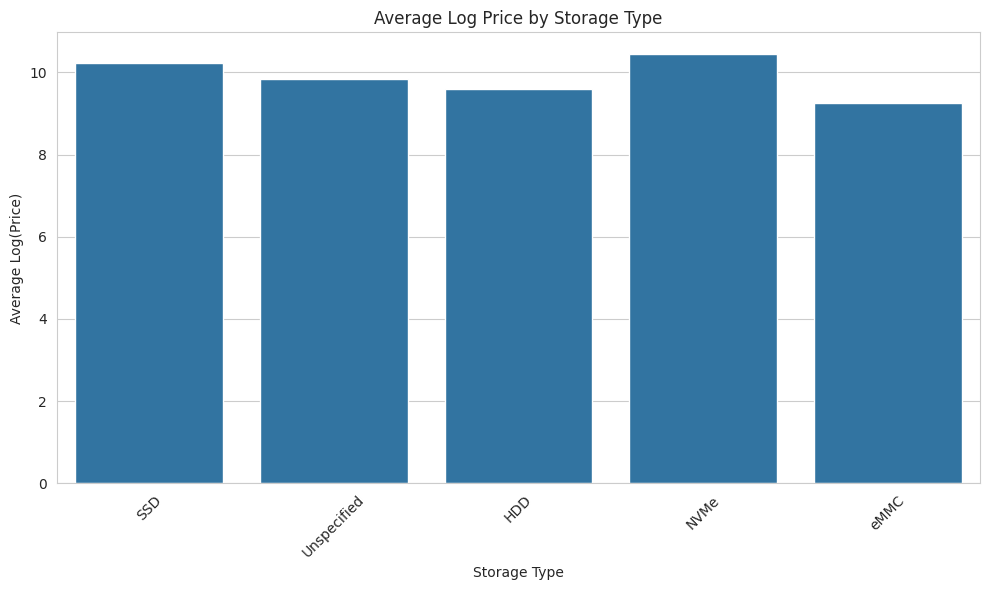

In [131]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df2,
    x='Storage_Type',
    y='Price',
    errorbar=None
)

plt.title('Average Log Price by Storage Type')
plt.xlabel('Storage Type')
plt.ylabel('Average Log(Price)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

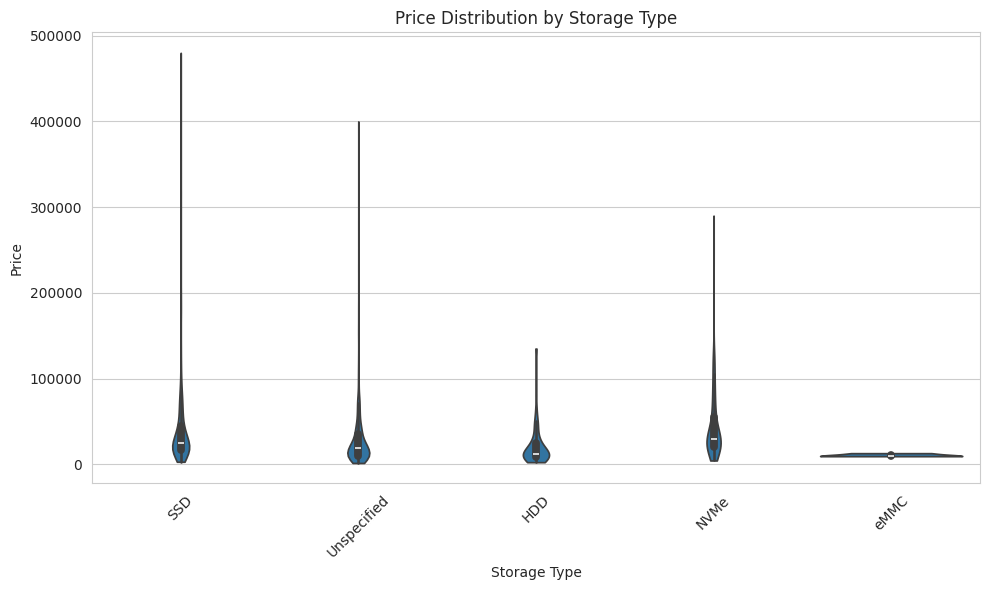

In [132]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x='Storage_Type',
    y='Price',
    cut=0
)

plt.title('Price Distribution by Storage Type')
plt.xlabel('Storage Type')
plt.ylabel('Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

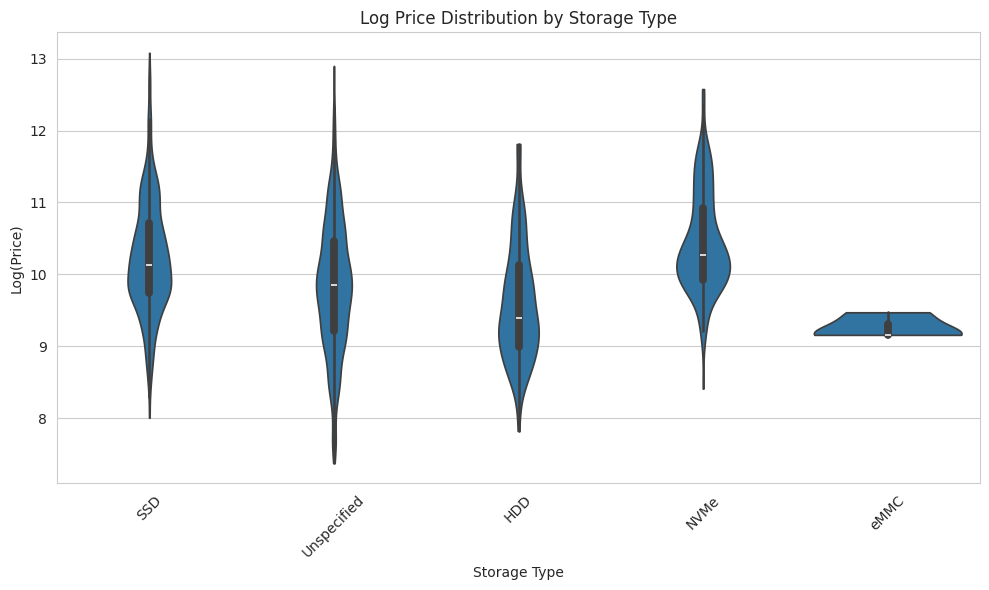

In [133]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df2,
    x='Storage_Type',
    y='Price',
    cut=0
)

plt.title('Log Price Distribution by Storage Type')
plt.xlabel('Storage Type')
plt.ylabel('Log(Price)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [134]:
overall_mean = df['Price'].mean()

total_ss = ((df['Price'] - overall_mean) ** 2).sum()

group_means = df.groupby(
    'Storage_Type', observed=True
)['Price'].mean()

group_counts = df.groupby(
    'Storage_Type', observed=True
)['Price'].count()

between_ss = (
    group_counts * (group_means - overall_mean) ** 2
).sum()

eta = np.sqrt(between_ss / total_ss) if total_ss > 0 else np.nan

print("Eta:", eta)
print("Eta Squared:", eta ** 2 if pd.notna(eta) else np.nan)

Eta: 0.1713083416812509
Eta Squared: 0.0293465479295802


In [135]:
interpret_eta(eta, "Storage_Type")

Weak association between Storage_Type and Price.


In [136]:
overall_mean = df2['Price'].mean()

total_ss = ((df2['Price'] - overall_mean) ** 2).sum()

group_means = df2.groupby(
    'Storage_Type', observed=True
)['Price'].mean()

group_counts = df2.groupby(
    'Storage_Type', observed=True
)['Price'].count()

between_ss = (
    group_counts * (group_means - overall_mean) ** 2
).sum()

eta = np.sqrt(between_ss / total_ss) if total_ss > 0 else np.nan

print("Eta:", eta)
print("Eta Squared:", eta ** 2 if pd.notna(eta) else np.nan)

Eta: 0.2635834198758267
Eta Squared: 0.06947621923343635


In [137]:
interpret_eta(eta, "Storage_Type")

Weak association between Storage_Type and Price.


# Bivariate Exploratory Data Analysis (EDA) — `processor` vs. `Price`

## 1. Summary Statistics and Data Integrity

- **Purpose:** This section compares price distributions across processor families or model categories.
- **Data Overview:** The code counts processor categories and calculates group-level price statistics, then visualizes raw and log-transformed price distributions.
- **Common Categories:** Intel Core i5 is the largest group (2,053 listings), followed by Intel Core i3 (579), Apple M1 (301), Intel Core i7 (300), and AMD Ryzen 5 (235).
- **Price Pattern:** Some less common premium processor groups have high mean prices. For example, AMD Ryzen 9 has a mean around 160,792, Intel Core Ultra around 157,688, and Intel Core i9 around 117,508. These groups are much smaller than the Intel Core i5 group, so comparisons should be cautious.

## 2. Visualization Analysis

- **Boxplots:** Compare the median, spread, and outliers of price across processor categories.
- **Bar Charts:** Compare average price and average log price by processor category.
- **Violin Plots:** Illustrate the distribution density within processor categories. Results for categories with few listings may be unstable.
- **Point Plots:** Show group means and 95% confidence intervals, helping compare estimated average prices while accounting for uncertainty.

## 3. Statistical Analysis — Correlation Ratio (Eta)

- **Eta for raw price:** Approximately `0.6082`.
- **Eta Squared:** Approximately `0.3699` (36.99%).
- **Log-price Eta:** Approximately `0.5813`; Eta squared is approximately `0.3379` (33.79%).

These values indicate a strong association between processor category and price in this dataset. This reflects differences between observed categories, not a causal effect of the processor label alone.

## 4. Key Takeaways and Data Modeling Guidance

- Processor category appears to be a potentially important price-prediction feature.
- Encode `processor` as a categorical feature unless a meaningful numeric ordering is explicitly defined.
- Interpret categories with small counts cautiously and check for inconsistent or overly specific labels.
- Evaluate its incremental value alongside processor tier, brand, RAM, storage, and product type.

## 5. Conclusion

Price differs substantially across processor categories, and Eta indicates a strong association. Processor family is a promising predictor, but small premium-category sample sizes and overlap with brand or processor tier should be considered during model development.

In [139]:
data[['processor', 'Price']].head()

,processor,Price
0,Apple M1,65000.0
1,Intel Core i5,24999.0
2,Intel Pentium,5500.0
3,Intel Core i5,18000.0
4,Intel Core i5,10000.0


In [140]:
data['processor'].value_counts()

,count
processor,
Intel Core i5,2053
Intel Core i3,579
Apple M1,301
Intel Core i7,300
AMD Ryzen 5,235
Apple M2,59
AMD Ryzen 3,54
AMD Ryzen 7,50
Intel Xeon,50


In [141]:
df = data[['processor', 'Price']].copy()

df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

df = df.replace([np.inf, -np.inf], np.nan).dropna(
    subset=['processor', 'Price']
)

In [283]:
df2 = data[['processor', 'Price']].copy()

df2['Price'] = pd.to_numeric(df2['Price'], errors='coerce')
df2 = df2.replace([np.inf, -np.inf], np.nan).dropna(
    subset=['processor', 'Price']
)
df2['Price'] = np.log(df2['Price'])

In [142]:
stats = df.groupby('processor', observed=True)['Price'].agg(
    ['count', 'mean', 'median', 'min', 'max', 'std']
)

stats.sort_values('mean', ascending=False)

,count,mean,median,min,max,std
processor,,,,,,
AMD Ryzen 9,12,160791.583333,132500.0,65000.0,350000.0,96190.077333
Intel Core Ultra,11,157688.454545,120786.0,62000.0,399999.0,103886.648157
Intel Core i9,39,117507.589744,109999.0,13999.0,290000.0,71747.149541
Apple M2,59,93864.254237,76500.0,29000.0,199500.0,50986.284637
Apple M3,24,85587.500000,92900.0,33000.0,94500.0,17839.753179
Apple M1,301,79264.644518,60000.0,3000.0,480000.0,69632.507977
AMD Ryzen 7,50,74557.880000,63500.0,25000.0,260000.0,41599.528182
Intel Xeon,50,47413.800000,29999.0,4500.0,135000.0,38927.716501
AMD Ryzen 5,235,39199.004255,35000.0,4500.0,265000.0,27346.640007


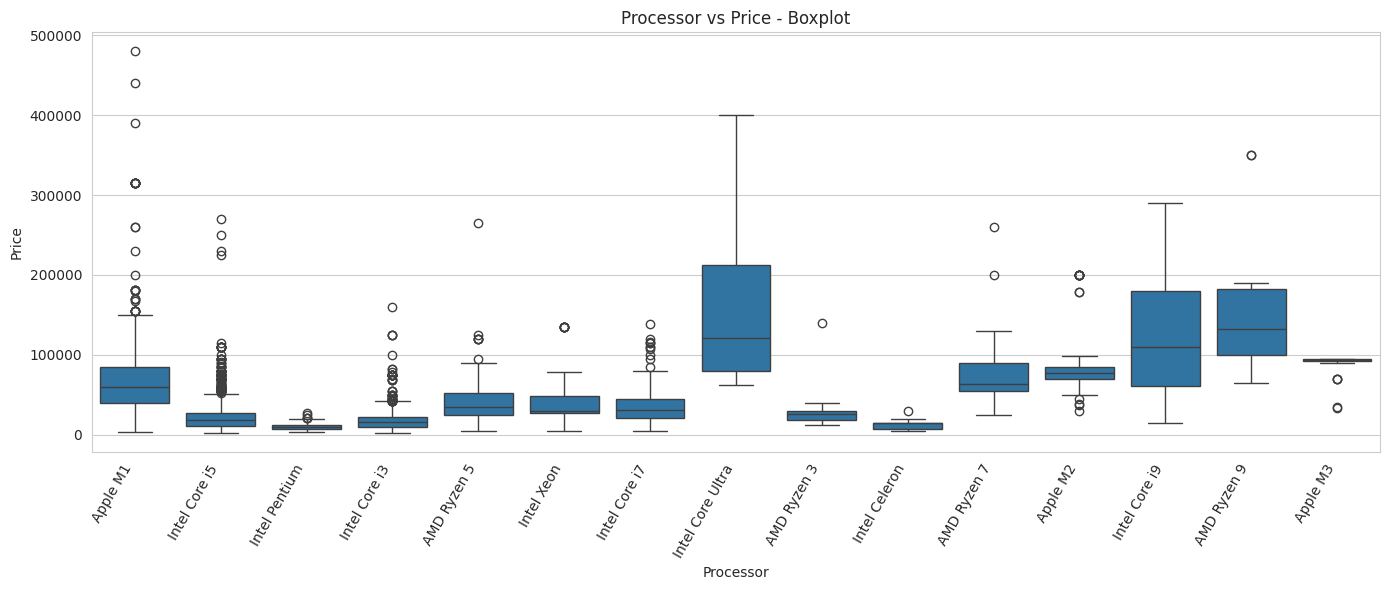

In [143]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x='processor',
    y='Price'
)

plt.title('Processor vs Price - Boxplot')
plt.xlabel('Processor')
plt.ylabel('Price')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

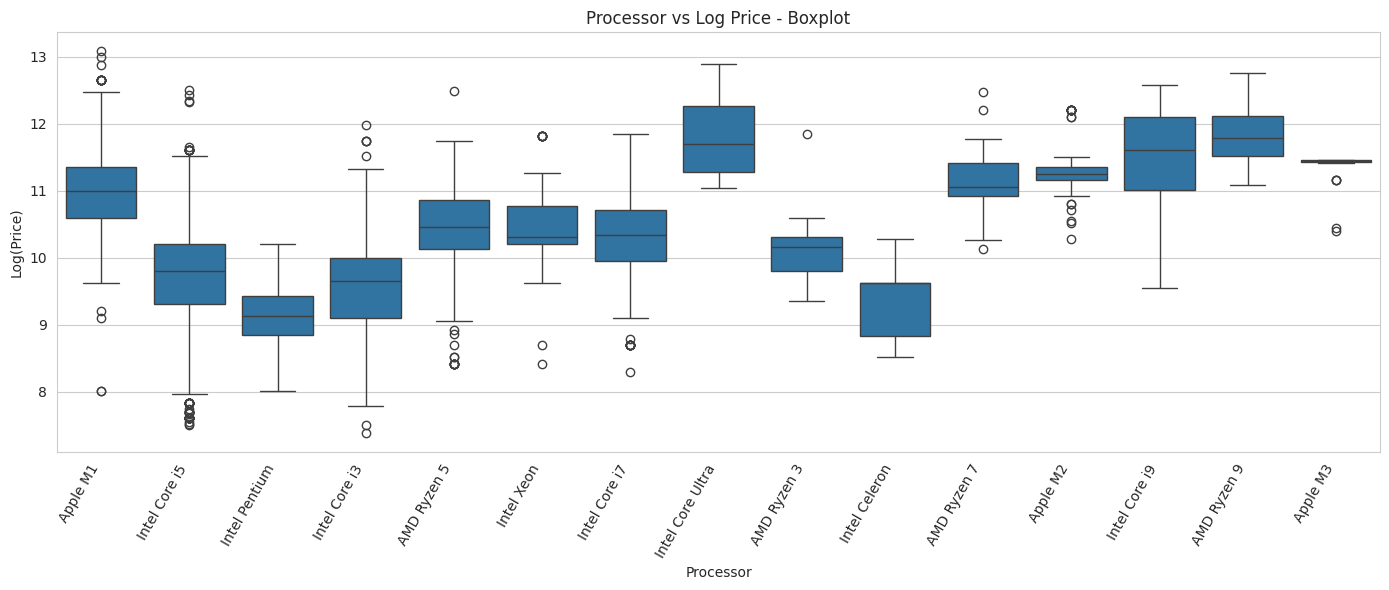

In [284]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df2,
    x='processor',
    y='Price'
)

plt.title('Processor vs Log Price - Boxplot')
plt.xlabel('Processor')
plt.ylabel('Log(Price)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

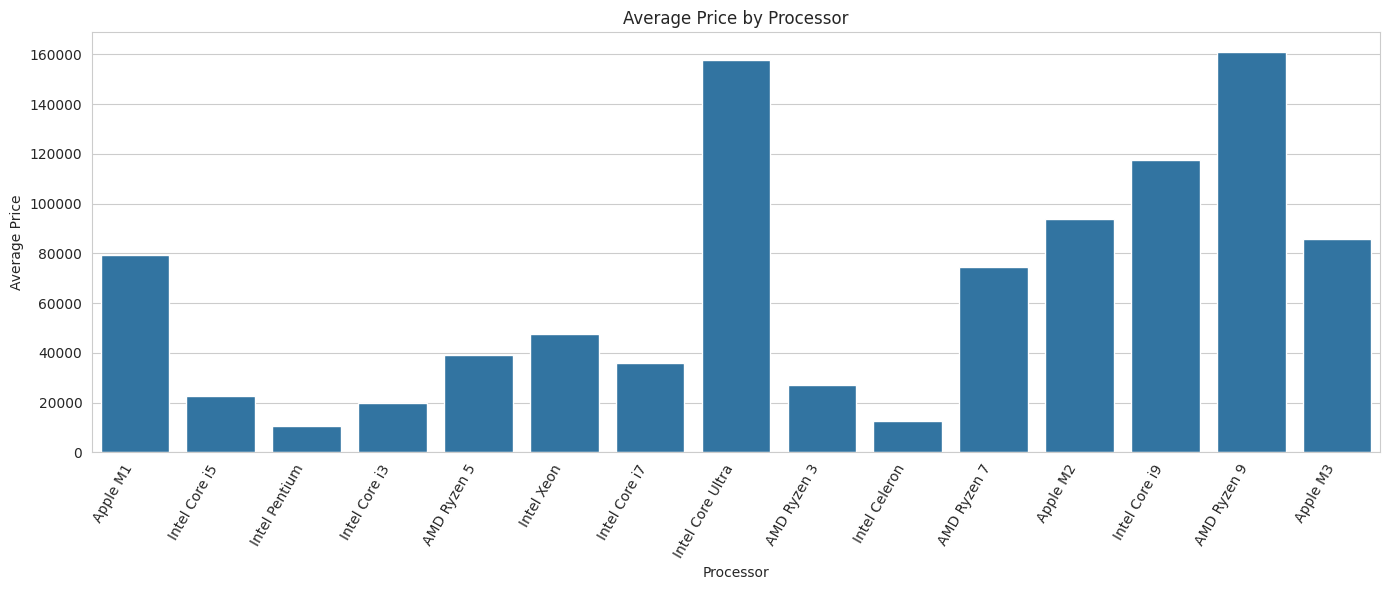

In [144]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=df,
    x='processor',
    y='Price',
    errorbar=None
)

plt.title('Average Price by Processor')
plt.xlabel('Processor')
plt.ylabel('Average Price')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

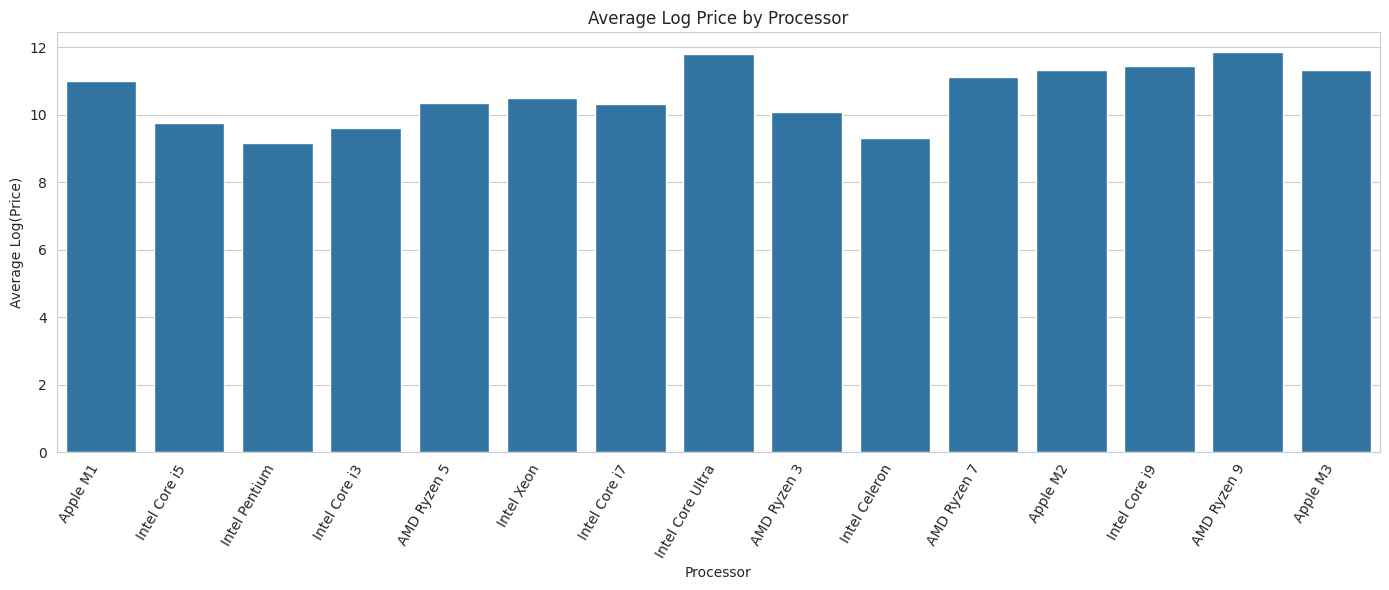

In [285]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=df2,
    x='processor',
    y='Price',
    errorbar=None
)

plt.title('Average Log Price by Processor')
plt.xlabel('Processor')
plt.ylabel('Average Log(Price)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

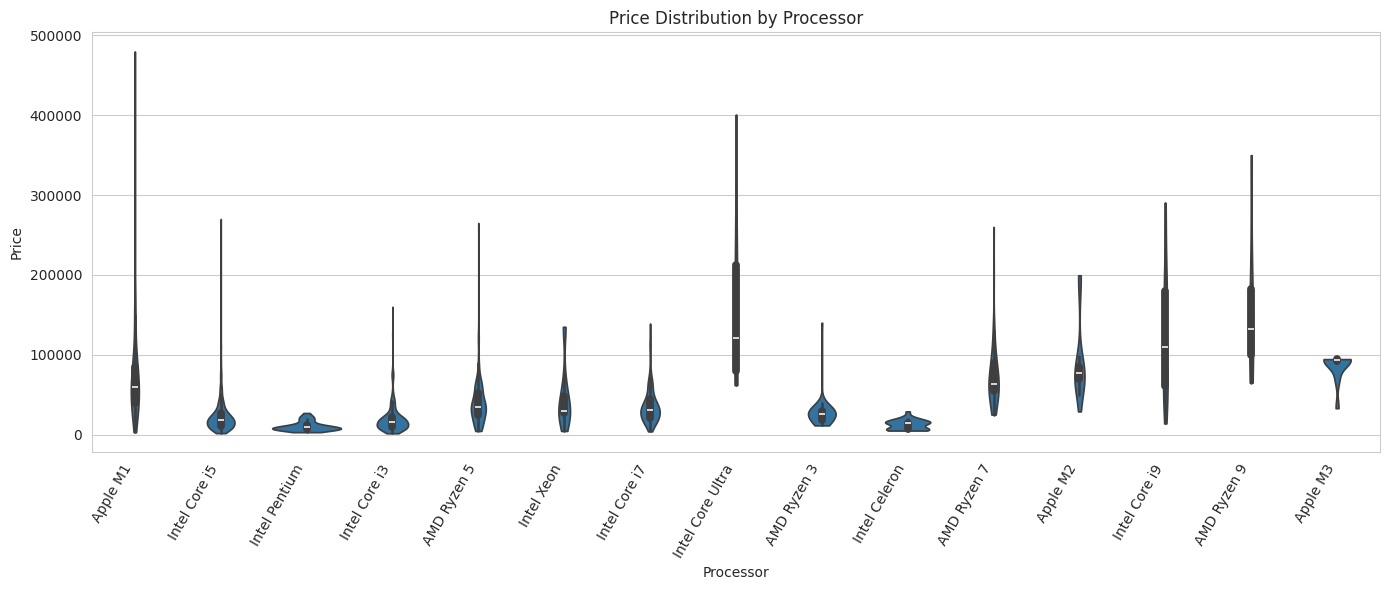

In [145]:
plt.figure(figsize=(14, 6))

sns.violinplot(
    data=df,
    x='processor',
    y='Price',
    cut=0
)

plt.title('Price Distribution by Processor')
plt.xlabel('Processor')
plt.ylabel('Price')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

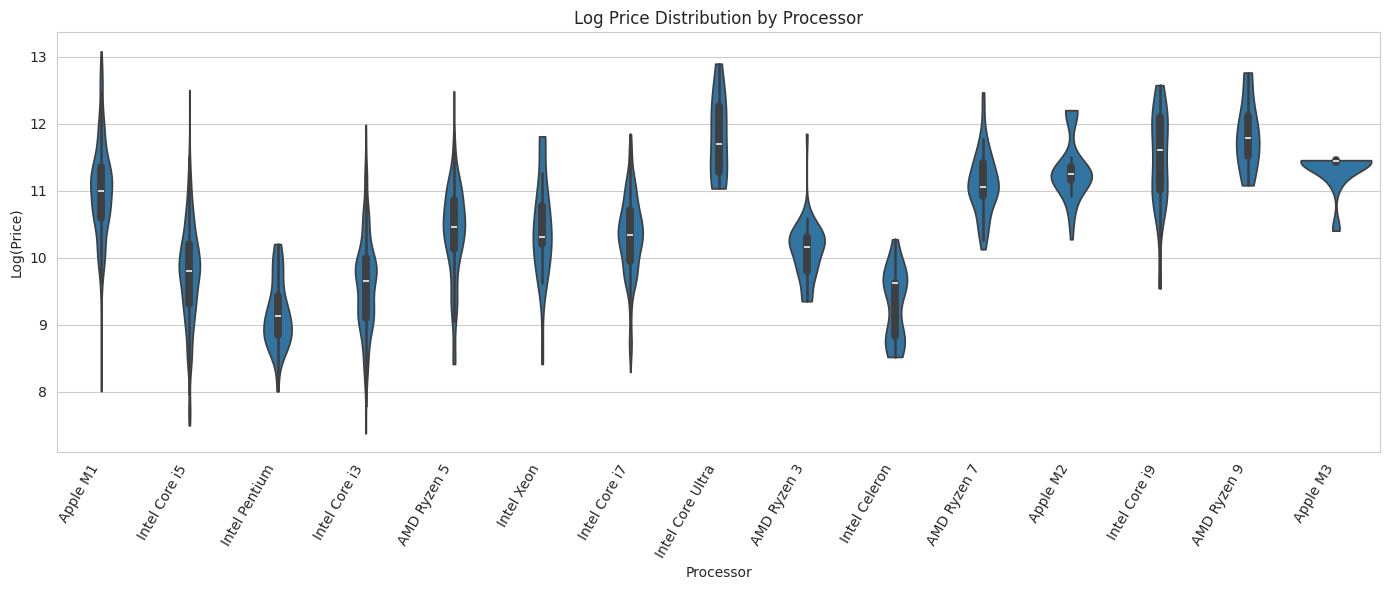

In [286]:
plt.figure(figsize=(14, 6))

sns.violinplot(
    data=df2,
    x='processor',
    y='Price',
    cut=0
)

plt.title('Log Price Distribution by Processor')
plt.xlabel('Processor')
plt.ylabel('Log(Price)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

In [146]:
overall_mean = df['Price'].mean()

total_ss = ((df['Price'] - overall_mean) ** 2).sum()

group_means = df.groupby('processor', observed=True)['Price'].mean()
group_counts = df.groupby('processor', observed=True)['Price'].count()

between_ss = (
    group_counts * (group_means - overall_mean) ** 2
).sum()

eta = np.sqrt(between_ss / total_ss) if total_ss > 0 else np.nan

print("Eta:", eta)
print("Eta Squared:", eta ** 2 if pd.notna(eta) else np.nan)

Eta: 0.6082143176804784
Eta Squared: 0.3699246562315299


In [147]:
interpret_eta(eta, "processor")

Strong association between processor and Price.


In [287]:
overall_mean = df2['Price'].mean()

total_ss = ((df2['Price'] - overall_mean) ** 2).sum()

group_means = df2.groupby('processor', observed=True)['Price'].mean()
group_counts = df2.groupby('processor', observed=True)['Price'].count()

between_ss = (
    group_counts * (group_means - overall_mean) ** 2
).sum()

eta = np.sqrt(between_ss / total_ss) if total_ss > 0 else np.nan

print("Eta:", eta)
print("Eta Squared:", eta ** 2 if pd.notna(eta) else np.nan)

Eta: 0.5812796506824199
Eta Squared: 0.33788603229747616


In [288]:
interpret_eta(eta, "processor")

Strong association between processor and Price.


# Bivariate Exploratory Data Analysis (EDA) — `Warranty_Days_filled` vs. `Price`

## 1. Summary Statistics and Data Integrity

- **Purpose:** This section examines whether the number of warranty days is associated with product price.
- **Data Overview:** `Warranty_Days_filled` is converted to an integer and compared with `Price` using descriptive statistics, plots, correlation tests, and grouped summaries.
- **Zero-Warranty Group:** 3,224 listings have a value of `0`, with a mean price of approximately 29,411 and a median of 20,000. This group dominates the data.
- **Nonzero Values:** Warranty lengths include 10, 30, 90, 180, 365, 730, 1,095 days, and other less common values. Several durations have very few listings, so their group means are unstable.

## 2. Visualization Analysis

- **Scatterplot and Trend Plots:** Show the relationship between warranty days and price. The concentration at zero and sparse values at many other durations make a smooth trend difficult to estimate reliably.
- **Raw and Log Price Views:** Help compare the price relationship before and after compressing extreme prices.
- **Grouped Summaries:** Compare count, mean, and median price by warranty duration. The 30-day group has a mean price around 59,560, but this should be interpreted alongside its sample composition and the much larger zero-day group.

## 3. Statistical Analysis — Pearson and Spearman Correlation

- **Pearson correlation (raw price):** Approximately `0.0822` with p-value around `3.51 × 10⁻⁷`, indicating a very weak positive linear association.
- **Spearman correlation:** Approximately `0.1474` with a very small p-value, indicating a weak positive monotonic association.
- The code also computes correlations using the transformed price values; those coefficients are small in magnitude as well.

With a large dataset, even weak correlations can have small p-values. The magnitude of the association is more informative about practical strength than statistical significance alone.

## 4. Key Takeaways and Data Modeling Guidance

- Warranty duration has a weak standalone relationship with price, and the large zero-day group dominates the distribution.
- Treat `Warranty_Days_filled` carefully: zero may represent no warranty or an unavailable warranty value, depending on the preprocessing definition.
- Consider a separate indicator for warranty presence and, if useful, a transformed or grouped duration feature.
- Avoid interpreting group means for rare durations as robust estimates.
- Use cross-validation to determine whether warranty duration adds predictive value beyond `Has_Warranty`, brand, and hardware specifications.

## 5. Conclusion

The correlations show a weak positive relationship between warranty days and price. Because most records have zero days and many other durations are rare, the feature should be interpreted cautiously and validated alongside the separate warranty-presence indicator.

In [148]:
data['Warranty_Days_filled'] = data['Warranty_Days_filled'].astype('int')

In [149]:
data['Warranty_Days_filled'].value_counts()

,count
Warranty_Days_filled,
0,3224
30,365
365,71
10,51
90,28
180,21
730,16
1095,11
120,10


In [150]:
data[['Warranty_Days_filled', 'Price']].head()

,Warranty_Days_filled,Price
0,0,65000.0
1,0,24999.0
2,0,5500.0
3,10,18000.0
4,0,10000.0


In [151]:
df = data[['Warranty_Days_filled', 'Price']].copy()

df['Warranty_Days_filled'] = pd.to_numeric(
    df['Warranty_Days_filled'], errors='coerce'
)

df['Price'] = pd.to_numeric(df['Price'], errors='coerce')

df = df.replace([np.inf, -np.inf], np.nan).dropna(
    subset=['Warranty_Days_filled', 'Price']
)

In [289]:
df2 = data[['Warranty_Days_filled', 'Price']].copy()

df2['Price'] = pd.to_numeric(df2['Price'], errors='coerce')
df2['Warranty_Days_filled'] = pd.to_numeric(df2['Warranty_Days_filled'], errors='coerce')

df2 = df2.replace([np.inf, -np.inf], np.nan).dropna(
    subset=['Warranty_Days_filled', 'Price']
)
df2['Price'] = np.log(df2['Price'])

In [152]:
df[['Warranty_Days_filled', 'Price']].describe()

,Warranty_Days_filled,Price
count,3829.000000,3829.000000
mean,20.459650,32821.099504
std,101.762666,37959.755574
min,0.000000,1599.000000
25%,0.000000,12500.000000
50%,0.000000,21000.000000
75%,0.000000,39500.000000
max,1825.000000,480000.000000


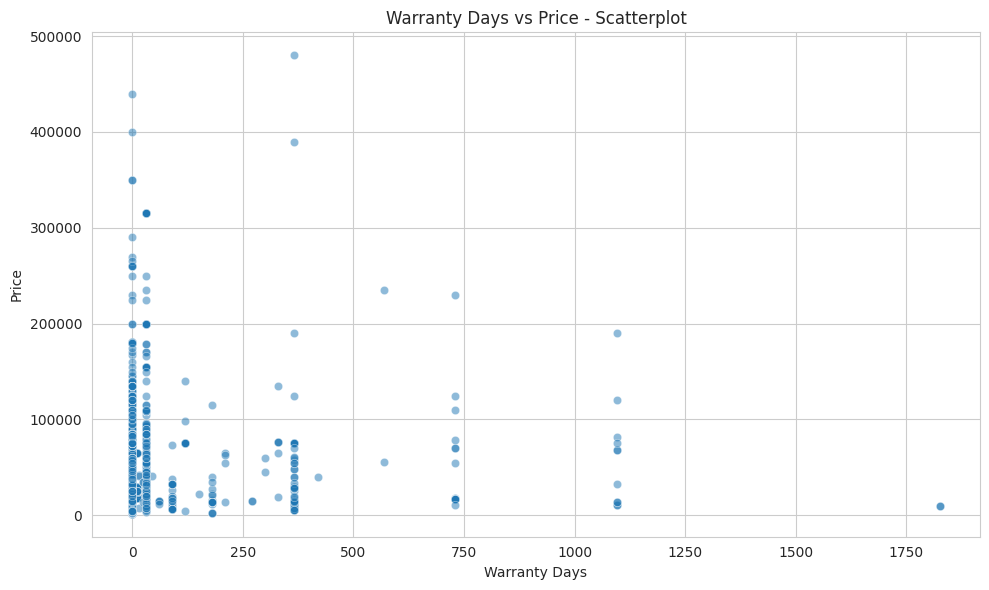

In [153]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Warranty_Days_filled',
    y='Price',
    alpha=0.5
)

plt.title('Warranty Days vs Price - Scatterplot')
plt.xlabel('Warranty Days')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

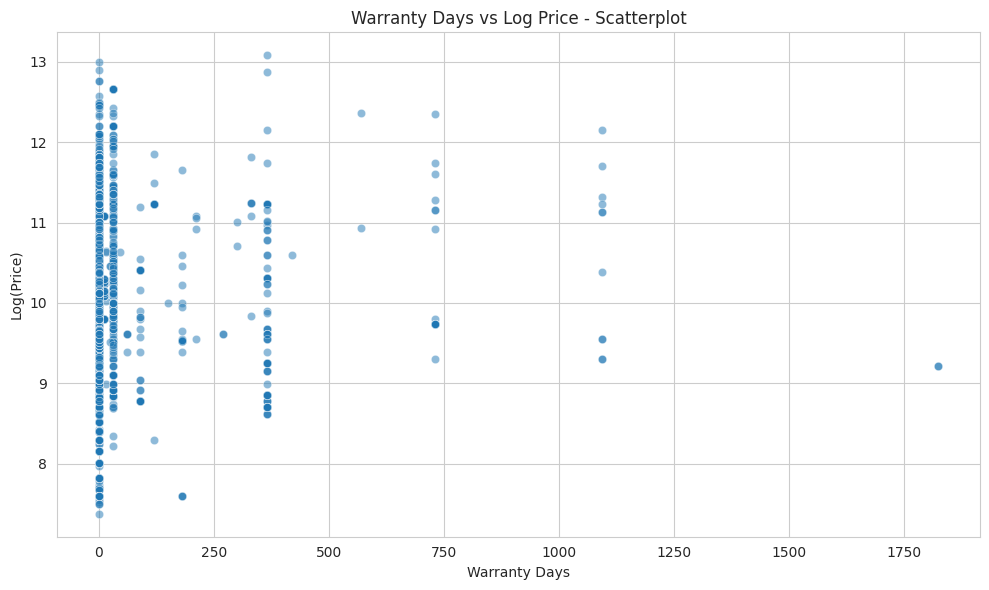

In [290]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df2,
    x='Warranty_Days_filled',
    y='Price',
    alpha=0.5
)

plt.title('Warranty Days vs Log Price - Scatterplot')
plt.xlabel('Warranty Days')
plt.ylabel('Log(Price)')
plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/statsmodels/nonparametric/smoothers_lowess.py:237: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(


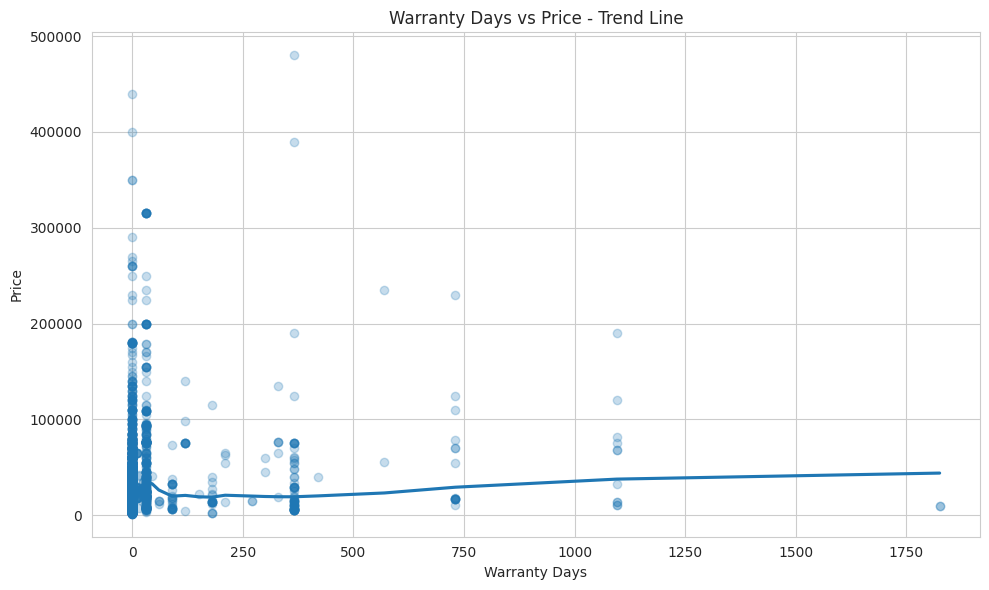

In [154]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x='Warranty_Days_filled',
    y='Price',
    lowess=True,
    scatter_kws={'alpha': 0.25}
)

plt.title('Warranty Days vs Price - Trend Line')
plt.xlabel('Warranty Days')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/statsmodels/nonparametric/smoothers_lowess.py:237: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(


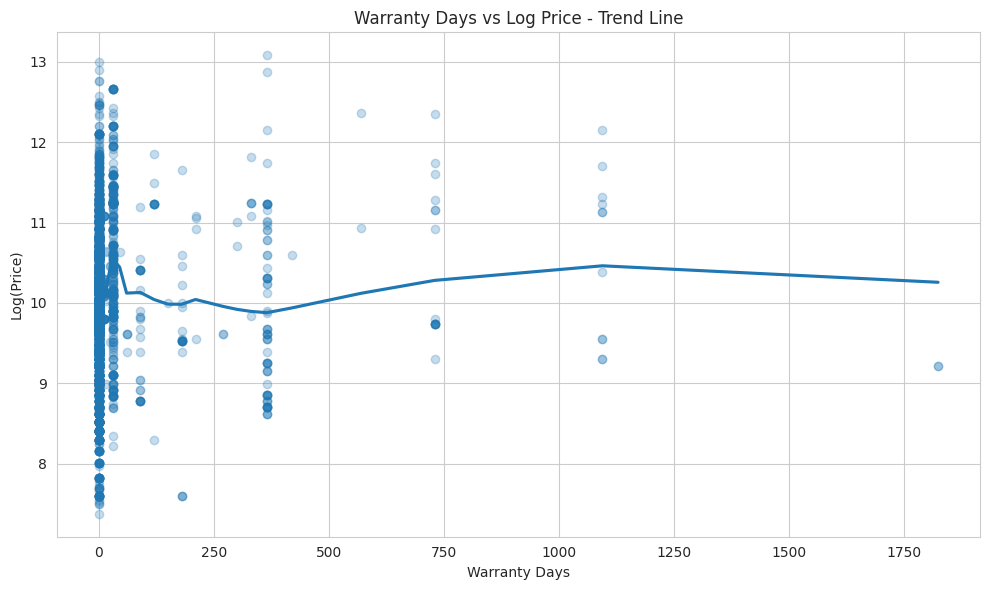

In [291]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df2,
    x='Warranty_Days_filled',
    y='Price',
    lowess=True,
    scatter_kws={'alpha': 0.25}
)

plt.title('Warranty Days vs Log Price - Trend Line')
plt.xlabel('Warranty Days')
plt.ylabel('Log(Price)')
plt.tight_layout()
plt.show()

In [155]:
if (
    len(df) >= 2
    and df['Warranty_Days_filled'].nunique() > 1
    and df['Price'].nunique() > 1
):
    pearson_corr, pearson_p = pearsonr(
        df['Warranty_Days_filled'],
        df['Price']
    )

    spearman_corr, spearman_p = spearmanr(
        df['Warranty_Days_filled'],
        df['Price']
    )

    print("Pearson Correlation:", pearson_corr)
    print("Pearson P-value:", pearson_p)

    print("\nSpearman Correlation:", spearman_corr)
    print("Spearman P-value:", spearman_p)
else:
    print("Not enough variation or observations to calculate correlations.")

Pearson Correlation: 0.08220545593470015
Pearson P-value: 3.5105657992449326e-07

Spearman Correlation: 0.14744767370971013
Spearman P-value: 4.6825741169366783e-20


In [156]:
def interpret_correlation(corr, column_name):
    if pd.isna(corr):
        print(f"Correlation between {column_name} and Price cannot be calculated.")
        return

    abs_corr = abs(corr)

    if abs_corr < 0.2:
        strength = "Very weak"
    elif abs_corr < 0.4:
        strength = "Weak"
    elif abs_corr < 0.6:
        strength = "Moderate"
    elif abs_corr < 0.8:
        strength = "Strong"
    else:
        strength = "Very strong"

    if corr > 0:
        direction = "positive"
    elif corr < 0:
        direction = "negative"
    else:
        print(f"No linear correlation between {column_name} and Price.")
        return

    print(f"{strength} {direction} correlation between {column_name} and Price.")

interpret_correlation(
    df['Warranty_Days_filled'].corr(df['Price']),
    'Warranty_Days_filled'
)

Very weak positive correlation between Warranty_Days_filled and Price.


In [292]:
if (
    len(df2) >= 2
    and df2['Warranty_Days_filled'].nunique() > 1
    and df2['Price'].nunique() > 1
):
    pearson_corr, pearson_p = pearsonr(
        df2['Warranty_Days_filled'],
        df2['Price']
    )

    spearman_corr, spearman_p = spearmanr(
        df2['Warranty_Days_filled'],
        df2['Price']
    )

    print("Pearson Correlation:", pearson_corr)
    print("Pearson P-value:", pearson_p)

    print("\nSpearman Correlation:", spearman_corr)
    print("Spearman P-value:", spearman_p)
else:
    print("Not enough variation or observations to calculate correlations.")

Pearson Correlation: 0.04838227353287429
Pearson P-value: 0.0027478806030431756

Spearman Correlation: 0.14744767370971013
Spearman P-value: 4.6825741169366783e-20


In [293]:
interpret_correlation(
    df2['Warranty_Days_filled'].corr(df2['Price']),
    'Warranty_Days_filled'
)

Very weak positive correlation between Warranty_Days_filled and Price.


In [157]:
warranty_stats = df.groupby('Warranty_Days_filled')['Price'].agg(
    ['count', 'mean', 'median', 'min', 'max', 'std']
).sort_index()

warranty_stats

,count,mean,median,min,max,std
Warranty_Days_filled,,,,,,
0,3224,29411.036600,20000.0,1599.0,439999.0,31450.919135
10,51,28980.392157,24900.0,18000.0,65000.0,13727.388967
15,4,28499.750000,32000.0,7999.0,42000.0,16406.716112
25,3,27766.666667,34900.0,13500.0,34900.0,12355.295761
30,365,59559.652055,38000.0,3697.0,315500.0,61948.634468
45,1,41500.000000,41500.0,41500.0,41500.0,NaN
60,4,14249.750000,15000.0,11999.0,15000.0,1500.500000
90,28,20106.357143,16995.5,6500.0,72999.0,15303.478656
120,10,76700.000000,75000.0,4000.0,140000.0,32941.193394


<Axes: xlabel='Warranty_Days_filled', ylabel='Price'>

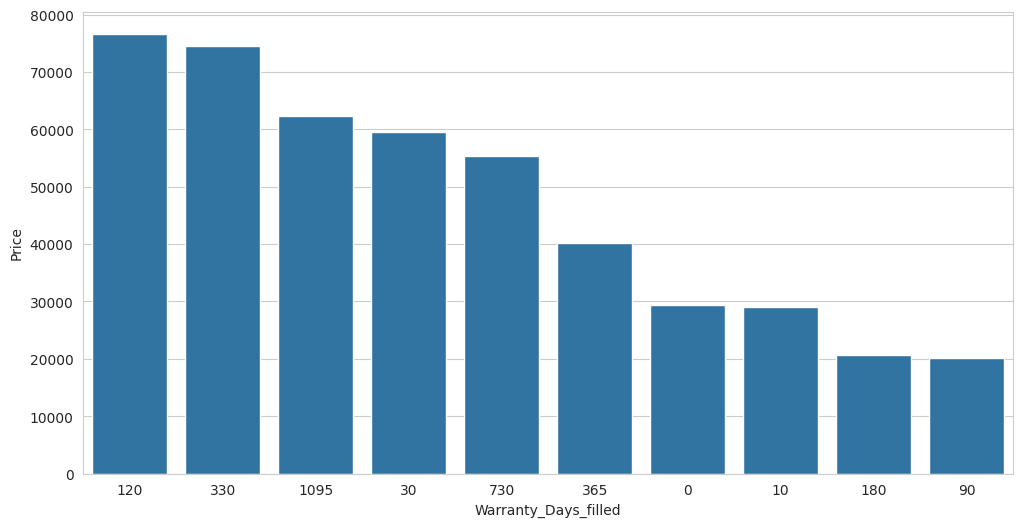

In [158]:
top_warranty = (
    df['Warranty_Days_filled']
    .value_counts()
    .head(10)
    .index
)

plot_df = df[df['Warranty_Days_filled'].isin(top_warranty)].copy()

order = (
    plot_df.groupby('Warranty_Days_filled')['Price']
    .mean()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x='Warranty_Days_filled',
    y='Price',
    order=order,
    errorbar=None
)

In [159]:
df.groupby('Warranty_Days_filled')['Price'].agg(['count', 'mean', 'median']).loc[[0.0]]

,count,mean,median
Warranty_Days_filled,,,
0,3224,29411.0366,20000.0


In [160]:
data.sample(3)

,Price,Brand,Type,Has_Warranty,RAM_GB,RAM_missing,ROM_GB,ROM_Missing,Screen_Size,Screen_Size_missing,Processor_Tier,Processor_Tier_missing,Storage_Type,processor,Warranty_Days_filled,Warranty_Days_was_missing
1304,20000.0,dell,Laptop,0,8,0,256.0,1,14.0,1,2.0,0,Unspecified,Intel Core i3,0,0
3008,18000.0,hp,Laptop,0,4,0,500.0,0,15.6,1,2.0,0,HDD,AMD Ryzen 3,0,0
2853,42000.0,others,Laptop,0,16,0,500.0,1,15.6,0,3.0,0,Unspecified,Intel Core i5,0,0


# Bivariate Exploratory Data Analysis (EDA) — `Brand` vs. `Type`

## 1. Summary Statistics and Data Integrity

- **Purpose:** This analysis examines whether the mix of product types (Laptop or Computer) differs across brands.
- **Data Overview:** The code identifies 13 brands and two product types, counts their frequencies, and creates a contingency table of brand-by-type counts.
- **Frequency Patterns:** The dataset includes brands with many laptop and computer listings, while a few brands have very small counts. These sparse categories can affect statistical tests and percentage comparisons.

## 2. Visualization Analysis

- **Frequency Charts:** Show the most common brands and the overall distribution of product types.
- **Grouped and Stacked Bar Charts:** Compare the number of laptops and computers within brands, including a view focused on the most frequent brands.
- **Percentage Charts:** Normalize counts within each brand to compare the proportion of laptops and computers rather than absolute sample sizes.
- **Contingency Heatmap:** Highlights combinations with high or low counts.

## 3. Statistical Analysis — Chi-Square Test and Cramér's V

- **Chi-square statistic:** Approximately `959.76`.
- **p-value:** Approximately `8.34 × 10⁻¹⁹⁸`, indicating a statistically significant association between brand and type in this sample.
- **Cramér's V:** Approximately `0.5007`, which the notebook's interpretation thresholds classify as a strong association.

The test indicates that the distribution of product type is not independent of brand. Some brand categories are sparse, so inspect expected cell counts before relying heavily on the chi-square p-value.

## 4. Key Takeaways and Data Modeling Guidance

- Brand and product type are associated in the observed data; some brands are more strongly represented in one product type.
- Both features may be useful in a price model, but their overlapping information should be assessed through validation.
- Consider rare-brand handling based on training data only.
- Interpret percentages with their underlying counts, especially for brands with very few records.

## 5. Conclusion

The chi-square test and Cramér's V suggest an association between `Brand` and `Type`. The visualizations show how product-type composition varies by brand. This relationship is useful for understanding the dataset, but it does not imply that brand determines product type.

In [161]:
df = data[['Brand', 'Type']].copy()

In [162]:
print("Number of unique brands:", df['Brand'].nunique())
print("Number of unique types:", df['Type'].nunique())

print("\nUnique brands:")
print(sorted(df['Brand'].unique().tolist()))

print("\nUnique types:")
print(sorted(df['Type'].unique().tolist()))

Number of unique brands: 13
Number of unique types: 2

Unique brands:
['acer', 'asus', 'dell', 'hp', 'huawei', 'lenovo', 'macbook', 'microsoft', 'msi', 'others', 'raspberry pi', 'samsung', 'sony']

Unique types:
['Computer', 'Laptop']


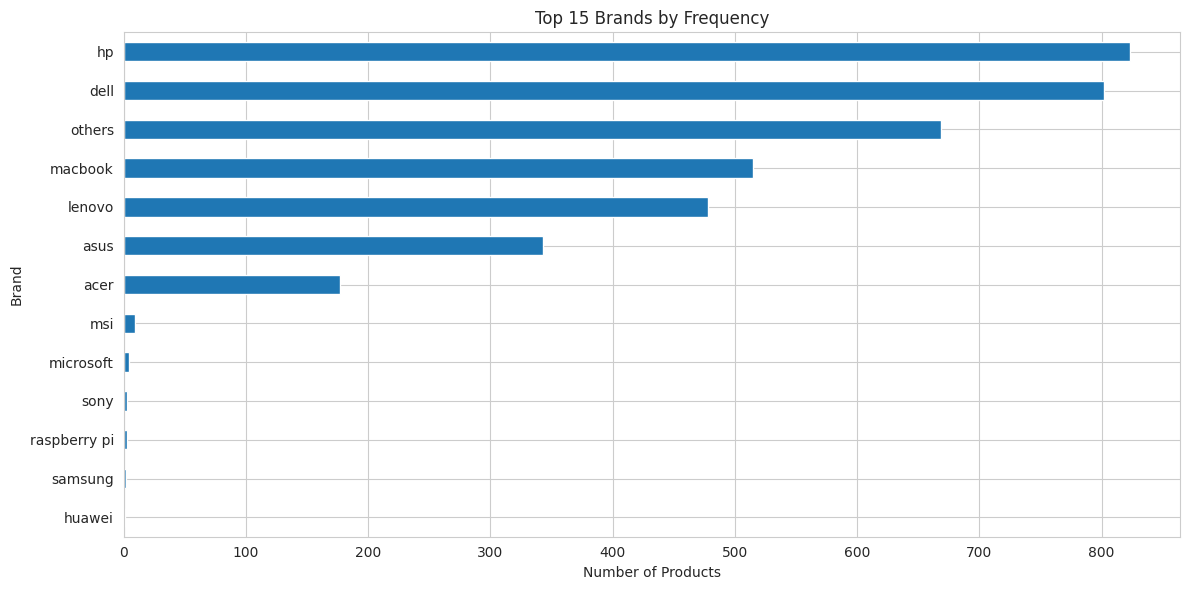

In [163]:
brand_counts = df['Brand'].value_counts()

plt.figure(figsize=(12, 6))
brand_counts.sort_values().plot(kind='barh')

plt.title("Top 15 Brands by Frequency")
plt.xlabel("Number of Products")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

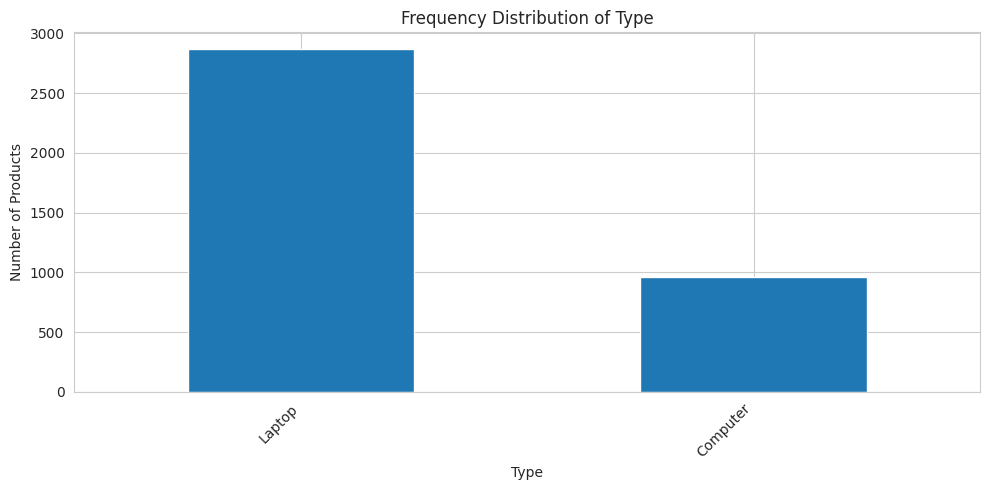

In [164]:
type_counts = df['Type'].value_counts()

plt.figure(figsize=(10, 5))
type_counts.plot(kind='bar')

plt.title("Frequency Distribution of Type")
plt.xlabel("Type")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [165]:
contingency_table = pd.crosstab(df['Brand'], df['Type'])

display(contingency_table)

Type,Computer,Laptop
Brand,,
acer,40,137
asus,45,298
dell,146,656
hp,110,713
huawei,0,1
lenovo,89,389
macbook,48,467
microsoft,0,4
msi,9,0


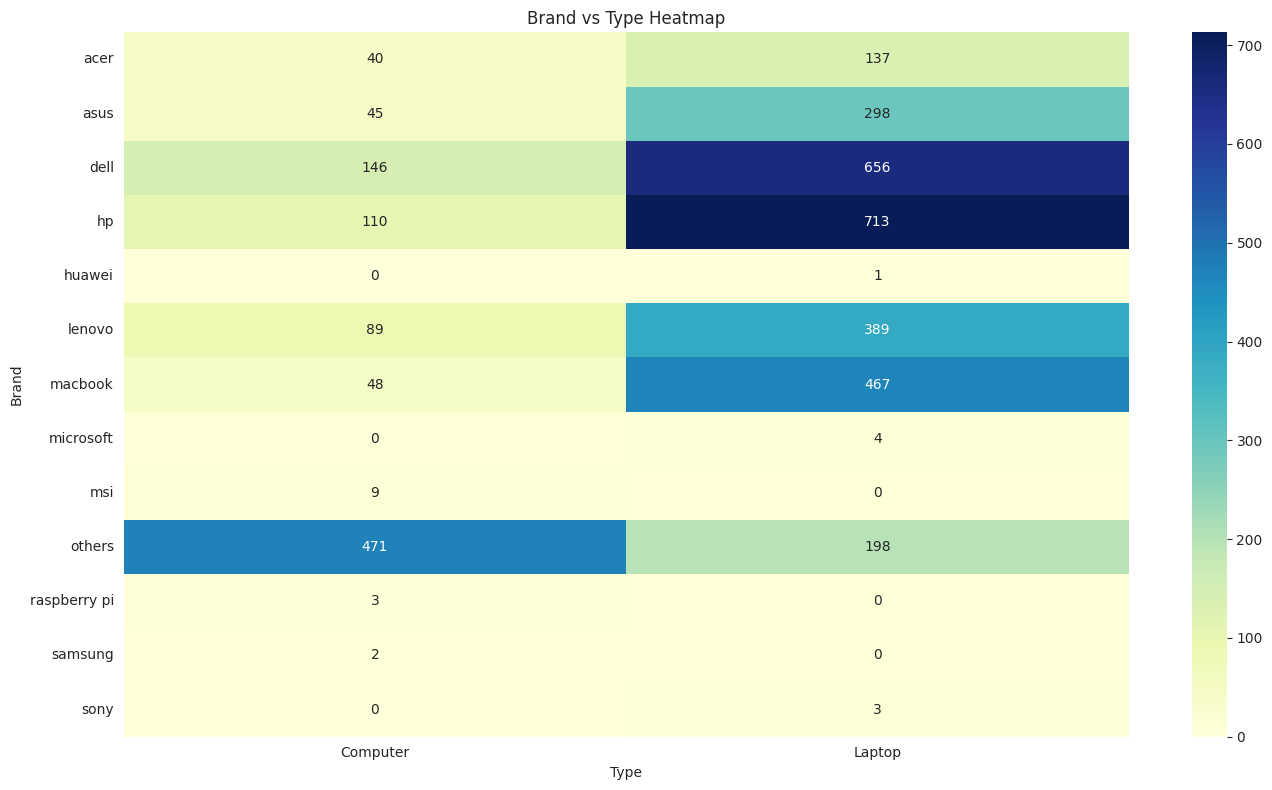

In [166]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    contingency_table,
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title("Brand vs Type Heatmap")
plt.xlabel("Type")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

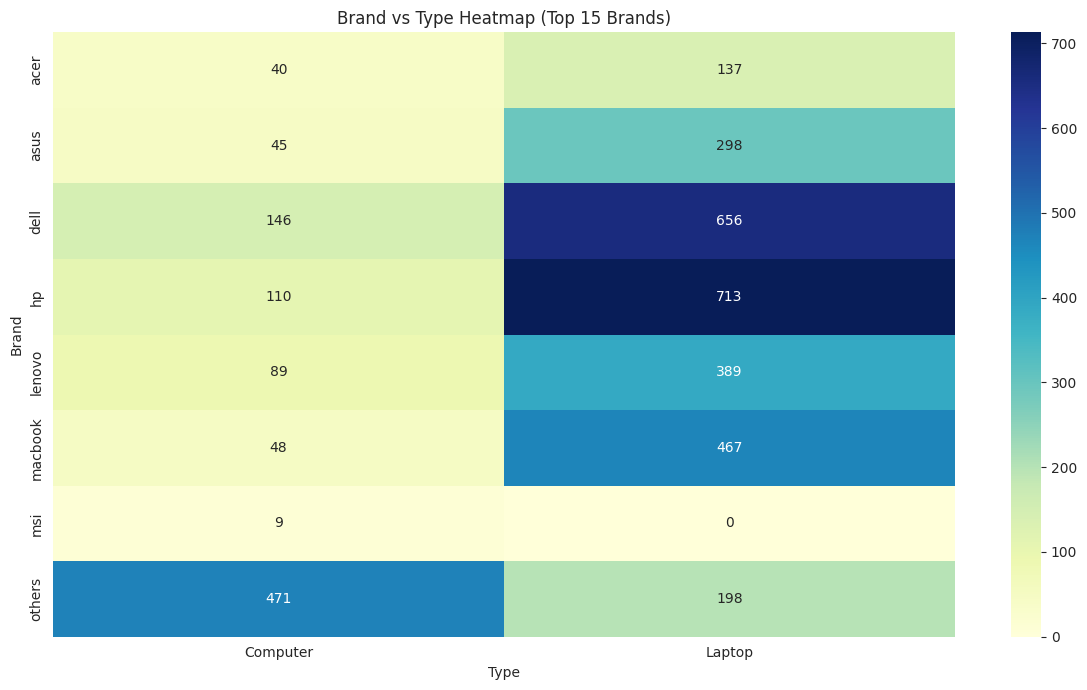

In [167]:
top_brands = df['Brand'].value_counts().head(8).index

top_contingency = pd.crosstab(
    df.loc[df['Brand'].isin(top_brands), 'Brand'],
    df.loc[df['Brand'].isin(top_brands), 'Type']
)

plt.figure(figsize=(12, 7))

sns.heatmap(
    top_contingency,
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title("Brand vs Type Heatmap (Top 15 Brands)")
plt.xlabel("Type")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

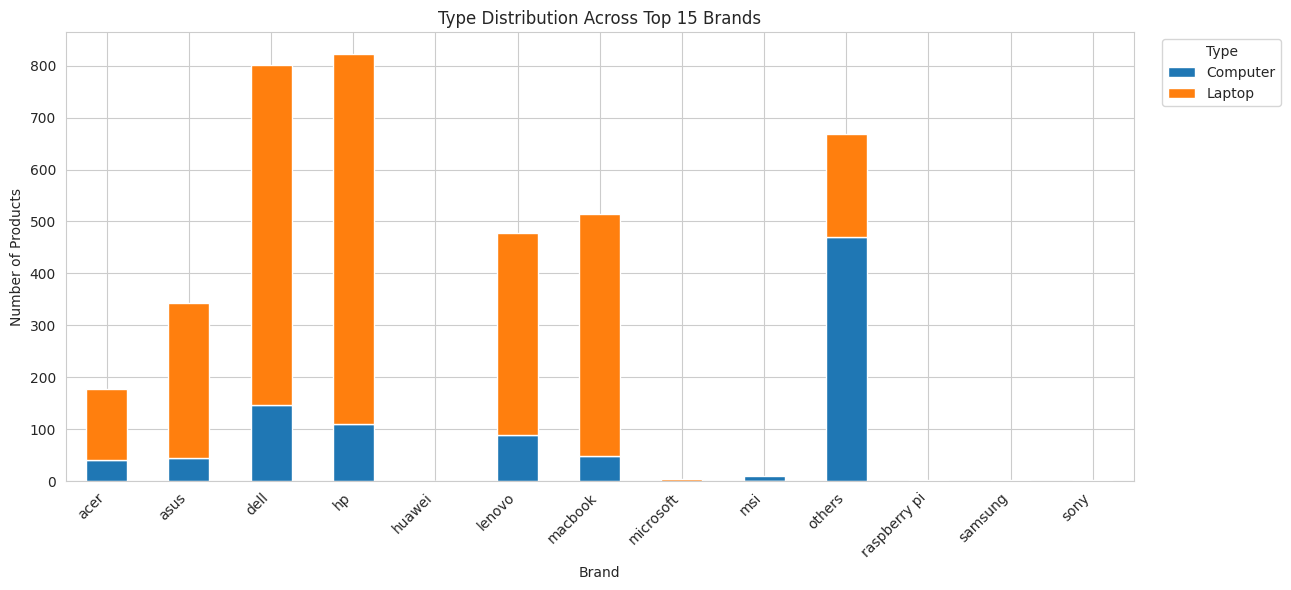

In [168]:
top_brands = df['Brand'].value_counts().head(15).index

brand_type_counts = pd.crosstab(
    df.loc[df['Brand'].isin(top_brands), 'Brand'],
    df.loc[df['Brand'].isin(top_brands), 'Type']
)

brand_type_counts.plot(
    kind='bar',
    stacked=True,
    figsize=(13, 6)
)

plt.title("Type Distribution Across Top 15 Brands")
plt.xlabel("Brand")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.legend(title="Type", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [169]:
from scipy.stats import chi2_contingency
contingency_table = pd.crosstab(df['Brand'], df['Type'])

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

if p_value < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
    print("There is a statistically significant association between Brand and Type.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of an association between Brand and Type.")

Chi-Square Statistic: 959.7621688763671
P-value: 8.342940437578777e-198
Degrees of Freedom: 12

Conclusion: Reject the null hypothesis.
There is a statistically significant association between Brand and Type.


In [170]:
n = contingency_table.to_numpy().sum()
rows, cols = contingency_table.shape

if n > 0 and min(rows - 1, cols - 1) > 0:
    cramers_v = np.sqrt(
        chi2 / (n * min(rows - 1, cols - 1))
    )

    print("Cramér's V:", round(cramers_v, 4))

    if cramers_v < 0.1:
        print("Interpretation: Very weak association.")
    elif cramers_v < 0.3:
        print("Interpretation: Weak association.")
    elif cramers_v < 0.5:
        print("Interpretation: Moderate association.")
    elif cramers_v < 0.7:
        print("Interpretation: Strong association.")
    else:
        print("Interpretation: Very strong association.")
else:
    print("Cramér's V cannot be calculated for this table.")

Cramér's V: 0.5007
Interpretation: Strong association.


In [171]:
df.groupby(['Brand', 'Type']).size().reset_index(name='Count').sort_values('Count', ascending=False)

,Brand,Type,Count
7,hp,Laptop,713
5,dell,Laptop,656
15,others,Computer,471
12,macbook,Laptop,467
10,lenovo,Laptop,389
3,asus,Laptop,298
16,others,Laptop,198
4,dell,Computer,146
1,acer,Laptop,137
6,hp,Computer,110


In [172]:
data.sample(2)

,Price,Brand,Type,Has_Warranty,RAM_GB,RAM_missing,ROM_GB,ROM_Missing,Screen_Size,Screen_Size_missing,Processor_Tier,Processor_Tier_missing,Storage_Type,processor,Warranty_Days_filled,Warranty_Days_was_missing
1952,9999.0,lenovo,Laptop,0,8,0,365.0,1,14.0,0,3.0,0,Unspecified,Intel Core i5,0,0
1064,43000.0,others,Computer,0,16,0,256.0,0,19.0,1,3.0,0,NVMe,Intel Core i5,0,0


# Bivariate Exploratory Data Analysis (EDA) — `Brand` vs. `RAM_GB`

## 1. Summary Statistics and Data Integrity

- **Purpose:** This section investigates how RAM configurations are distributed across brands.
- **Data Overview:** The code compares brand and RAM frequencies, creates a brand-by-RAM contingency table, and displays counts and within-brand percentages.
- **RAM Categories:** The dataset includes common capacities such as 4, 8, 16, and 32 GB, as well as less common values such as 18, 23, 36, 48, 96, and 128 GB. Uncommon values should be checked against the dataset's feature definitions and source data.

## 2. Visualization Analysis

- **Frequency Charts:** Show the distribution of brands and RAM capacities.
- **Contingency Heatmap:** Displays counts for each brand/RAM combination, helping identify common and uncommon configurations.
- **Stacked Bar Charts:** Compare the number of products at each RAM capacity across brands.
- **Within-Brand Percentage Charts:** Normalize the RAM distribution for each brand, making brand profiles easier to compare despite different brand sample sizes.

## 3. Statistical Analysis — Chi-Square Test and Cramér's V

- **Chi-square statistic:** Approximately `987.78`.
- **p-value:** Approximately `7.78 × 10⁻¹²⁶`, indicating a statistically significant association in the observed table.
- **Cramér's V:** Approximately `0.1466`, classified by the notebook's thresholds as a weak association.

The p-value indicates evidence that brand and RAM configuration are not independent, while Cramér's V suggests that the overall association strength is weak. Rare combinations and small expected counts should be considered when interpreting the chi-square test.

## 4. Key Takeaways and Data Modeling Guidance

- RAM configurations vary across brands, but the overall association is weak according to Cramér's V.
- Use RAM capacity and brand as separate candidate features, then validate their combined predictive value.
- Check unusual RAM values and avoid grouping categories without a domain-based reason.
- For modeling, encode brand categorically and decide how to represent RAM based on the model and feature meaning.

## 5. Conclusion

The analysis finds a statistically significant but weak association between `Brand` and `RAM_GB`. The frequency tables and percentage plots reveal brand-level configuration patterns, while Cramér's V summarizes the overall strength of association.

In [173]:
data[['Brand', 'RAM_GB']].head()

,Brand,RAM_GB
0,macbook,16
1,dell,8
2,others,4
3,lenovo,8
4,hp,8


In [174]:
df = data[['Brand', 'RAM_GB']].copy()

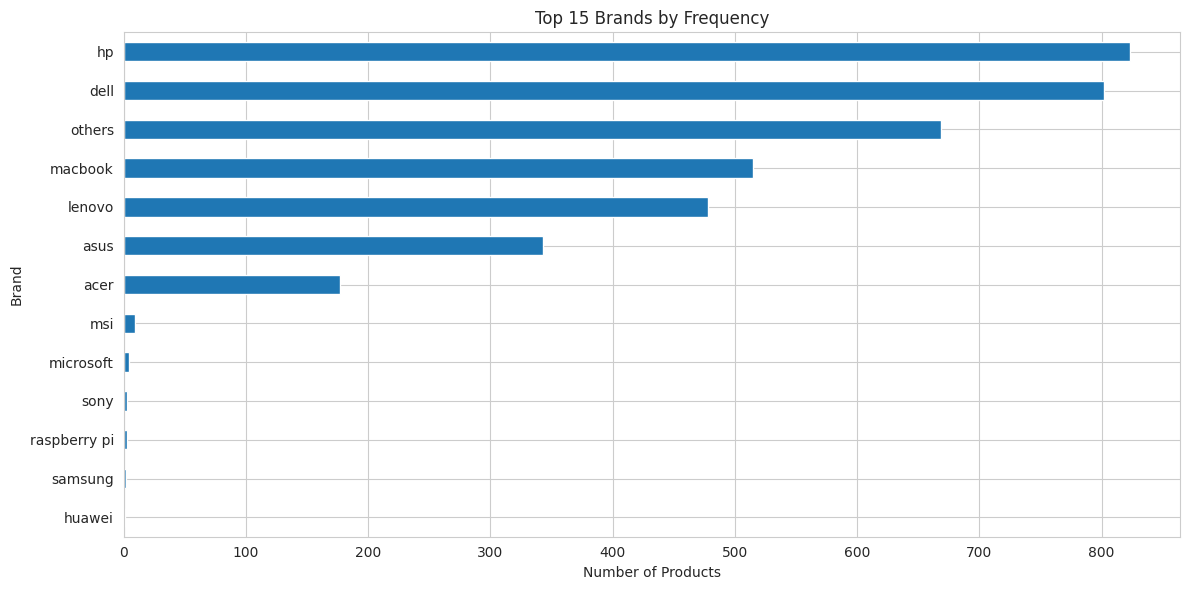

In [175]:
brand_counts = df['Brand'].value_counts()

plt.figure(figsize=(12, 6))
brand_counts.head(15).sort_values().plot(kind='barh')

plt.title("Top 15 Brands by Frequency")
plt.xlabel("Number of Products")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

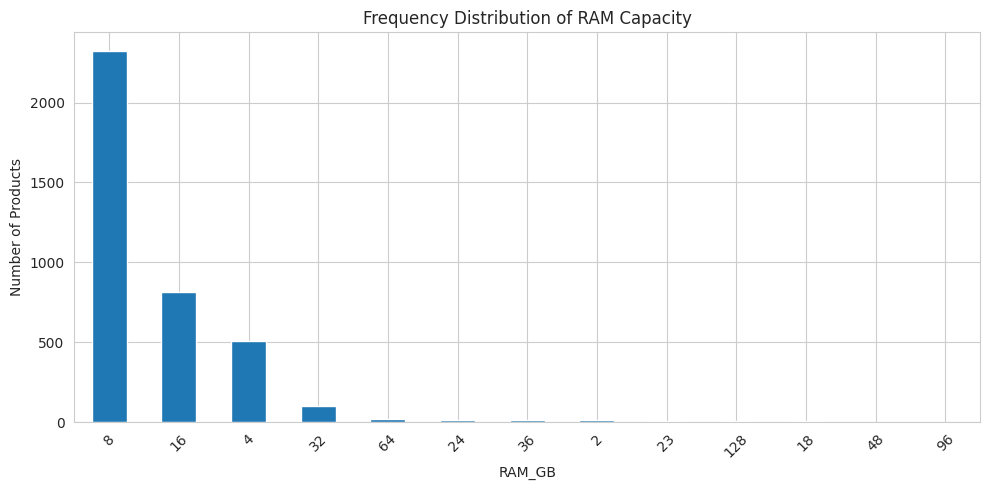

In [176]:
ram_counts = df['RAM_GB'].value_counts()

plt.figure(figsize=(10, 5))
ram_counts.plot(kind='bar')

plt.title("Frequency Distribution of RAM Capacity")
plt.xlabel("RAM_GB")
plt.ylabel("Number of Products")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [177]:
contingency_table = pd.crosstab(
    df['Brand'],
    df['RAM_GB']
)

print("Brand vs RAM_GB contingency table:")
display(contingency_table)

Brand vs RAM_GB contingency table:


RAM_GB,2,4,8,16,18,23,24,32,36,48,64,96,128
Brand,,,,,,,,,,,,,
acer,4,50,96,24,0,0,0,3,0,0,0,0,0
asus,0,40,188,103,0,0,3,9,0,0,0,0,0
dell,0,81,553,142,0,0,0,16,0,0,3,0,7
hp,1,112,594,100,0,0,3,12,0,0,1,0,0
huawei,0,0,1,0,0,0,0,0,0,0,0,0,0
lenovo,0,93,315,56,0,0,5,9,0,0,0,0,0
macbook,0,14,162,265,6,7,2,31,12,2,13,1,0
microsoft,0,0,3,1,0,0,0,0,0,0,0,0,0
msi,0,0,1,8,0,0,0,0,0,0,0,0,0


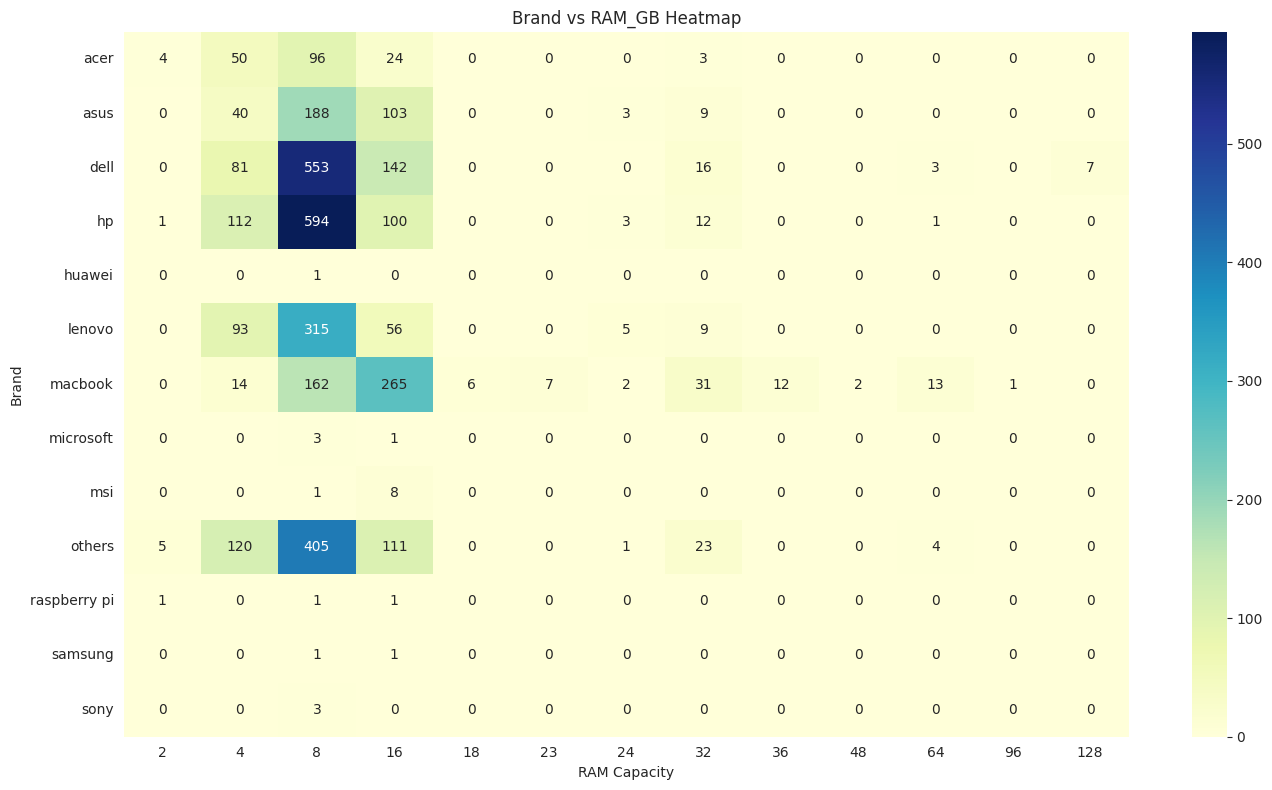

In [178]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    contingency_table,
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title("Brand vs RAM_GB Heatmap")
plt.xlabel("RAM Capacity")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

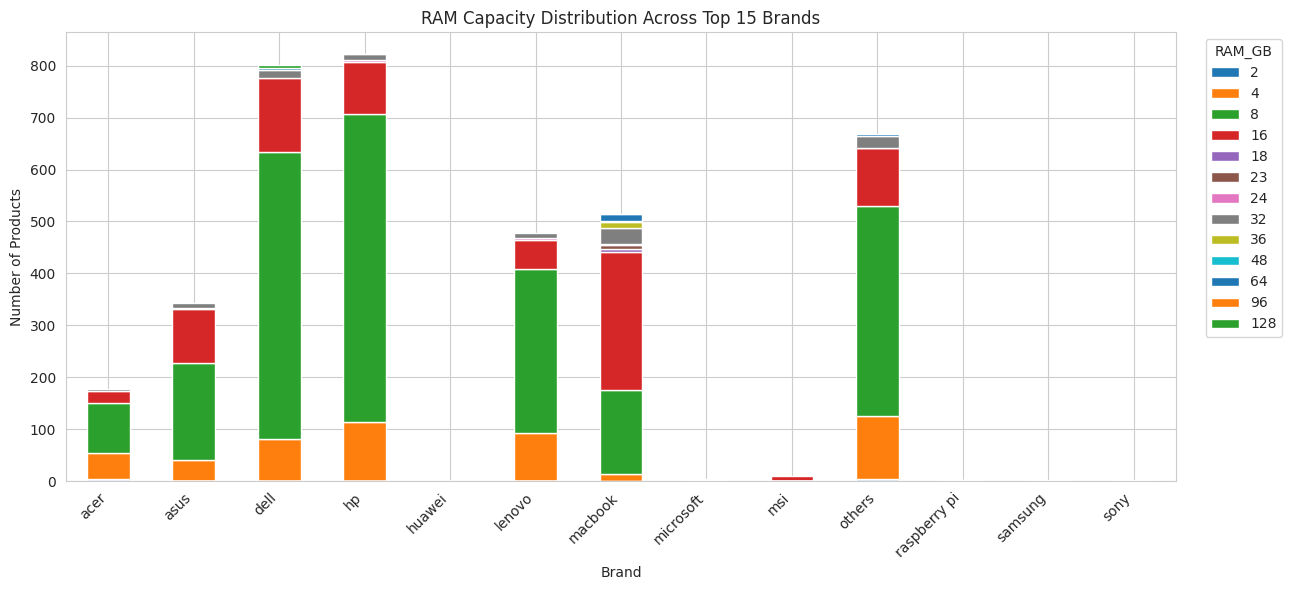

In [179]:
top_brands = df['Brand'].value_counts().index

brand_ram_counts = pd.crosstab(
    df.loc[df['Brand'].isin(top_brands), 'Brand'],
    df.loc[df['Brand'].isin(top_brands), 'RAM_GB']
)

brand_ram_counts.plot(
    kind='bar',
    stacked=True,
    figsize=(13, 6)
)

plt.title("RAM Capacity Distribution Across Top 15 Brands")
plt.xlabel("Brand")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.legend(
    title="RAM_GB",
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.tight_layout()
plt.show()

In [180]:
brand_ram_percentage = pd.crosstab(
    df['Brand'],
    df['RAM_GB'],
    normalize='index'
) * 100

brand_ram_percentage.round(2)

RAM_GB,2,4,8,16,18,23,24,32,36,48,64,96,128
Brand,,,,,,,,,,,,,
acer,2.26,28.25,54.24,13.56,0.00,0.00,0.00,1.69,0.00,0.00,0.00,0.00,0.00
asus,0.00,11.66,54.81,30.03,0.00,0.00,0.87,2.62,0.00,0.00,0.00,0.00,0.00
dell,0.00,10.10,68.95,17.71,0.00,0.00,0.00,2.00,0.00,0.00,0.37,0.00,0.87
hp,0.12,13.61,72.17,12.15,0.00,0.00,0.36,1.46,0.00,0.00,0.12,0.00,0.00
huawei,0.00,0.00,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
lenovo,0.00,19.46,65.90,11.72,0.00,0.00,1.05,1.88,0.00,0.00,0.00,0.00,0.00
macbook,0.00,2.72,31.46,51.46,1.17,1.36,0.39,6.02,2.33,0.39,2.52,0.19,0.00
microsoft,0.00,0.00,75.00,25.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
msi,0.00,0.00,11.11,88.89,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [181]:
contingency_table = pd.crosstab(
    df['Brand'],
    df['RAM_GB']
)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

if p_value < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
    print("There is statistically significant evidence of an association between Brand and RAM_GB.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of an association between Brand and RAM_GB.")

Chi-Square Statistic: 987.7847087737155
P-value: 7.775655433201115e-126
Degrees of Freedom: 144

Conclusion: Reject the null hypothesis.
There is statistically significant evidence of an association between Brand and RAM_GB.


In [182]:
n = contingency_table.to_numpy().sum()
rows, cols = contingency_table.shape

if n > 0 and min(rows - 1, cols - 1) > 0:
    cramers_v = np.sqrt(
        chi2 / (n * min(rows - 1, cols - 1))
    )

    print("Cramér's V:", round(cramers_v, 4))

    if cramers_v < 0.1:
        print("Interpretation: Very weak association.")
    elif cramers_v < 0.3:
        print("Interpretation: Weak association.")
    elif cramers_v < 0.5:
        print("Interpretation: Moderate association.")
    elif cramers_v < 0.7:
        print("Interpretation: Strong association.")
    else:
        print("Interpretation: Very strong association.")
else:
    print("Cramér's V cannot be calculated for this table.")

Cramér's V: 0.1466
Interpretation: Weak association.


In [183]:
data.sample(2)

,Price,Brand,Type,Has_Warranty,RAM_GB,RAM_missing,ROM_GB,ROM_Missing,Screen_Size,Screen_Size_missing,Processor_Tier,Processor_Tier_missing,Storage_Type,processor,Warranty_Days_filled,Warranty_Days_was_missing
1715,18600.0,dell,Computer,1,8,0,256.0,0,19.0,0,3.0,0,SSD,Intel Core i5,30,1
2983,16000.0,dell,Laptop,0,8,1,256.0,1,15.6,0,3.0,1,Unspecified,Intel Core i5,0,0


# Bivariate Exploratory Data Analysis (EDA) — `Type` vs. `RAM_GB`

## 1. Summary Statistics and Data Integrity

- **Purpose:** This section compares RAM-capacity distributions between product types, such as laptops and computers.
- **Data Overview:** The code counts each product type and RAM capacity, then creates a contingency table of their combinations.
- **What to Check:** The count tables show which RAM capacities are common within each product type. Some high-capacity RAM values have very small expected counts, which can weaken the reliability of the chi-square approximation.

## 2. Visualization Analysis

- **Frequency Charts:** Show the overall distribution of product type and RAM capacity.
- **Contingency Heatmap:** Displays the number of products in each type/RAM combination.
- **Stacked Count Chart:** Compares the number of RAM configurations across product types.
- **Stacked Percentage Chart:** Uses row-wise percentages to compare RAM distributions within each type, accounting for the different numbers of laptops and computers.

## 3. Statistical Analysis — Chi-Square Test and Cramér's V

- **Chi-square statistic:** Approximately `118.00`.
- **p-value:** Approximately `1.54 × 10⁻¹⁹`, indicating a statistically significant association in this sample.
- **Expected cells below 5:** Approximately `42.31%`.
- **Cramér's V:** Approximately `0.1756`, classified as a weak association by the notebook's thresholds.

Although the chi-square result is statistically significant, about 42.31% of expected cells are below 5. This exceeds the commonly used guideline for comfortable use of the chi-square approximation, so interpret the p-value cautiously and consider combining only defensibly rare RAM categories or using an appropriate alternative test.

## 4. Key Takeaways and Data Modeling Guidance

- RAM distributions differ between product types, but Cramér's V suggests the overall association is weak.
- Compare within-type percentages rather than only raw counts because the two product types have different sample sizes.
- Inspect rare RAM capacities and their source-data validity.
- Evaluate `Type` and `RAM_GB` together in the price model rather than assuming this association guarantees predictive value.

## 5. Conclusion

The analysis suggests a statistically significant but weak association between `Type` and `RAM_GB`. The percentage chart is especially useful for comparing configuration profiles across product types, while the chi-square result should be treated cautiously because many expected cell counts are small.

In [184]:
display(data[['Type', 'RAM_GB']].head())

,Type,RAM_GB
0,Laptop,16
1,Laptop,8
2,Computer,4
3,Laptop,8
4,Laptop,8


In [185]:
print("\nUnique Types:", data['Type'].nunique())
print("Unique RAM values:", data['RAM_GB'].nunique())


Unique Types: 2
Unique RAM values: 13


In [186]:
df = data[['Type', 'RAM_GB']].copy()

Type frequencies:


,Count
Type,
Laptop,2866
Computer,963


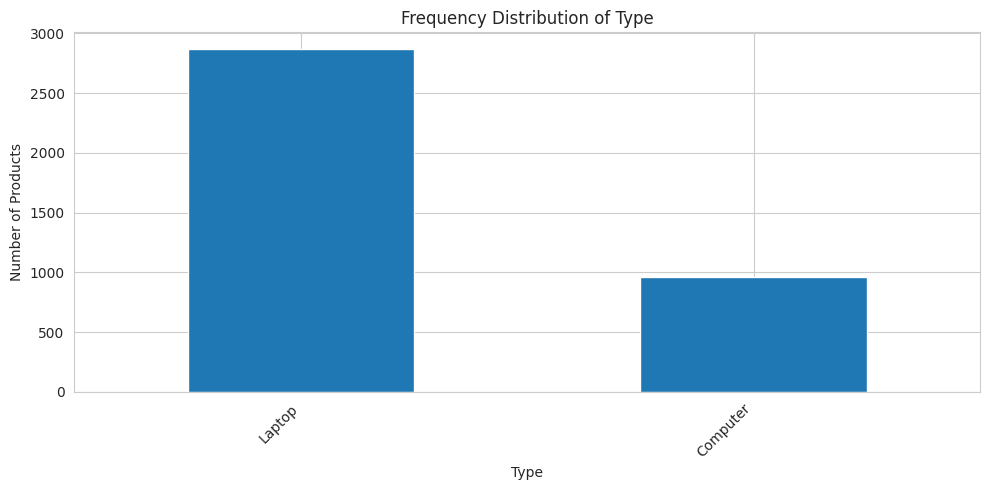

In [187]:
type_counts = df['Type'].value_counts()

print("Type frequencies:")
display(type_counts.to_frame(name='Count'))

plt.figure(figsize=(10, 5))
type_counts.plot(kind='bar')

plt.title("Frequency Distribution of Type")
plt.xlabel("Type")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [188]:
df['RAM_GB'].value_counts()

,count
RAM_GB,
8,2323
16,812
4,510
32,103
64,21
24,14
36,12
2,11
23,7


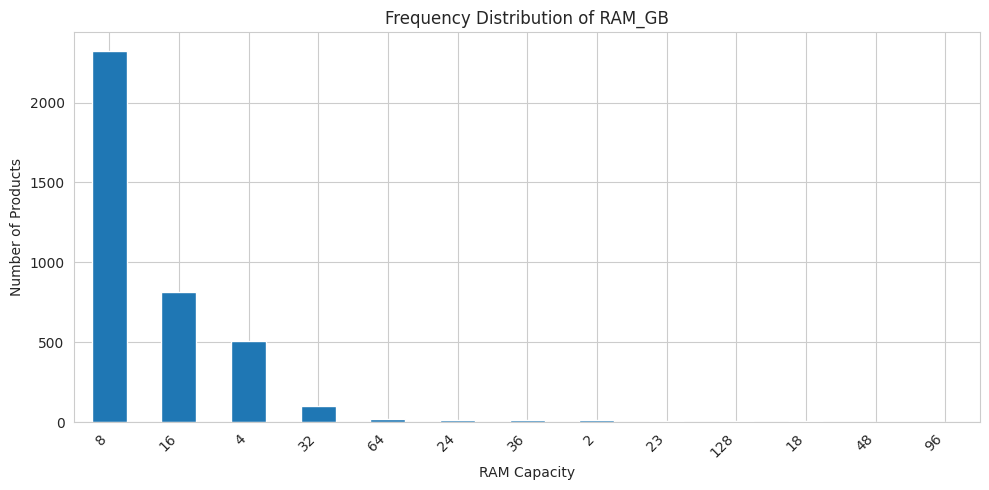

In [189]:
plt.figure(figsize=(10, 5))
ram_counts.plot(kind='bar')

plt.title("Frequency Distribution of RAM_GB")
plt.xlabel("RAM Capacity")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [190]:
contingency_table = pd.crosstab(
    df['Type'],
    df['RAM_GB']
)

print("Type vs RAM_GB contingency table:")
display(contingency_table)

Type vs RAM_GB contingency table:


RAM_GB,2,4,8,16,18,23,24,32,36,48,64,96,128
Type,,,,,,,,,,,,,
Computer,2,152,608,135,6,0,1,33,2,0,16,1,7
Laptop,9,358,1715,677,0,7,13,70,10,2,5,0,0


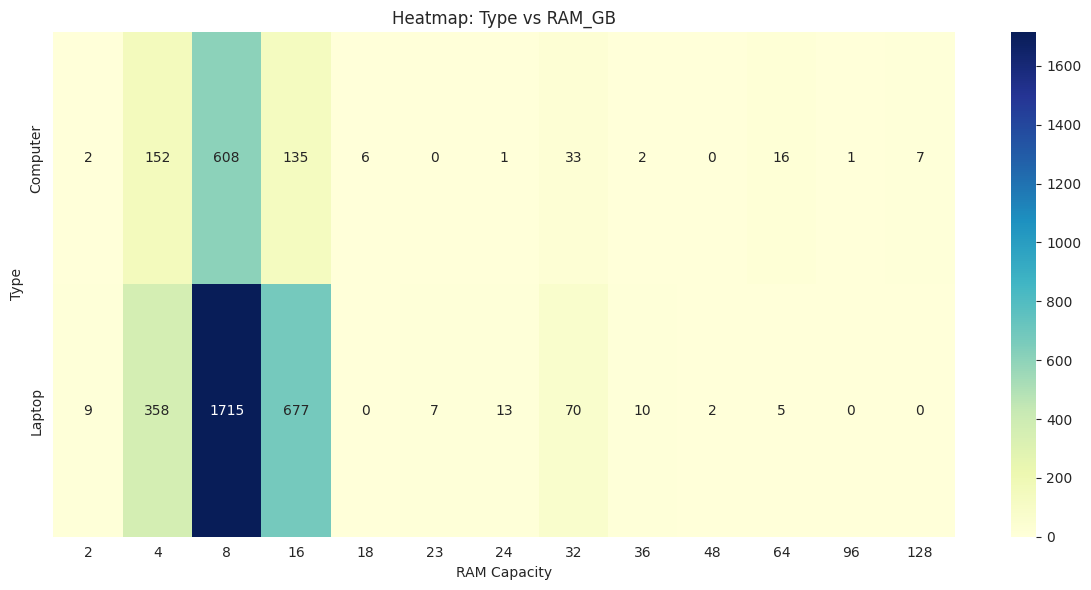

In [191]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    contingency_table,
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title("Heatmap: Type vs RAM_GB")
plt.xlabel("RAM Capacity")
plt.ylabel("Type")
plt.tight_layout()
plt.show()

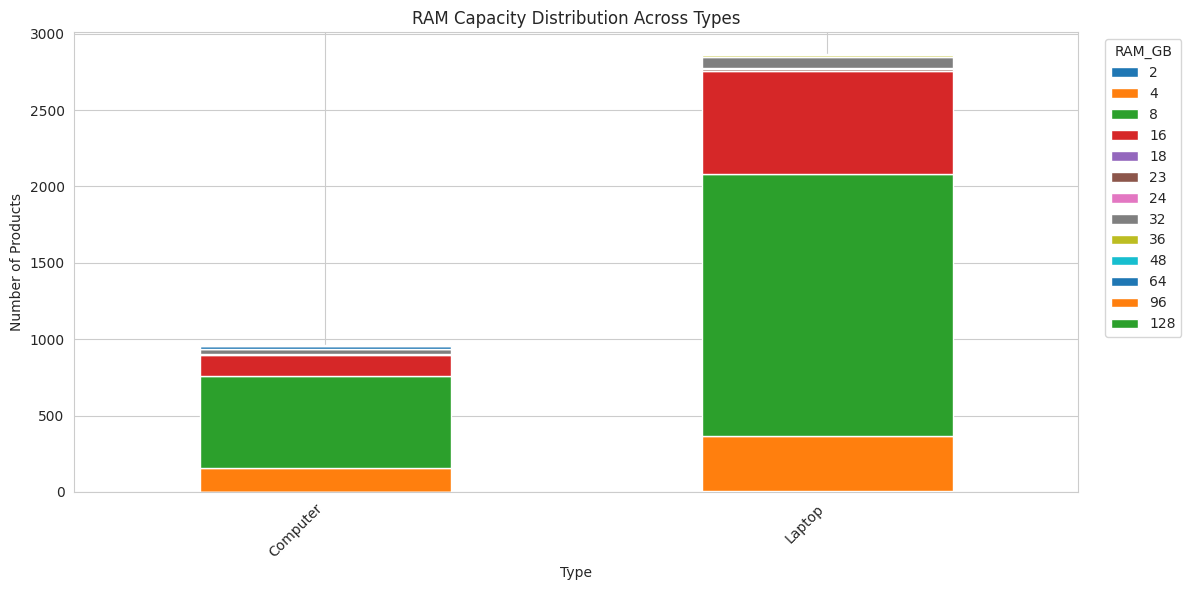

In [192]:
contingency_table.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title("RAM Capacity Distribution Across Types")
plt.xlabel("Type")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.legend(
    title="RAM_GB",
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.tight_layout()
plt.show()

RAM percentage distribution within each Type:


RAM_GB,2,4,8,16,18,23,24,32,36,48,64,96,128
Type,,,,,,,,,,,,,
Computer,0.21,15.78,63.14,14.02,0.62,0.00,0.10,3.43,0.21,0.00,1.66,0.1,0.73
Laptop,0.31,12.49,59.84,23.62,0.00,0.24,0.45,2.44,0.35,0.07,0.17,0.0,0.00


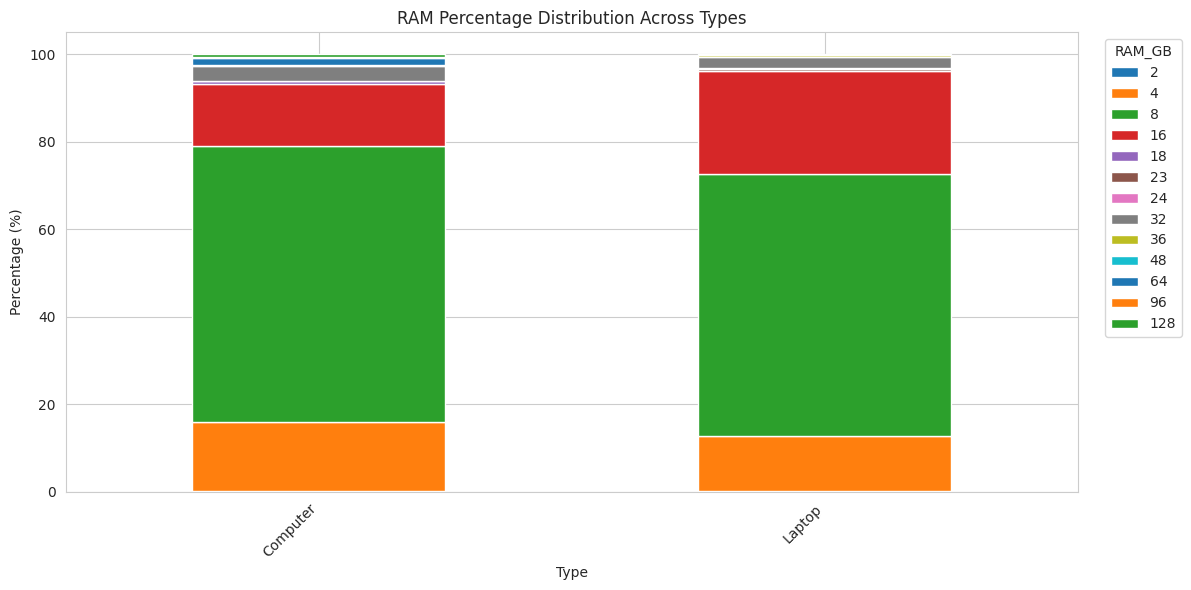

In [193]:
type_ram_percentage = pd.crosstab(
    df['Type'],
    df['RAM_GB'],
    normalize='index'
) * 100

print("RAM percentage distribution within each Type:")
display(type_ram_percentage.round(2))

type_ram_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title("RAM Percentage Distribution Across Types")
plt.xlabel("Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha='right')
plt.legend(
    title="RAM_GB",
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.tight_layout()
plt.show()

In [194]:
contingency_table = pd.crosstab(
    df['Type'],
    df['RAM_GB']
)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("\nExpected frequencies:")
display(expected_df.round(2))

print(
    "\nPercentage of expected cells below 5:",
    round((expected < 5).mean() * 100, 2), "%"
)

if p_value < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
    print("There is statistically significant evidence of an association between Type and RAM_GB.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of an association between Type and RAM_GB.")

Chi-Square Statistic: 118.0048868117223
P-value: 1.5433842686863007e-19
Degrees of Freedom: 12

Expected frequencies:


RAM_GB,2,4,8,16,18,23,24,32,36,48,64,96,128
Type,,,,,,,,,,,,,
Computer,2.77,128.27,584.24,204.22,1.51,1.76,3.52,25.9,3.02,0.5,5.28,0.25,1.76
Laptop,8.23,381.73,1738.76,607.78,4.49,5.24,10.48,77.1,8.98,1.5,15.72,0.75,5.24



Percentage of expected cells below 5: 42.31 %

Conclusion: Reject the null hypothesis.
There is statistically significant evidence of an association between Type and RAM_GB.


In [195]:
n = contingency_table.to_numpy().sum()
rows, cols = contingency_table.shape

if n > 0 and min(rows - 1, cols - 1) > 0:
    cramers_v = np.sqrt(
        chi2 / (n * min(rows - 1, cols - 1))
    )

    print("Cramér's V:", round(cramers_v, 4))

    if cramers_v < 0.1:
        print("Interpretation: Very weak association.")
    elif cramers_v < 0.3:
        print("Interpretation: Weak association.")
    elif cramers_v < 0.5:
        print("Interpretation: Moderate association.")
    elif cramers_v < 0.7:
        print("Interpretation: Strong association.")
    else:
        print("Interpretation: Very strong association.")
else:
    print("Cramér's V cannot be calculated for this table.")

Cramér's V: 0.1756
Interpretation: Weak association.


In [196]:
type_ram_combinations = (
    df.groupby(['Type', 'RAM_GB'])
      .size()
      .reset_index(name='Count')
      .sort_values('Count', ascending=False)
)

display(type_ram_combinations.head(20))

,Type,RAM_GB,Count
13,Laptop,8,1715
14,Laptop,16,677
2,Computer,8,608
12,Laptop,4,358
1,Computer,4,152
3,Computer,16,135
17,Laptop,32,70
6,Computer,32,33
8,Computer,64,16
16,Laptop,24,13


In [197]:
data.sample(2)

,Price,Brand,Type,Has_Warranty,RAM_GB,RAM_missing,ROM_GB,ROM_Missing,Screen_Size,Screen_Size_missing,Processor_Tier,Processor_Tier_missing,Storage_Type,processor,Warranty_Days_filled,Warranty_Days_was_missing
539,14999.0,dell,Laptop,0,8,0,256.0,1,14.0,1,3.0,0,Unspecified,Intel Core i5,0,0
228,50000.0,lenovo,Laptop,0,24,0,512.0,0,14.0,1,3.0,1,SSD,Intel Core i5,0,0


# Bivariate Exploratory Data Analysis (EDA) — `Type` vs. `ROM_GB`

## 1. Summary Statistics and Data Integrity

- **Purpose:** This section investigates whether storage capacities (`ROM_GB`) are distributed differently between laptops and computers.
- **Data Overview:** The code counts product types and ROM capacities, builds a contingency table, and compares observed combinations.
- **What to Check:** Common storage capacities can be compared across types, while uncommon capacities may produce small expected cell counts that affect the chi-square test.

## 2. Visualization Analysis

- **Frequency Charts:** Show how often each product type and storage capacity occurs.
- **Contingency Heatmap:** Displays counts for each type/ROM combination.
- **Stacked Count Chart:** Compares absolute counts of storage capacities across product types.
- **Stacked Percentage Chart:** Shows the ROM-capacity distribution within each product type, making it easier to compare groups of different sizes.

## 3. Statistical Analysis — Chi-Square Test and Cramér's V

- **Chi-square statistic:** Approximately `757.23`.
- **p-value:** Approximately `1.05 × 10⁻¹⁴⁶`, indicating a statistically significant association in the observed data.
- **Expected cells below 5:** Approximately `40.91%`.
- **Cramér's V:** Approximately `0.4447`, classified as a moderate association by the notebook's thresholds.

The association appears stronger than the Type–RAM association according to Cramér's V. However, about 40.91% of expected cells are below 5, so the chi-square approximation may be unreliable without further handling of sparse categories.

## 4. Key Takeaways and Data Modeling Guidance

- ROM-capacity distributions differ across product types, with a moderate overall association by Cramér's V.
- Use within-type percentages to compare distributions fairly when group sizes differ.
- Review rare ROM capacities and consider combining only categories that are meaningfully similar.
- Use `Type` and `ROM_GB` as candidate model features and validate their incremental contribution.

## 5. Conclusion

The analysis indicates a moderate association between `Type` and `ROM_GB`, although sparse expected counts warrant caution with the chi-square p-value. The count and percentage charts provide complementary views of the capacity profiles for laptops and computers.

In [198]:
display(data[['Type', 'ROM_GB']].head())


,Type,ROM_GB
0,Laptop,256.0
1,Laptop,256.0
2,Computer,500.0
3,Laptop,256.0
4,Laptop,512.0


In [199]:
df = data[['Type', 'ROM_GB']].copy()

In [200]:
type_counts = df['Type'].value_counts()

print("Type frequencies:")
display(type_counts.to_frame(name='Count'))

Type frequencies:


,Count
Type,
Laptop,2866
Computer,963


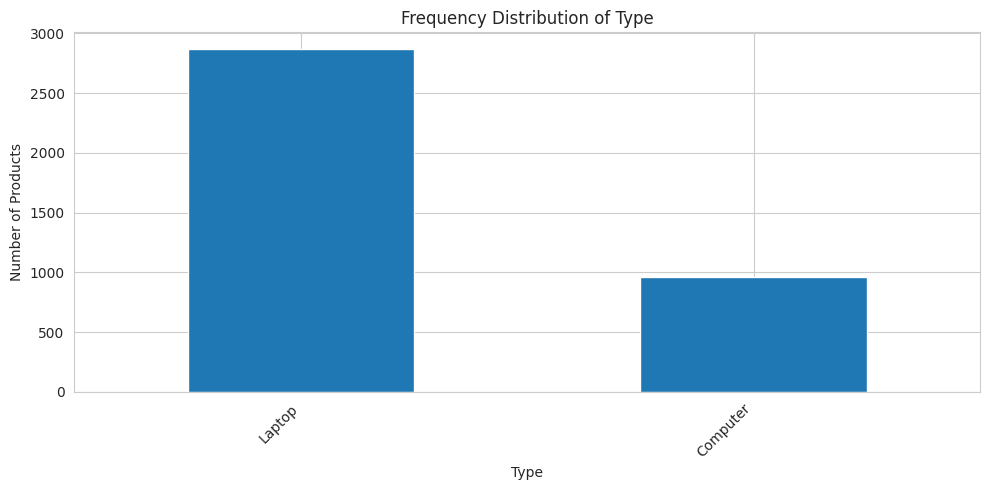

In [201]:
plt.figure(figsize=(10, 5))
type_counts.plot(kind='bar')

plt.title("Frequency Distribution of Type")
plt.xlabel("Type")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [202]:
rom_counts = df['ROM_GB'].value_counts()

print("ROM capacity frequencies:")
display(rom_counts.to_frame(name='Count'))


ROM capacity frequencies:


,Count
ROM_GB,
256.0,1380
512.0,935
500.0,638
1024.0,319
128.0,171
365.0,149
320.0,51
378.0,50
238.0,30


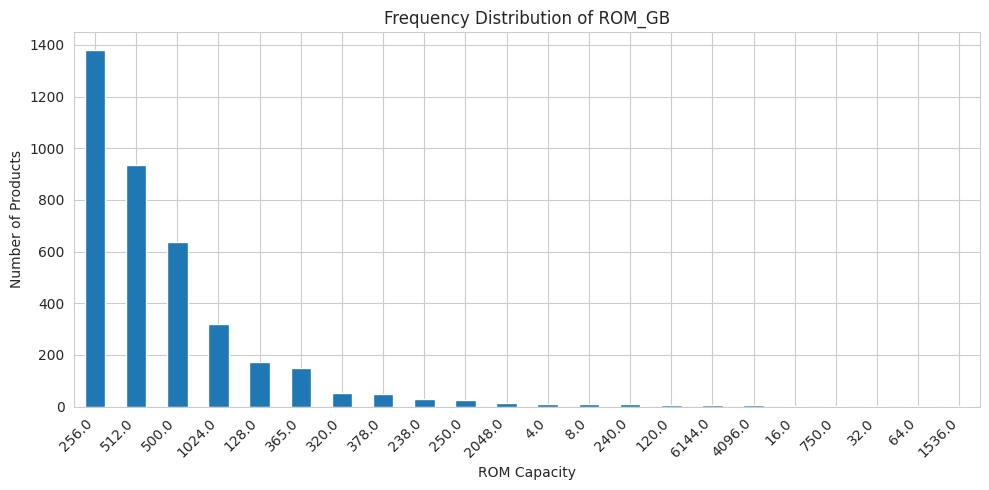

In [203]:
plt.figure(figsize=(10, 5))
rom_counts.plot(kind='bar')

plt.title("Frequency Distribution of ROM_GB")
plt.xlabel("ROM Capacity")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [204]:
contingency_table = pd.crosstab(
    df['Type'],
    df['ROM_GB']
)

print("Type vs ROM_GB contingency table:")
display(contingency_table)

Type vs ROM_GB contingency table:


ROM_GB,4.0,8.0,16.0,32.0,64.0,120.0,128.0,238.0,240.0,250.0,...,365.0,378.0,500.0,512.0,750.0,1024.0,1536.0,2048.0,4096.0,6144.0
Type,,,,,,,,,,,,,,,,,,,,,
Computer,0,3,2,0,1,1,94,0,7,11,...,0,0,72,51,0,83,0,7,3,7
Laptop,12,8,2,3,2,7,77,30,3,14,...,149,50,566,884,4,236,1,6,2,0


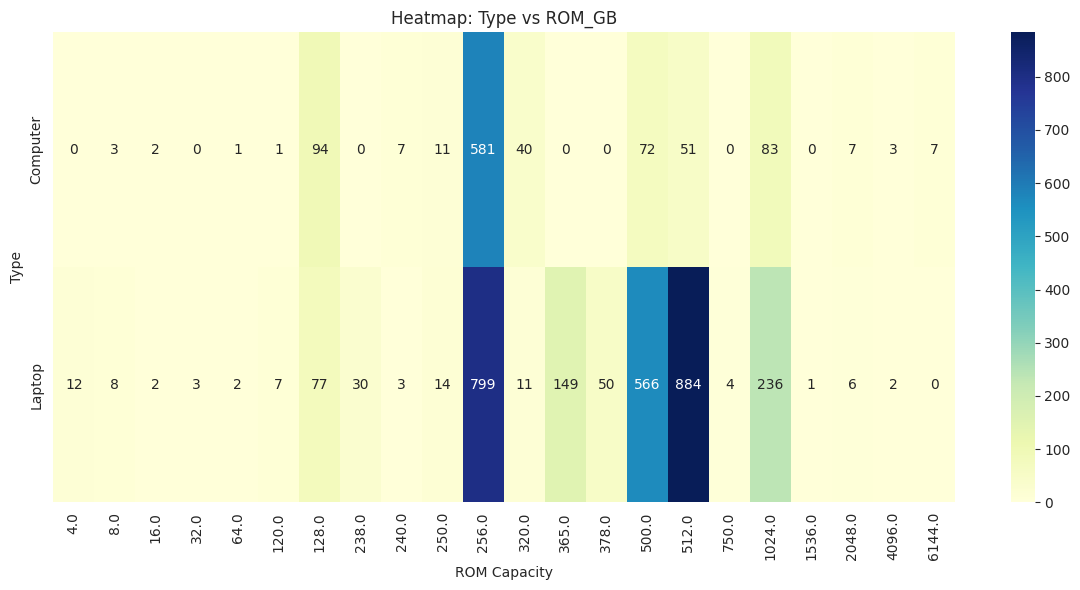

In [205]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    contingency_table,
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title("Heatmap: Type vs ROM_GB")
plt.xlabel("ROM Capacity")
plt.ylabel("Type")
plt.tight_layout()
plt.show()

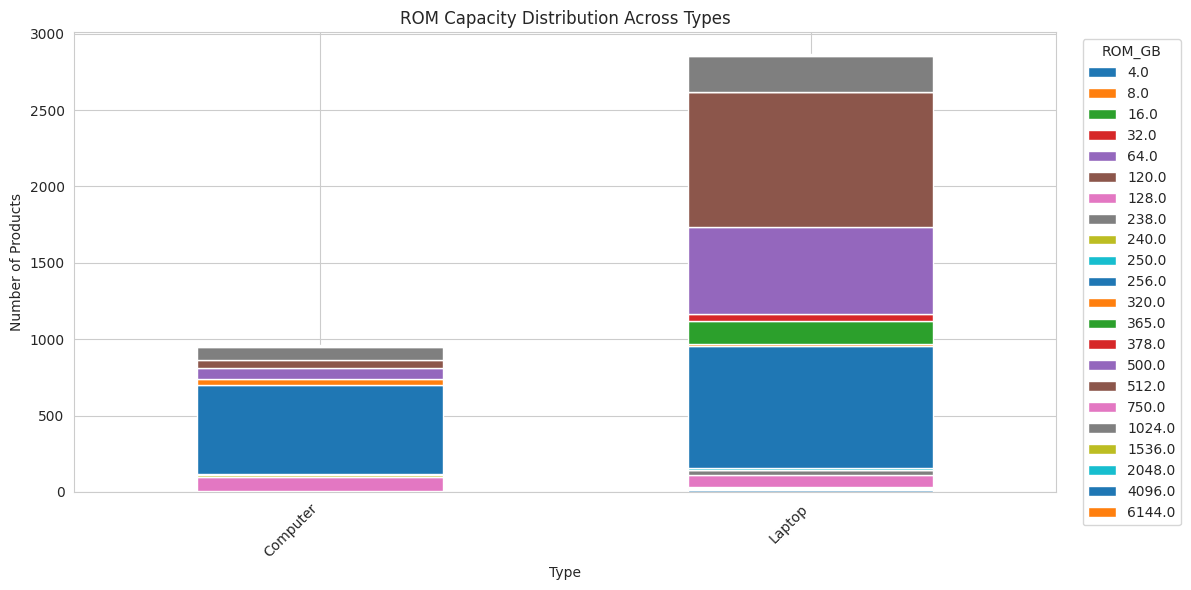

In [206]:
contingency_table.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title("ROM Capacity Distribution Across Types")
plt.xlabel("Type")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.legend(
    title="ROM_GB",
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.tight_layout()
plt.show()

In [207]:
type_rom_percentage = pd.crosstab(
    df['Type'],
    df['ROM_GB'],
    normalize='index'
) * 100

print("ROM percentage distribution within each Type:")
display(type_rom_percentage.round(2))

ROM percentage distribution within each Type:


ROM_GB,4.0,8.0,16.0,32.0,64.0,120.0,128.0,238.0,240.0,250.0,...,365.0,378.0,500.0,512.0,750.0,1024.0,1536.0,2048.0,4096.0,6144.0
Type,,,,,,,,,,,,,,,,,,,,,
Computer,0.00,0.31,0.21,0.0,0.10,0.10,9.76,0.00,0.73,1.14,...,0.0,0.00,7.48,5.30,0.00,8.62,0.00,0.73,0.31,0.73
Laptop,0.42,0.28,0.07,0.1,0.07,0.24,2.69,1.05,0.10,0.49,...,5.2,1.74,19.75,30.84,0.14,8.23,0.03,0.21,0.07,0.00


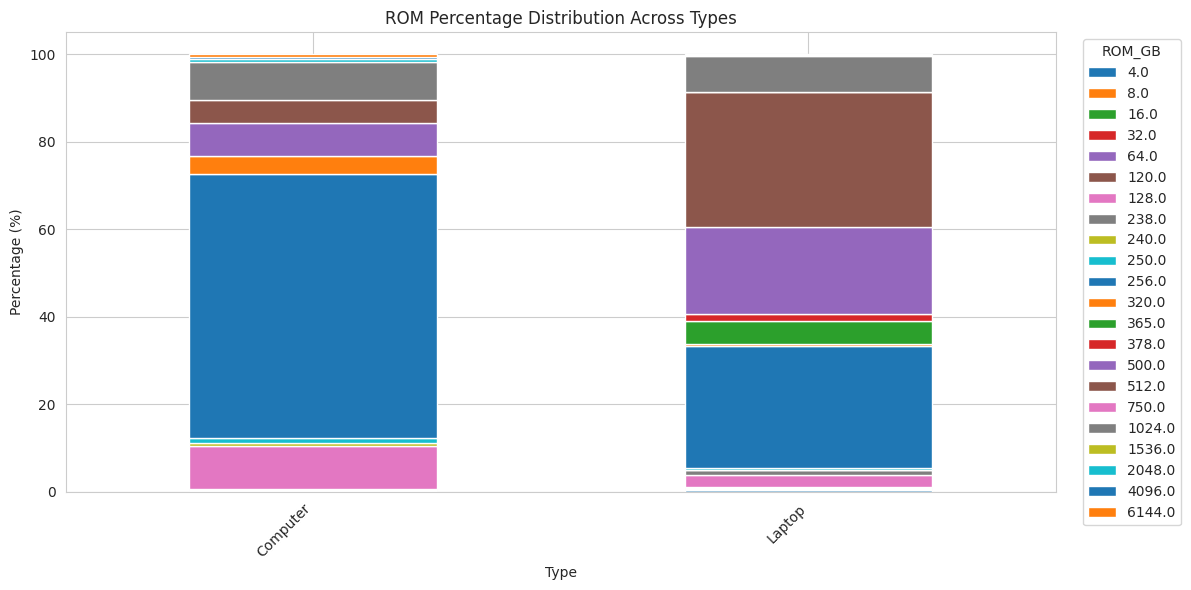

In [208]:
type_rom_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title("ROM Percentage Distribution Across Types")
plt.xlabel("Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha='right')
plt.legend(
    title="ROM_GB",
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.tight_layout()
plt.show()

In [209]:
contingency_table = pd.crosstab(
    df['Type'],
    df['ROM_GB']
)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

print(
    "\nPercentage of expected cells below 5:",
    round((expected < 5).mean() * 100, 2), "%"
)

if p_value < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
    print("There is statistically significant evidence of an association between Type and ROM_GB.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of an association between Type and ROM_GB.")

Chi-Square Statistic: 757.2269923058295
P-value: 1.0465986124000698e-146
Degrees of Freedom: 21

Percentage of expected cells below 5: 40.91 %

Conclusion: Reject the null hypothesis.
There is statistically significant evidence of an association between Type and ROM_GB.


In [210]:
n = contingency_table.to_numpy().sum()
rows, cols = contingency_table.shape

if n > 0 and min(rows - 1, cols - 1) > 0:
    cramers_v = np.sqrt(
        chi2 / (n * min(rows - 1, cols - 1))
    )

    print("Cramér's V:", round(cramers_v, 4))

    if cramers_v < 0.1:
        print("Interpretation: Very weak association.")
    elif cramers_v < 0.3:
        print("Interpretation: Weak association.")
    elif cramers_v < 0.5:
        print("Interpretation: Moderate association.")
    elif cramers_v < 0.7:
        print("Interpretation: Strong association.")
    else:
        print("Interpretation: Very strong association.")
else:
    print("Cramér's V cannot be calculated for this table.")

Cramér's V: 0.4447
Interpretation: Moderate association.


In [211]:
data.sample(2)

,Price,Brand,Type,Has_Warranty,RAM_GB,RAM_missing,ROM_GB,ROM_Missing,Screen_Size,Screen_Size_missing,Processor_Tier,Processor_Tier_missing,Storage_Type,processor,Warranty_Days_filled,Warranty_Days_was_missing
2407,90000.0,asus,Laptop,0,16,0,512.0,0,15.6,0,4.0,0,SSD,AMD Ryzen 7,0,0
2868,38000.0,hp,Laptop,0,8,0,512.0,0,15.6,0,3.0,0,SSD,Intel Core i5,0,0


# Bivariate Exploratory Data Analysis (EDA) — `Brand` vs. `Storage_Type`

## 1. Summary Statistics and Data Integrity

- **Purpose:** This section explores how storage technologies are distributed across brands.
- **Data Overview:** The code counts brands and storage categories, creates a brand-by-storage contingency table, and computes storage-type percentages within each brand.
- **Category Note:** `Unspecified` is the largest storage category in the dataset. It represents unreported or unknown storage type, not a physical storage technology. Some storage categories and brand combinations have low counts.

## 2. Visualization Analysis

- **Frequency Charts:** Show the most common brands and the overall distribution of storage types.
- **Contingency Heatmap:** Displays counts for each brand/storage combination.
- **Stacked Count Chart:** Compares storage-type counts across the 15 most frequent brands.
- **Stacked Percentage Chart:** Compares within-brand storage-type proportions, reducing the effect of differences in brand sample sizes.

## 3. Statistical Analysis — Chi-Square Test and Cramér's V

- **Chi-square statistic:** Approximately `269.52`.
- **p-value:** Approximately `1.32 × 10⁻³²`, indicating a statistically significant association in the observed table.
- **Expected cells below 5:** Approximately `56.92%`.
- **Cramér's V:** Approximately `0.1327`, classified as a weak association.

More than half of expected cells are below 5, so the chi-square approximation requires caution. The small p-value should not be interpreted without considering sparse cells and the effect size indicated by Cramér's V.

## 4. Key Takeaways and Data Modeling Guidance

- Storage-type proportions vary by brand, but the overall association is weak according to Cramér's V.
- Compare percentages as well as counts, since brand sample sizes differ.
- Keep `Unspecified` distinct initially, and investigate whether it represents missing information systematically.
- Validate any rare-category grouping and encoding strategy using training data only.

## 5. Conclusion

The analysis suggests a statistically significant but weak association between `Brand` and `Storage_Type`. The charts describe brand-specific storage profiles, but the chi-square result should be interpreted cautiously because many expected counts are small.

In [212]:
data[['Brand', 'Storage_Type']].head()

,Brand,Storage_Type
0,macbook,SSD
1,dell,Unspecified
2,others,SSD
3,lenovo,SSD
4,hp,Unspecified


In [213]:
df = data[['Brand', 'Storage_Type']].copy()

In [214]:
brand_counts = df['Brand'].value_counts()

print("Brand frequencies:")
display(brand_counts.to_frame(name='Count'))

Brand frequencies:


,Count
Brand,
hp,823
dell,802
others,669
macbook,515
lenovo,478
asus,343
acer,177
msi,9
microsoft,4


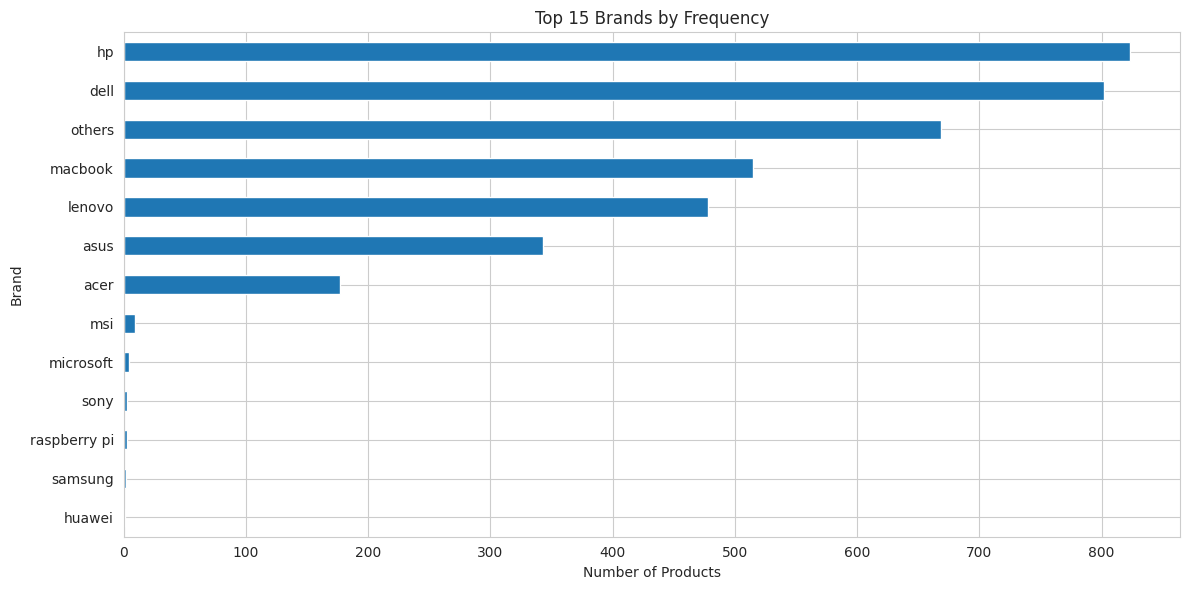

In [215]:
plt.figure(figsize=(12, 6))

brand_counts.head(15).sort_values().plot(kind='barh')

plt.title("Top 15 Brands by Frequency")
plt.xlabel("Number of Products")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

In [216]:
storage_counts = df['Storage_Type'].value_counts()

print("Storage Type frequencies:")
display(storage_counts.to_frame(name='Count'))

Storage Type frequencies:


,Count
Storage_Type,
Unspecified,1909
SSD,1479
HDD,261
NVMe,177
eMMC,3


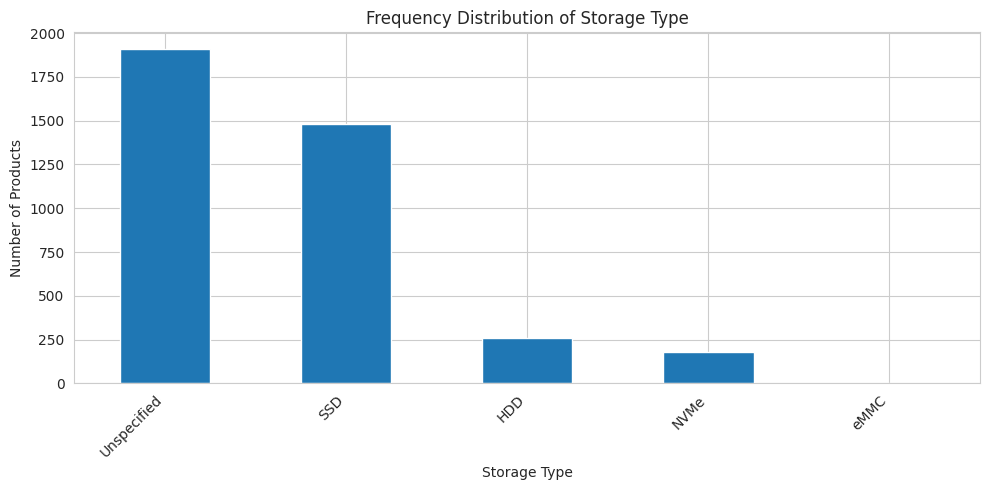

In [217]:
plt.figure(figsize=(10, 5))

storage_counts.plot(kind='bar')

plt.title("Frequency Distribution of Storage Type")
plt.xlabel("Storage Type")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [218]:
contingency_table = pd.crosstab(
    df['Brand'],
    df['Storage_Type']
)

print("Brand vs Storage_Type contingency table:")
display(contingency_table)

Brand vs Storage_Type contingency table:


Storage_Type,HDD,NVMe,SSD,Unspecified,eMMC
Brand,,,,,
acer,10,15,60,92,0
asus,14,37,139,153,0
dell,79,40,359,324,0
hp,63,20,299,440,1
huawei,0,0,1,0,0
lenovo,28,14,157,279,0
macbook,6,0,279,230,0
microsoft,0,0,1,3,0
msi,4,1,2,2,0


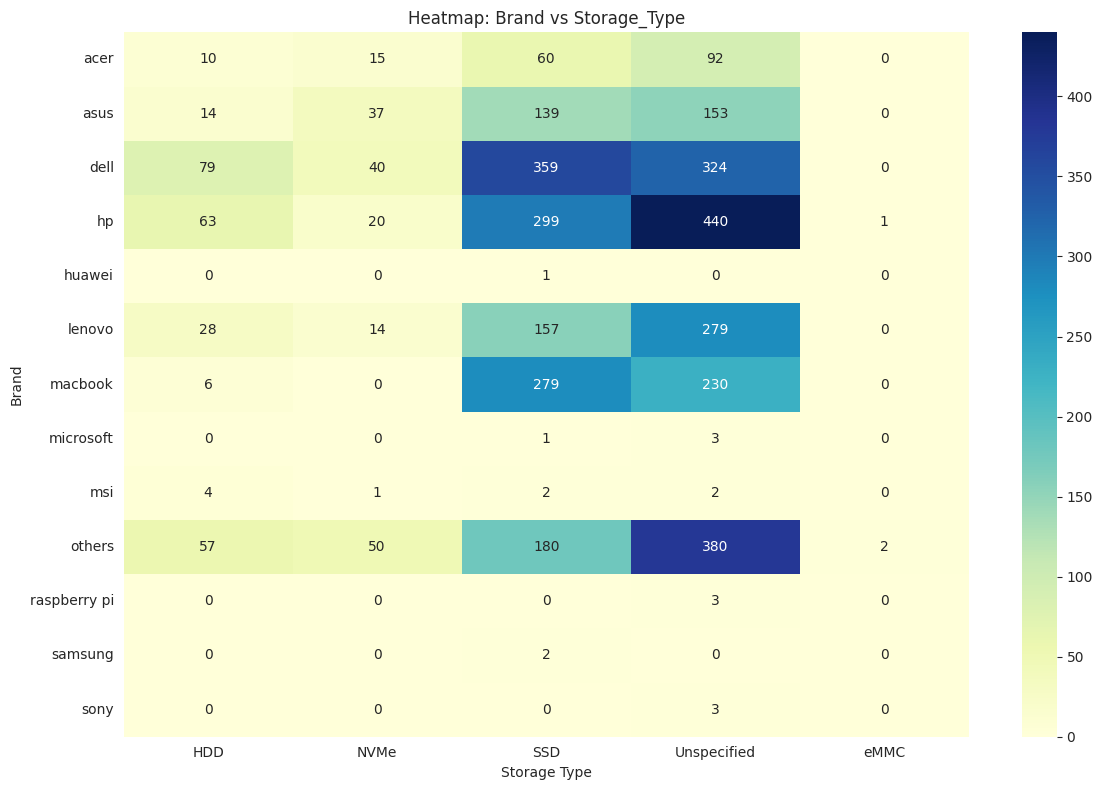

In [219]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    contingency_table,
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title("Heatmap: Brand vs Storage_Type")
plt.xlabel("Storage Type")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

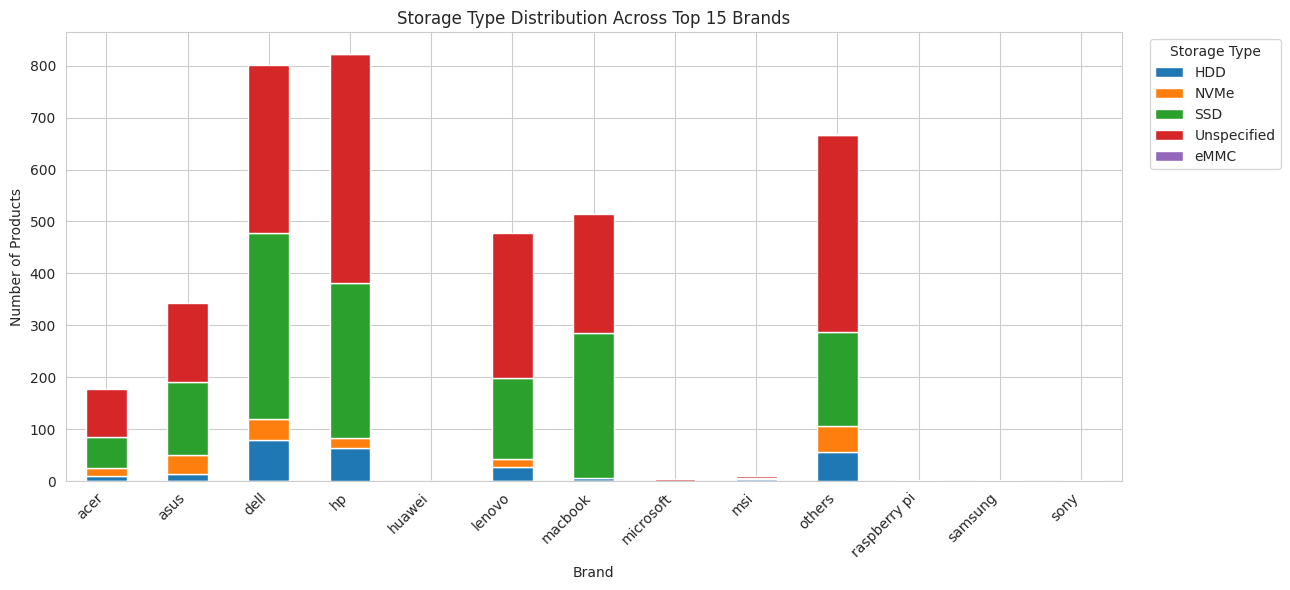

In [220]:
top_brands = df['Brand'].value_counts().head(15).index

brand_storage_counts = pd.crosstab(
    df.loc[df['Brand'].isin(top_brands), 'Brand'],
    df.loc[df['Brand'].isin(top_brands), 'Storage_Type']
)

brand_storage_counts.plot(
    kind='bar',
    stacked=True,
    figsize=(13, 6)
)

plt.title("Storage Type Distribution Across Top 15 Brands")
plt.xlabel("Brand")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.legend(
    title="Storage Type",
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.tight_layout()
plt.show()

In [221]:
brand_storage_percentage = pd.crosstab(
    df['Brand'],
    df['Storage_Type'],
    normalize='index'
) * 100

display(brand_storage_percentage.round(2))

Storage_Type,HDD,NVMe,SSD,Unspecified,eMMC
Brand,,,,,
acer,5.65,8.47,33.90,51.98,0.00
asus,4.08,10.79,40.52,44.61,0.00
dell,9.85,4.99,44.76,40.40,0.00
hp,7.65,2.43,36.33,53.46,0.12
huawei,0.00,0.00,100.00,0.00,0.00
lenovo,5.86,2.93,32.85,58.37,0.00
macbook,1.17,0.00,54.17,44.66,0.00
microsoft,0.00,0.00,25.00,75.00,0.00
msi,44.44,11.11,22.22,22.22,0.00


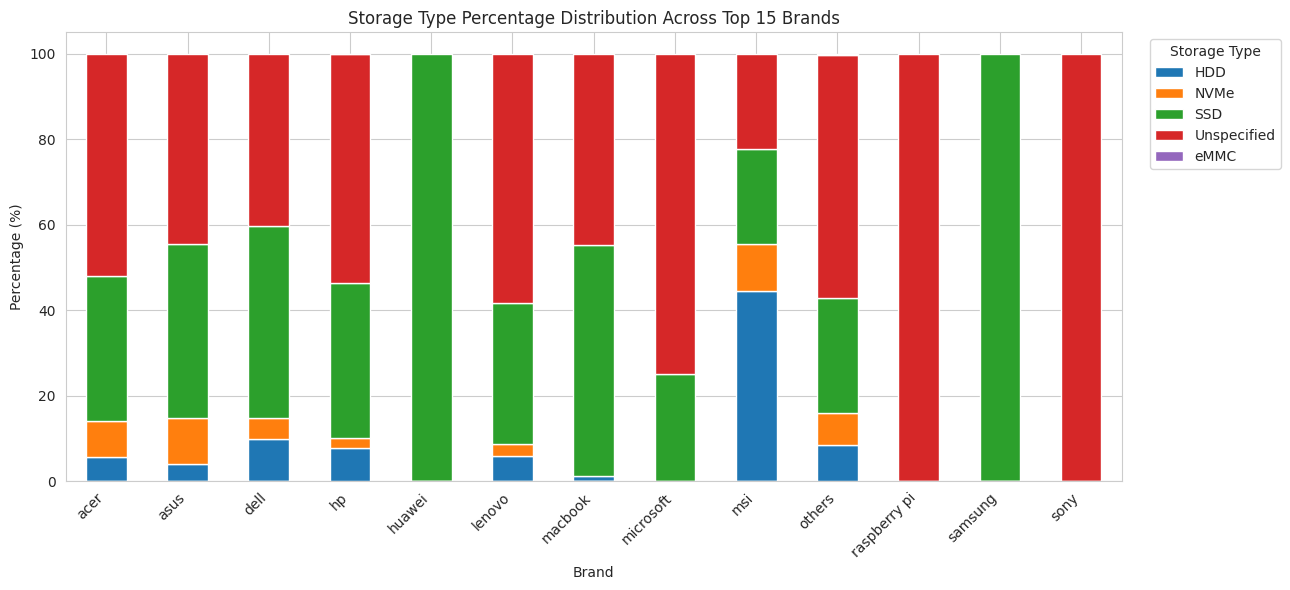

In [222]:
top_brands = df['Brand'].value_counts().head(15).index

top_percentage = brand_storage_percentage.loc[
    brand_storage_percentage.index.isin(top_brands)
]

top_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(13, 6)
)

plt.title("Storage Type Percentage Distribution Across Top 15 Brands")
plt.xlabel("Brand")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha='right')
plt.legend(
    title="Storage Type",
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.tight_layout()
plt.show()

In [223]:
contingency_table = pd.crosstab(
    df['Brand'],
    df['Storage_Type']
)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

print(
    "\nPercentage of expected cells below 5:",
    round((expected < 5).mean() * 100, 2), "%"
)

if p_value < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
    print("There is statistically significant evidence of an association between Brand and Storage_Type.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of an association between Brand and Storage_Type.")

Chi-Square Statistic: 269.52458625200927
P-value: 1.3229672378884206e-32
Degrees of Freedom: 48

Percentage of expected cells below 5: 56.92 %

Conclusion: Reject the null hypothesis.
There is statistically significant evidence of an association between Brand and Storage_Type.


In [224]:
n = contingency_table.to_numpy().sum()
rows, cols = contingency_table.shape

if n > 0 and min(rows - 1, cols - 1) > 0:
    cramers_v = np.sqrt(
        chi2 / (n * min(rows - 1, cols - 1))
    )

    print("Cramér's V:", round(cramers_v, 4))

    if cramers_v < 0.1:
        print("Interpretation: Very weak association.")
    elif cramers_v < 0.3:
        print("Interpretation: Weak association.")
    elif cramers_v < 0.5:
        print("Interpretation: Moderate association.")
    elif cramers_v < 0.7:
        print("Interpretation: Strong association.")
    else:
        print("Interpretation: Very strong association.")
else:
    print("Cramér's V cannot be calculated for this table.")

Cramér's V: 0.1327
Interpretation: Weak association.


In [225]:
data.sample(2)

,Price,Brand,Type,Has_Warranty,RAM_GB,RAM_missing,ROM_GB,ROM_Missing,Screen_Size,Screen_Size_missing,Processor_Tier,Processor_Tier_missing,Storage_Type,processor,Warranty_Days_filled,Warranty_Days_was_missing
153,40000.0,dell,Laptop,0,16,0,256.0,1,14.0,1,3.0,0,Unspecified,Intel Core i5,0,0
1104,40000.0,lenovo,Laptop,0,8,0,512.0,0,15.6,0,3.0,0,SSD,AMD Ryzen 5,0,0


# Bivariate Exploratory Data Analysis (EDA) — `Brand` vs. `processor`

## 1. Summary Statistics and Data Integrity

- **Purpose:** This section examines which processor categories appear within each brand and whether processor distributions vary by brand.
- **Data Overview:** The code counts brand and processor frequencies, builds a contingency table, and compares processor composition across the 15 most frequent brands.
- **Category Note:** Intel Core i5 is the most frequent processor category in the dataset. Many processor labels are uncommon, creating a sparse brand-by-processor table.

## 2. Visualization Analysis

- **Frequency Charts:** Show the most common brands and processors.
- **Contingency Heatmap:** Displays the count for each brand/processor combination. The plot omits cell annotations because the table has many categories.
- **Stacked Count Chart:** Compares processor counts across the most frequent brands.
- **Stacked Percentage Chart:** Compares the processor composition within each brand, making proportions easier to compare than raw counts alone.

## 3. Statistical Analysis — Chi-Square Test and Cramér's V

- **Chi-square statistic:** Approximately `3882.32`.
- **p-value:** Reported as `0.0` by numerical underflow; this should be read as an extremely small value, not a literal probability of zero.
- **Expected cells below 5:** Approximately `65.64%`.
- **Cramér's V:** Approximately `0.2907`; the notebook's threshold code labels this as weak association.

The chi-square test indicates a statistical association between brand and processor, but 65.64% of expected cells are below 5. This makes the standard chi-square approximation questionable; interpret the p-value cautiously and consider whether rare processor labels should be grouped based on meaningful domain criteria.

## 4. Key Takeaways and Data Modeling Guidance

- Processor categories are not evenly distributed across brands, but the overall association strength is limited relative to the large number of categories.
- Processor and brand can both be useful categorical features, but they contain overlapping information.
- Consider consistent processor-family grouping if supported by domain knowledge, and fit any grouping using training data only.
- Validate feature encoding and predictive contribution with cross-validation.

## 5. Conclusion

The analysis shows that processor composition varies by brand. Cramér's V is approximately 0.2907, while the chi-square table is sparse, so the reported significance should be treated cautiously. The frequency and percentage charts are useful for understanding brand-specific processor profiles.

In [226]:
data[['Brand', 'processor']].head()

,Brand,processor
0,macbook,Apple M1
1,dell,Intel Core i5
2,others,Intel Pentium
3,lenovo,Intel Core i5
4,hp,Intel Core i5


In [227]:
df = data[['Brand', 'processor']].copy()

In [228]:
brand_counts = df['Brand'].value_counts()

print("Brand frequencies:")
display(brand_counts.to_frame(name='Count'))

Brand frequencies:


,Count
Brand,
hp,823
dell,802
others,669
macbook,515
lenovo,478
asus,343
acer,177
msi,9
microsoft,4


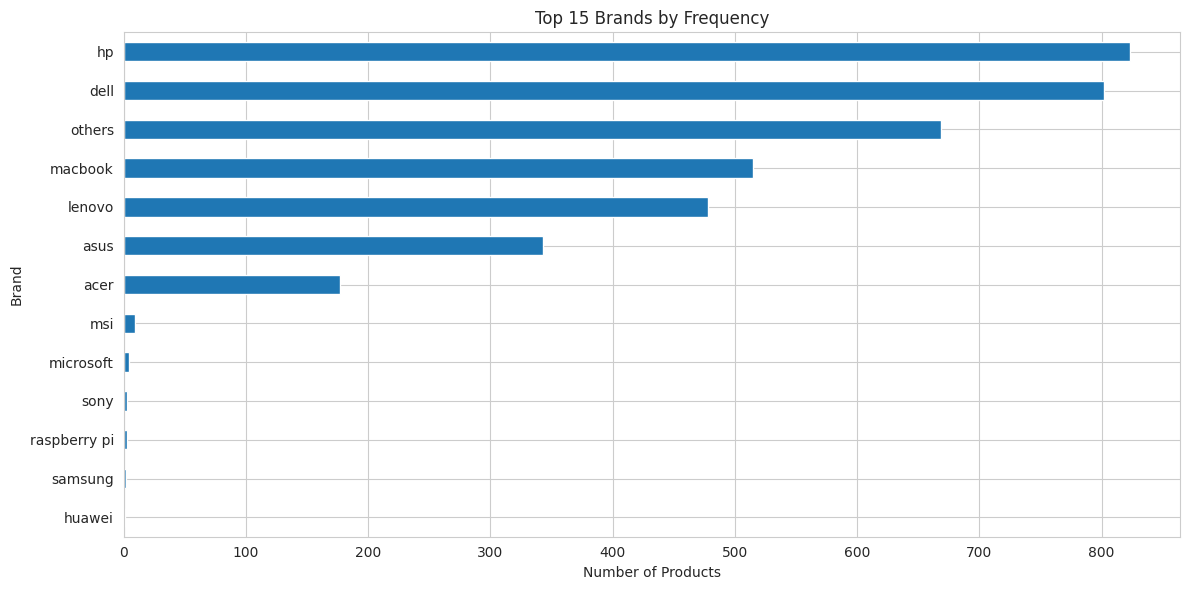

In [229]:
plt.figure(figsize=(12, 6))

brand_counts.head(15).sort_values().plot(kind='barh')

plt.title("Top 15 Brands by Frequency")
plt.xlabel("Number of Products")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

In [230]:
processor_counts = df['processor'].value_counts()

print("Processor frequencies:")
display(processor_counts.to_frame(name='Count'))

Processor frequencies:


,Count
processor,
Intel Core i5,2053
Intel Core i3,579
Apple M1,301
Intel Core i7,300
AMD Ryzen 5,235
Apple M2,59
AMD Ryzen 3,54
AMD Ryzen 7,50
Intel Xeon,50


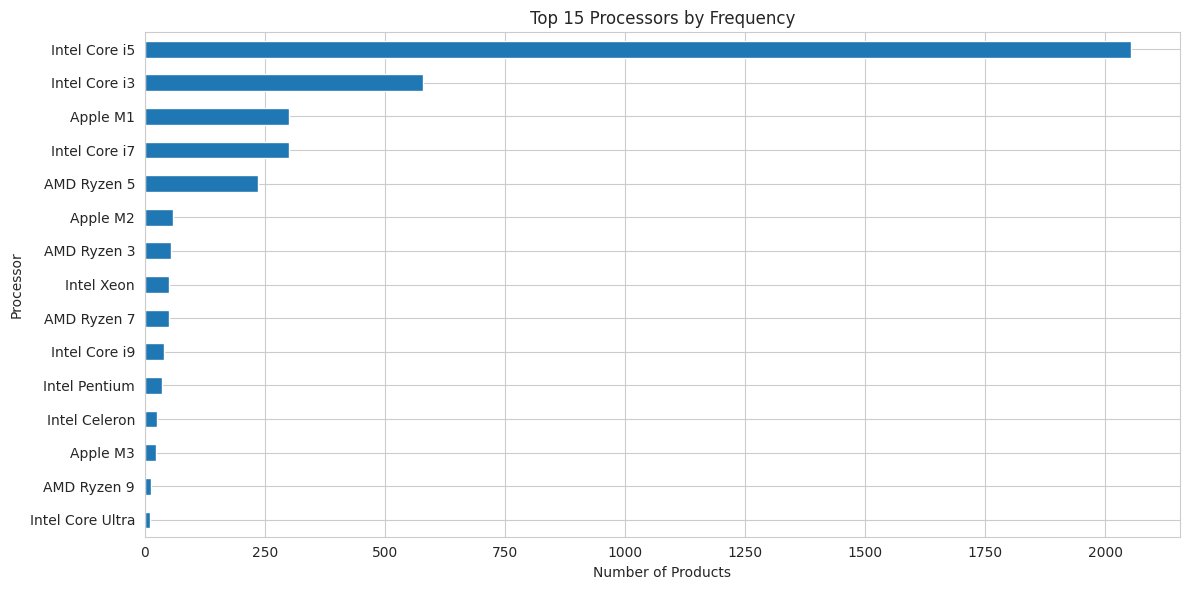

In [231]:
plt.figure(figsize=(12, 6))

processor_counts.head(15).sort_values().plot(kind='barh')

plt.title("Top 15 Processors by Frequency")
plt.xlabel("Number of Products")
plt.ylabel("Processor")
plt.tight_layout()
plt.show()

In [232]:
contingency_table = pd.crosstab(
    df['Brand'],
    df['processor']
)

print("Brand vs Processor contingency table:")
display(contingency_table)

Brand vs Processor contingency table:


processor,AMD Ryzen 3,AMD Ryzen 5,AMD Ryzen 7,AMD Ryzen 9,Apple M1,Apple M2,Apple M3,Intel Celeron,Intel Core Ultra,Intel Core i3,Intel Core i5,Intel Core i7,Intel Core i9,Intel Pentium,Intel Xeon
Brand,,,,,,,,,,,,,,,
acer,0,57,2,0,0,0,0,1,0,19,76,14,3,5,0
asus,8,66,21,4,0,0,0,6,1,145,64,20,5,2,1
dell,13,4,0,0,0,0,0,0,1,97,583,83,2,1,18
hp,28,42,11,1,0,0,0,7,3,125,530,46,0,8,22
huawei,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
lenovo,2,14,7,1,0,0,0,12,2,102,284,32,2,13,7
macbook,0,0,0,0,301,59,24,0,1,1,47,60,22,0,0
microsoft,0,0,0,0,0,0,0,0,0,0,3,1,0,0,0
msi,0,5,0,0,0,0,0,0,0,1,3,0,0,0,0


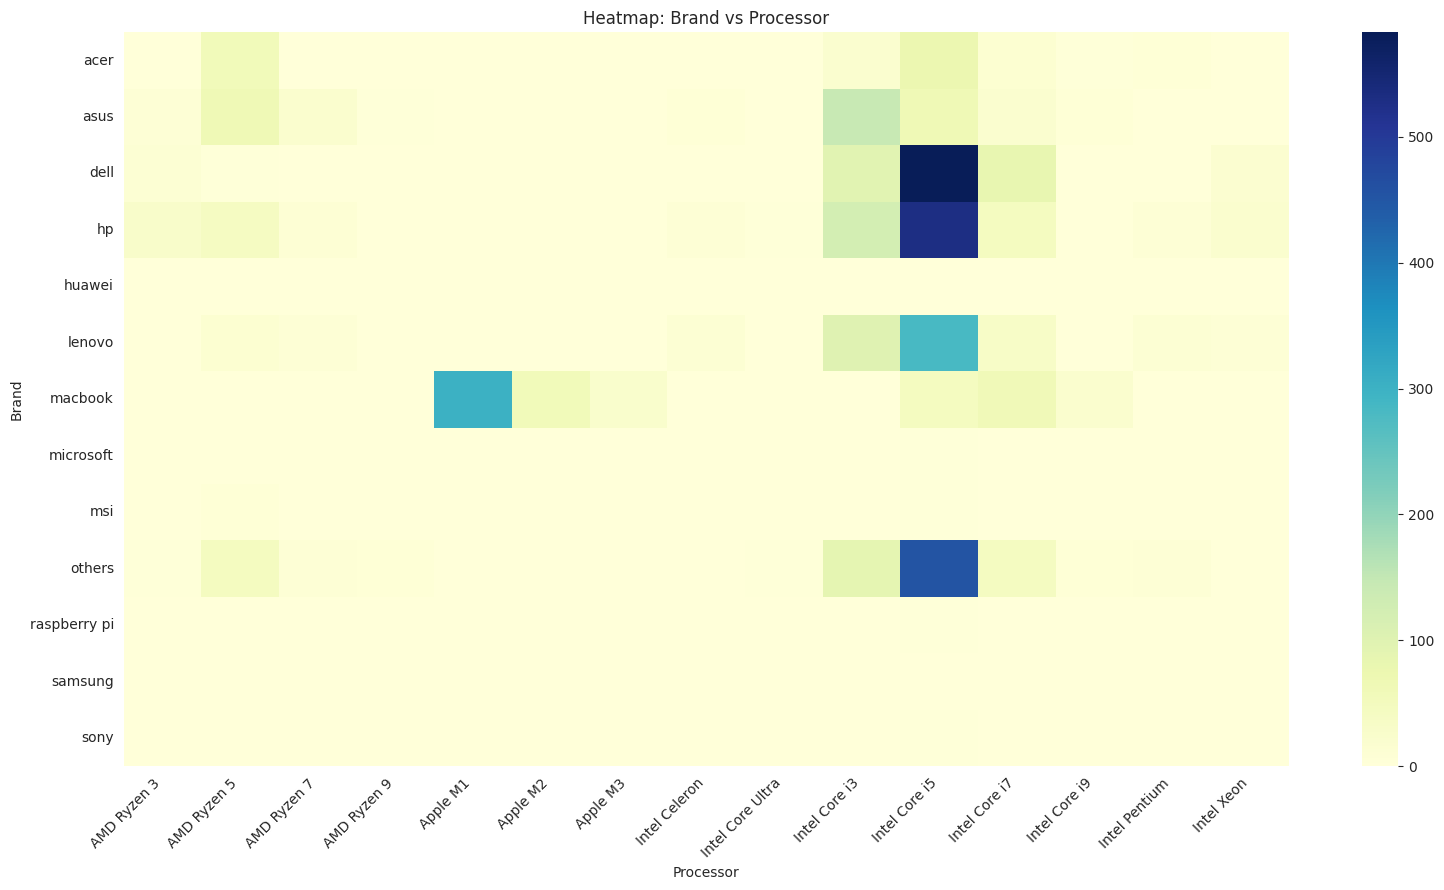

In [233]:
plt.figure(figsize=(16, 9))

sns.heatmap(
    contingency_table,
    annot=False,
    cmap='YlGnBu'
)

plt.title("Heatmap: Brand vs Processor")
plt.xlabel("Processor")
plt.ylabel("Brand")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

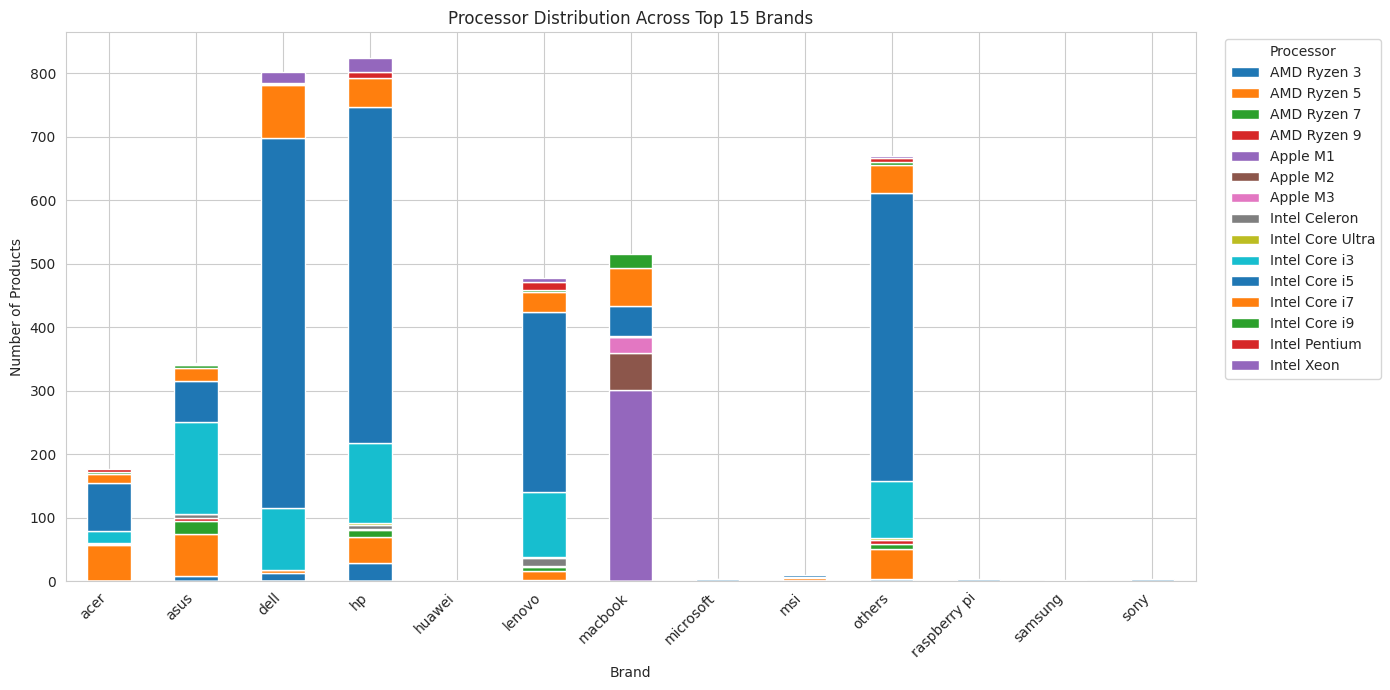

In [234]:
top_brands = df['Brand'].value_counts().head(15).index

brand_processor_counts = pd.crosstab(
    df.loc[df['Brand'].isin(top_brands), 'Brand'],
    df.loc[df['Brand'].isin(top_brands), 'processor']
)

brand_processor_counts.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7)
)

plt.title("Processor Distribution Across Top 15 Brands")
plt.xlabel("Brand")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.legend(
    title="Processor",
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.tight_layout()
plt.show()

In [235]:
brand_processor_percentage = pd.crosstab(
    df['Brand'],
    df['processor'],
    normalize='index'
) * 100

print("Processor percentage distribution within each Brand:")
display(brand_processor_percentage.round(2))

Processor percentage distribution within each Brand:


processor,AMD Ryzen 3,AMD Ryzen 5,AMD Ryzen 7,AMD Ryzen 9,Apple M1,Apple M2,Apple M3,Intel Celeron,Intel Core Ultra,Intel Core i3,Intel Core i5,Intel Core i7,Intel Core i9,Intel Pentium,Intel Xeon
Brand,,,,,,,,,,,,,,,
acer,0.00,32.20,1.13,0.00,0.00,0.00,0.00,0.56,0.00,10.73,42.94,7.91,1.69,2.82,0.00
asus,2.33,19.24,6.12,1.17,0.00,0.00,0.00,1.75,0.29,42.27,18.66,5.83,1.46,0.58,0.29
dell,1.62,0.50,0.00,0.00,0.00,0.00,0.00,0.00,0.12,12.09,72.69,10.35,0.25,0.12,2.24
hp,3.40,5.10,1.34,0.12,0.00,0.00,0.00,0.85,0.36,15.19,64.40,5.59,0.00,0.97,2.67
huawei,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,100.00,0.00,0.00,0.00,0.00
lenovo,0.42,2.93,1.46,0.21,0.00,0.00,0.00,2.51,0.42,21.34,59.41,6.69,0.42,2.72,1.46
macbook,0.00,0.00,0.00,0.00,58.45,11.46,4.66,0.00,0.19,0.19,9.13,11.65,4.27,0.00,0.00
microsoft,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,75.00,25.00,0.00,0.00,0.00
msi,0.00,55.56,0.00,0.00,0.00,0.00,0.00,0.00,0.00,11.11,33.33,0.00,0.00,0.00,0.00


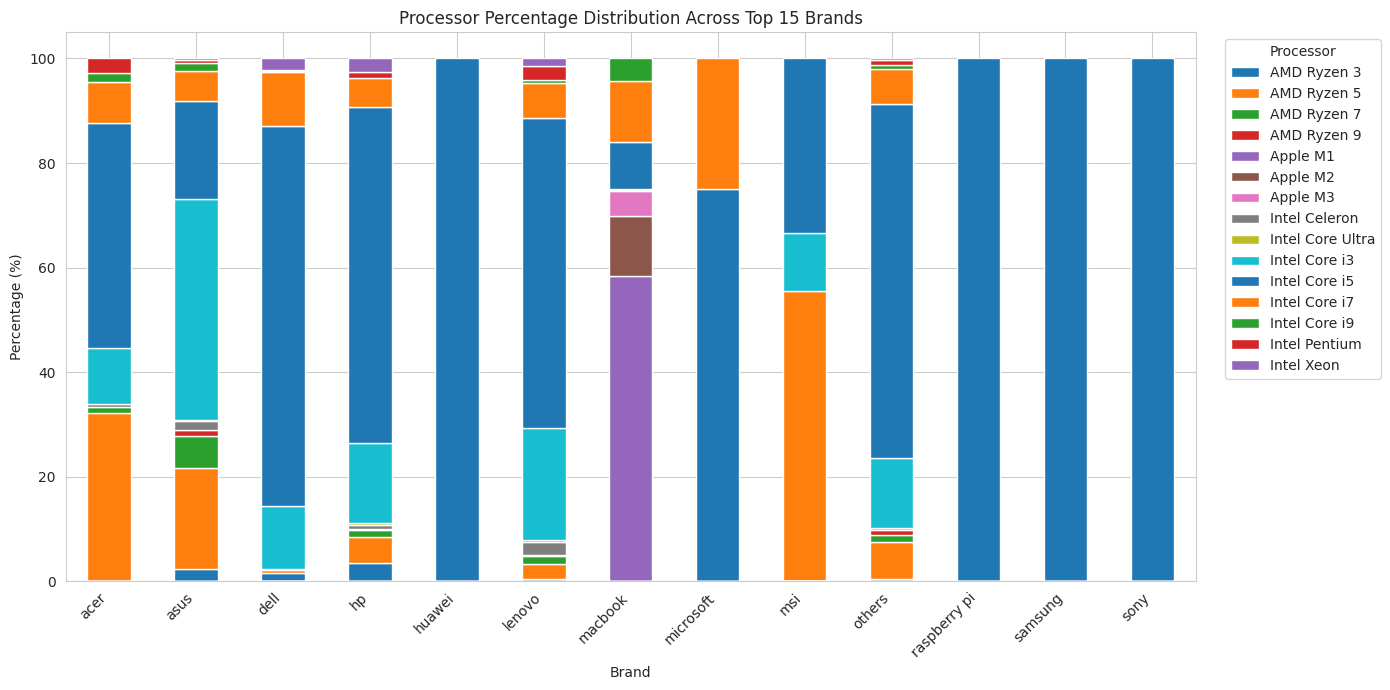

In [236]:
top_brands = df['Brand'].value_counts().head(15).index
top_percentage = brand_processor_percentage.loc[
    brand_processor_percentage.index.isin(top_brands)
]

top_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7)
)

plt.title("Processor Percentage Distribution Across Top 15 Brands")
plt.xlabel("Brand")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha='right')
plt.legend(
    title="Processor",
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.tight_layout()
plt.show()

In [237]:
contingency_table = pd.crosstab(
    df['Brand'],
    df['processor']
)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

print(
    "\nPercentage of expected cells below 5:",
    round((expected < 5).mean() * 100, 2), "%"
)

if p_value < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
    print("There is statistically significant evidence of an association between Brand and processor.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of an association between Brand and processor.")

Chi-Square Statistic: 3882.3235453304633
P-value: 0.0
Degrees of Freedom: 168

Percentage of expected cells below 5: 65.64 %

Conclusion: Reject the null hypothesis.
There is statistically significant evidence of an association between Brand and processor.


In [238]:
n = contingency_table.to_numpy().sum()
rows, cols = contingency_table.shape

if n > 0 and min(rows - 1, cols - 1) > 0:
    cramers_v = np.sqrt(
        chi2 / (n * min(rows - 1, cols - 1))
    )

    print("Cramér's V:", round(cramers_v, 4))

    if cramers_v < 0.1:
        print("Interpretation: Very weak association.")
    elif cramers_v < 0.3:
        print("Interpretation: Weak association.")
    elif cramers_v < 0.5:
        print("Interpretation: Moderate association.")
    elif cramers_v < 0.7:
        print("Interpretation: Strong association.")
    else:
        print("Interpretation: Very strong association.")
else:
    print("Cramér's V cannot be calculated for this table.")

Cramér's V: 0.2907
Interpretation: Weak association.


In [239]:
data.sample(2)

,Price,Brand,Type,Has_Warranty,RAM_GB,RAM_missing,ROM_GB,ROM_Missing,Screen_Size,Screen_Size_missing,Processor_Tier,Processor_Tier_missing,Storage_Type,processor,Warranty_Days_filled,Warranty_Days_was_missing
3614,26000.0,macbook,Laptop,0,16,1,512.0,1,13.3,1,4.0,1,Unspecified,Apple M1,0,0
2174,15000.0,asus,Laptop,0,16,0,512.0,1,15.6,1,3.0,1,Unspecified,Intel Core i3,0,0


# Bivariate Exploratory Data Analysis (EDA) — `ROM_GB` vs. `Storage_Type`

## 1. Summary Statistics and Data Integrity

- **Purpose:** This section investigates how storage technology categories vary across storage capacities.
- **Data Overview:** The code counts ROM capacities, creates a capacity-by-storage-type contingency table, and computes the percentage distribution of storage type within each capacity.
- **Category Note:** Some ROM capacities or storage types may be uncommon. Sparse combinations should be reviewed before drawing strong conclusions from statistical tests.

## 2. Visualization Analysis

- **Frequency Chart:** Shows the frequency of each ROM capacity.
- **Contingency Heatmap:** Displays the number of products for each ROM-capacity/storage-type combination.
- **Stacked Count Chart:** Compares absolute storage-type counts across ROM capacities.
- **Stacked Percentage Chart:** Compares storage-type proportions within each ROM capacity, helping separate composition differences from group-size differences.

## 3. Statistical Analysis — Chi-Square Test and Cramér's V

- **Chi-square statistic:** Approximately `2307.35`.
- **p-value:** Reported as `0.0` by numerical underflow; this indicates an extremely small value, not a literal probability of zero.
- **Expected cells below 5:** Approximately `67.27%`.
- **Cramér's V:** Approximately `0.3881`, classified as a moderate association by the notebook's thresholds.

The association between ROM capacity and storage type appears moderate according to Cramér's V. However, 67.27% of expected cells are below 5, so the chi-square approximation is questionable and the p-value should be interpreted cautiously.

## 4. Key Takeaways and Data Modeling Guidance

- Storage technology composition varies across ROM capacities.
- Use within-capacity percentages to compare categories fairly when counts differ.
- Inspect uncommon capacities and storage types; combine categories only when substantively justified.
- Consider `ROM_GB` and `Storage_Type` together as candidate model features, then validate their contribution and potential redundancy.

## 5. Conclusion

The analysis indicates a moderate association between `ROM_GB` and `Storage_Type` based on Cramér's V. Because many expected cell counts are small, the chi-square significance should be treated cautiously; the contingency and percentage charts remain useful descriptive tools.

In [240]:
data[['ROM_GB', 'Storage_Type']].head()

,ROM_GB,Storage_Type
0,256.0,SSD
1,256.0,Unspecified
2,500.0,SSD
3,256.0,SSD
4,512.0,Unspecified


In [241]:
df = data[['ROM_GB', 'Storage_Type']].copy()

In [242]:
rom_counts = df['ROM_GB'].value_counts()

print("ROM capacity frequencies:")
display(rom_counts.to_frame(name='Count'))

ROM capacity frequencies:


,Count
ROM_GB,
256.0,1380
512.0,935
500.0,638
1024.0,319
128.0,171
365.0,149
320.0,51
378.0,50
238.0,30


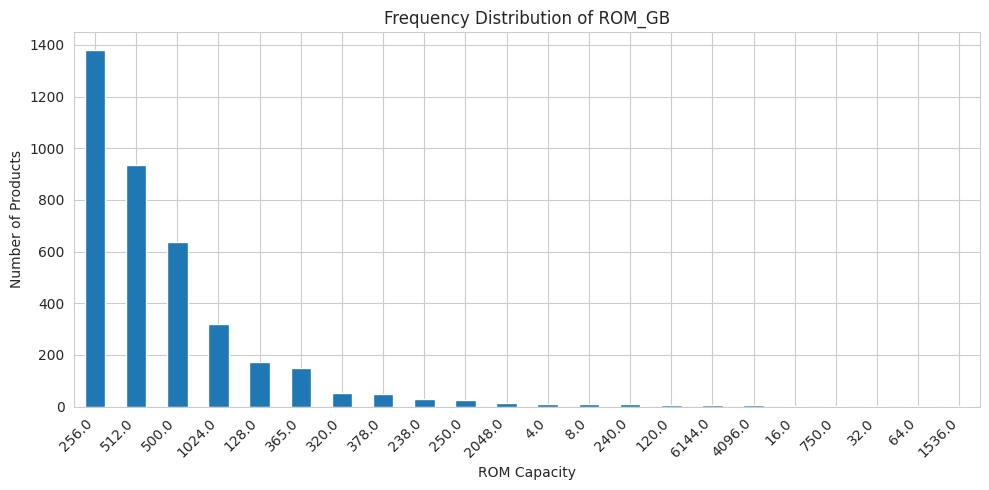

In [243]:
plt.figure(figsize=(10, 5))
rom_counts.plot(kind='bar')

plt.title("Frequency Distribution of ROM_GB")
plt.xlabel("ROM Capacity")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [244]:
contingency_table = pd.crosstab(
    df['ROM_GB'],
    df['Storage_Type']
)

display(contingency_table)

Storage_Type,HDD,NVMe,SSD,Unspecified,eMMC
ROM_GB,,,,,
4.0,0,1,1,10,0
8.0,2,0,4,5,0
16.0,0,1,2,1,0
32.0,0,0,0,3,0
64.0,0,0,0,2,1
120.0,1,0,7,0,0
128.0,1,1,129,38,2
238.0,0,0,9,21,0
240.0,0,0,10,0,0


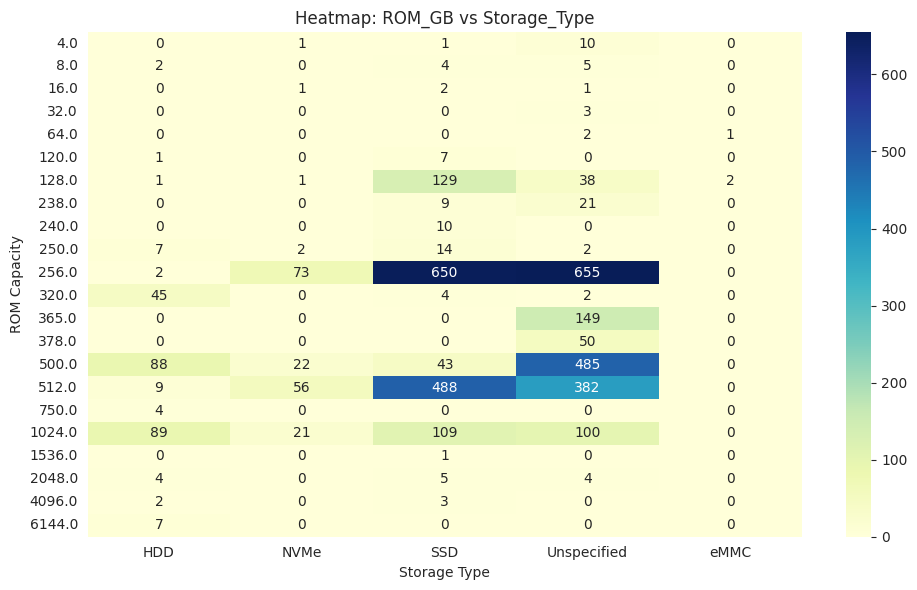

In [245]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    contingency_table,
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title("Heatmap: ROM_GB vs Storage_Type")
plt.xlabel("Storage Type")
plt.ylabel("ROM Capacity")
plt.tight_layout()
plt.show()

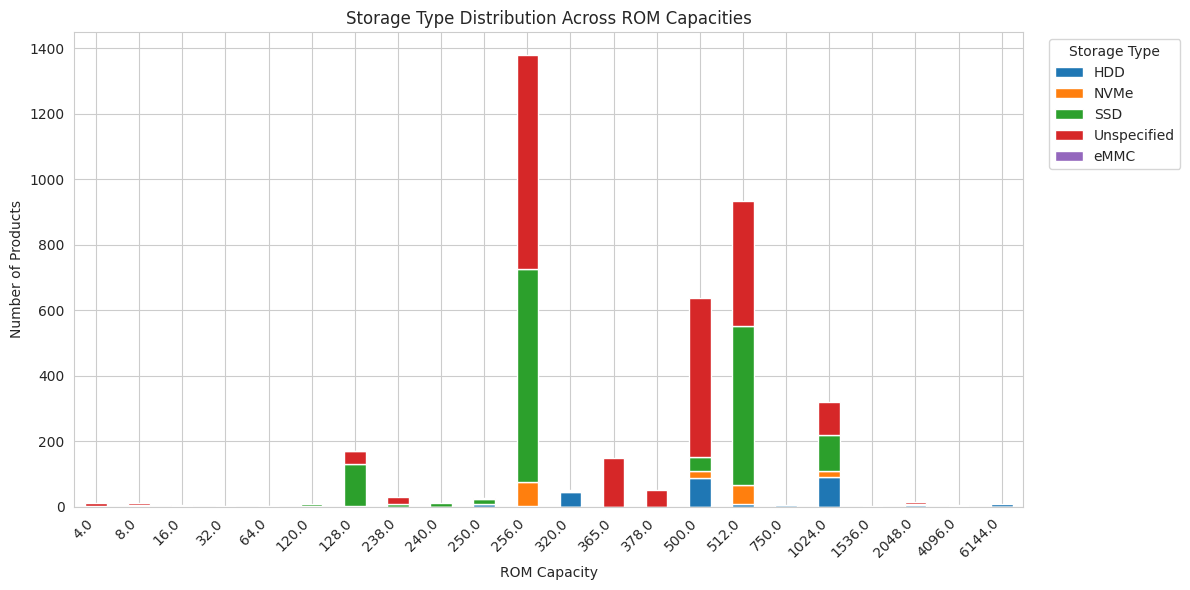

In [246]:
contingency_table.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title("Storage Type Distribution Across ROM Capacities")
plt.xlabel("ROM Capacity")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.legend(
    title="Storage Type",
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.tight_layout()
plt.show()

In [247]:
rom_storage_percentage = pd.crosstab(
    df['ROM_GB'],
    df['Storage_Type'],
    normalize='index'
) * 100

print("Storage Type percentage distribution within each ROM capacity:")
display(rom_storage_percentage.round(2))

Storage Type percentage distribution within each ROM capacity:


Storage_Type,HDD,NVMe,SSD,Unspecified,eMMC
ROM_GB,,,,,
4.0,0.00,8.33,8.33,83.33,0.00
8.0,18.18,0.00,36.36,45.45,0.00
16.0,0.00,25.00,50.00,25.00,0.00
32.0,0.00,0.00,0.00,100.00,0.00
64.0,0.00,0.00,0.00,66.67,33.33
120.0,12.50,0.00,87.50,0.00,0.00
128.0,0.58,0.58,75.44,22.22,1.17
238.0,0.00,0.00,30.00,70.00,0.00
240.0,0.00,0.00,100.00,0.00,0.00


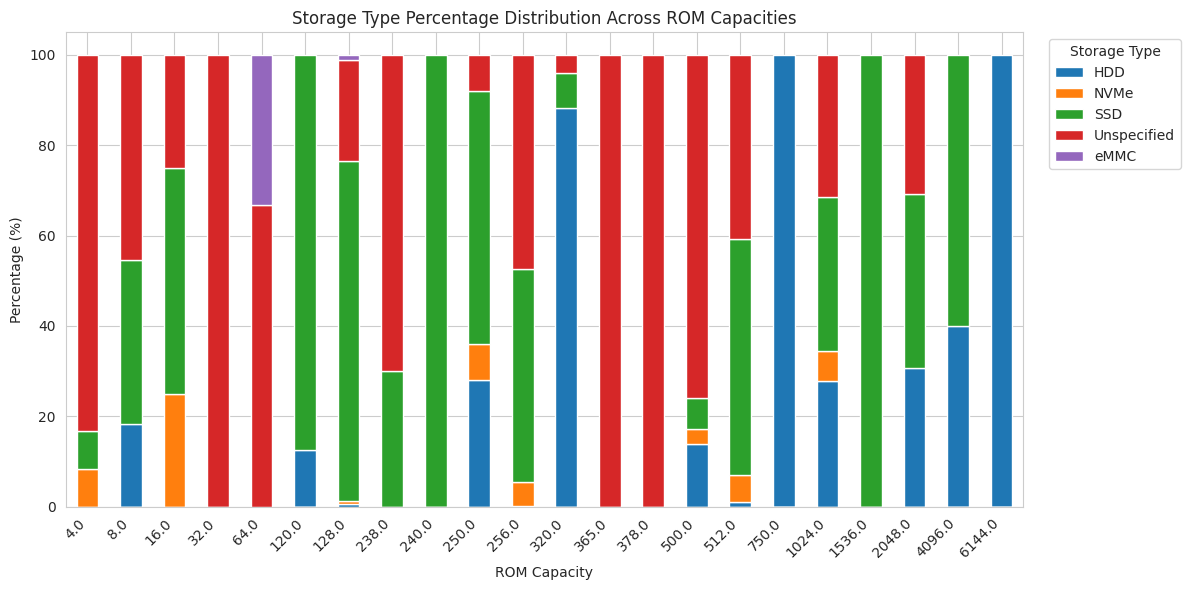

In [248]:
rom_storage_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title("Storage Type Percentage Distribution Across ROM Capacities")
plt.xlabel("ROM Capacity")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45, ha='right')
plt.legend(
    title="Storage Type",
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.tight_layout()
plt.show()

In [249]:
contingency_table = pd.crosstab(
    df['ROM_GB'],
    df['Storage_Type']
)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)

print("Chi-Square Statistic:", chi2)
print("P-value:", p_value)
print("Degrees of Freedom:", dof)

print(
    "\nPercentage of expected cells below 5:",
    round((expected < 5).mean() * 100, 2), "%"
)

if p_value < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
    print("There is statistically significant evidence of an association between ROM_GB and Storage_Type.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of an association between ROM_GB and Storage_Type.")

Chi-Square Statistic: 2307.3466717479755
P-value: 0.0
Degrees of Freedom: 84

Percentage of expected cells below 5: 67.27 %

Conclusion: Reject the null hypothesis.
There is statistically significant evidence of an association between ROM_GB and Storage_Type.


In [250]:
n = contingency_table.to_numpy().sum()
rows, cols = contingency_table.shape

if n > 0 and min(rows - 1, cols - 1) > 0:
    cramers_v = np.sqrt(
        chi2 / (n * min(rows - 1, cols - 1))
    )

    print("Cramér's V:", round(cramers_v, 4))

    if cramers_v < 0.1:
        print("Interpretation: Very weak association.")
    elif cramers_v < 0.3:
        print("Interpretation: Weak association.")
    elif cramers_v < 0.5:
        print("Interpretation: Moderate association.")
    elif cramers_v < 0.7:
        print("Interpretation: Strong association.")
    else:
        print("Interpretation: Very strong association.")
else:
    print("Cramér's V cannot be calculated for this table.")

Cramér's V: 0.3881
Interpretation: Moderate association.
